[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BrianAranda/Informes_FDPI/blob/lab1/code/ejercicio_1/ejercicio1_areas_urbanas_v2.ipynb)

# Actividad 1 (v2): Identificación de Áreas Urbanas y Civiles — Posadas, Garupá e Itaembé
**Cátedra:** Fundamentos del Procesamiento Digital de Imágenes (IC-527) — Facultad de Ingeniería, UNaM.
**Datos:** Landsat 9 OLI, escena 224/079, 3 de abril de 2024 (Collection 2, Level 2, reflectancia de superficie, 0 % de nubes).

**Objetivo de la consigna:** resaltar áreas construidas y urbanizadas (edificios, rutas e infraestructura civil) eligiendo y justificando bandas para una composición RGB, aplicando mejora de contraste si hace falta, y analizando los resultados.

**Estrategia de este notebook:** decidir *empíricamente* (no por convención) qué composición, qué espacio de color y qué realce de contraste separan mejor lo urbano del resto, siguiendo el criterio del *Notebook 2 de cátedra (Espacios de Color: Criterio Empírico de Selección)*.

| Sección | Contenido |
|---|---|
| 0 | Entorno, carga de bandas (B1 a B7) y recorte georreferenciado |
| 1 | **Firmas espectrales:** reflectancia media y desvío de agua, urbanización, vegetación y suelo descampado en las bandas 1 a 7, a partir de zonas de muestra elegidas sobre la imagen |
| 2 | Etiquetas de referencia independientes: OpenStreetMap en 3 clases (urbano / vegetación / agua) |
| 3 | Composiciones: 6 permutaciones de {6, 5, 4} (**principal**), **7-6-4** (secundaria, en paralelo) y 4-3-2 (referencia) |
| 4 | Mejora de contraste: sin realce, estiramiento, ecualización global y CLAHE |
| 5 | Separabilidad empírica: composiciones × espacios de color (RGB, HSV, HLS, Gris, LAB) × realce |
| 6 | Histogramas por espacio de color y por clase |
| 7 | Nubes de color 3D (estática e interactiva rotatoria) |
| 8 | Segmentación por umbralización (Otsu, caja por percentiles, sliders, NDBI) |
| 9 | Agrupamiento no supervisado (K-Means y GMM) |
| 10 | Validación contra OpenStreetMap |
| 11 | Conclusiones |

## Pipeline general (resumen del notebook)

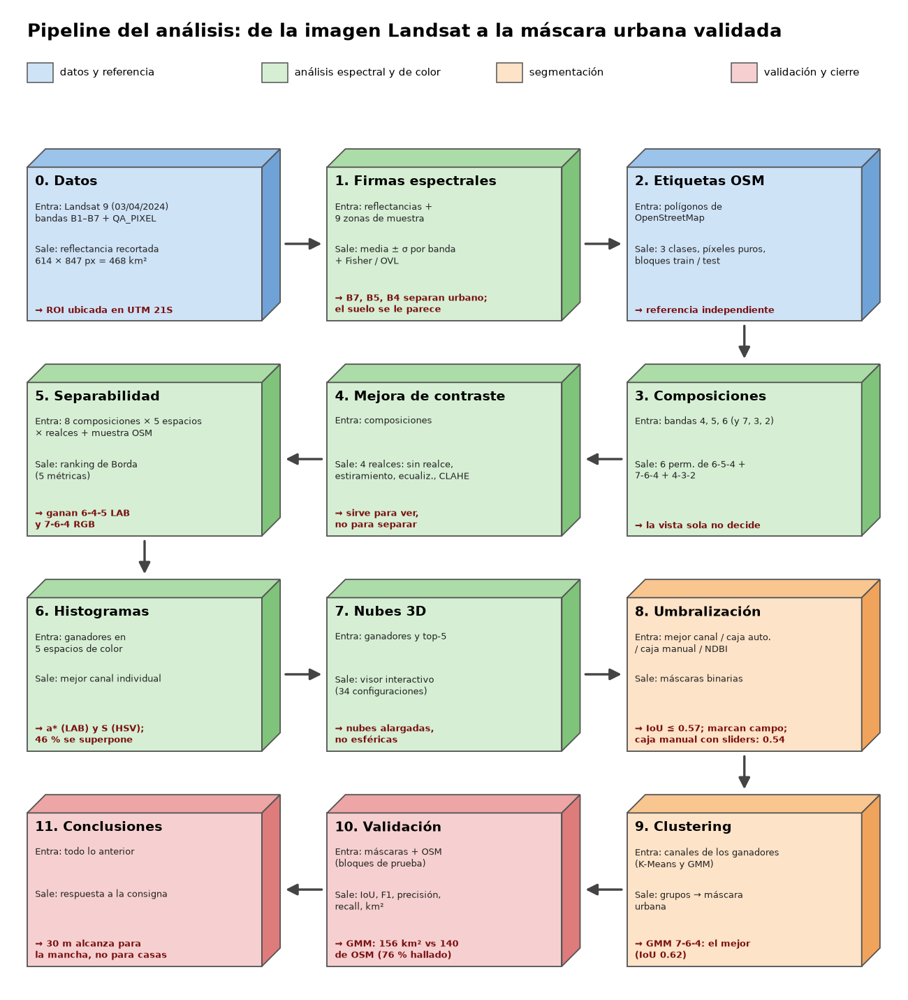

| # | Etapa | Entra | Sale | Conclusión principal |
|---|---|---|---|---|
| 0 | **Datos** | escena Landsat 9 del 03/04/2024 (bandas B1–B7 de reflectancia y máscara de calidad `QA_PIXEL`) y las coordenadas de la región | reflectancias recortadas de 614 × 847 píxeles (≈ 468 km²), ubicadas con la proyección UTM 21S | la región se recorta desde coordenadas, no con índices a mano |
| 1 | **Firmas espectrales** | reflectancias + 9 zonas de muestra elegidas sobre la imagen | reflectancia media ± desvío por banda y clase; Fisher y OVL banda por banda | lo urbano es lo más brillante en el visible y el SWIR 2. B7, B5 y B4 lo separan de la vegetación; el **suelo descampado** es su principal confusión |
| 2 | **Etiquetas OSM** | polígonos de OpenStreetMap | máscara de 3 clases (urbano, vegetación, agua), píxeles puros y bloques de entrenamiento y prueba | referencia independiente de la imagen, para medir sin razonamiento circular |
| 3 | **Composiciones** | bandas 4, 5, 6 (consigna), 7 y 3-2 | 6 permutaciones de 6-5-4, la 7-6-4 y la 4-3-2 | a la vista varias "funcionan"; la decisión requiere métricas |
| 4 | **Mejora de contraste** | composiciones | 4 versiones: sin realce, estiramiento, ecualización y CLAHE | el realce es imprescindible para **ver**, pero no mejora la separación |
| 5 | **Separabilidad** | 8 composiciones × 5 espacios de color × realces, y la muestra de píxeles OSM | ranking de 5 métricas (puesto promedio) | ganan **6-4-5 en LAB** (principal) y **7-6-4 en RGB** (secundaria); en RGB las 6 permutaciones empatan |
| 6 | **Histogramas** | ganadores en los 5 espacios | mejor canal individual de cada ganador | a\* (LAB) y S (HSV), pero ~46 % de la distribución se superpone |
| 7 | **Nubes 3D** | ganadores y mejores del ranking | visor 3D interactivo con 34 configuraciones | las nubes son alargadas y no esféricas, lo que explica las métricas |
| 8 | **Umbralización** | un canal (Otsu), una caja de rangos automática o **manual (sliders)**, o el índice NDBI | máscaras binarias urbano / no urbano | IoU ≤ 0.57: encuentran la ciudad, pero también marcan campo; la caja manual con sliders llega a 0.54 y la guiada por los histogramas, a 0.53 |
| 9 | **Clustering** | los canales de los ganadores (K-Means y GMM) | grupos de píxeles; los mayoritariamente urbanos forman la máscara | el **GMM sobre 7-6-4** es el mejor método (IoU 0.62) |
| 10 | **Validación** | todas las máscaras y OSM (bloques de prueba) | IoU, F1, precisión, recall y km² | el GMM 7-6-4 estima 156 km² contra 140 de OSM y halla el 76 % de su mancha urbana |
| 11 | **Conclusiones** | todo lo anterior | respuesta a la consigna | las bandas 4-5-6 cumplen; la 7-6-4 rinde mejor. 30 m alcanza para la mancha urbana, no para viviendas |

Cada sección termina con su **conclusión** y una **bitácora**: una tabla con las decisiones tomadas, por qué, qué alternativa se descartó y con qué criterio.

## 0. Entorno y datos

In [1]:
# 0.1 Entorno: Google Colab o local
import os
import sys
import subprocess

if "google.colab" in sys.modules:
    RAMA = "lab1"
    REPO = "https://github.com/BrianAranda/Informes_FDPI.git"
    DESTINO = "/content/Informes_FDPI"
    if not os.path.isdir(DESTINO):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RAMA, REPO, DESTINO], check=True)
    os.chdir(f"{DESTINO}/code/ejercicio_1")
else:
    for c_dir in [os.path.join(os.getcwd(), "Informes_FDPI", "code", "ejercicio_1"), os.getcwd()]:
        if os.path.exists(os.path.join(c_dir, "ejercicio1_areas_urbanas_v2.ipynb")):
            os.chdir(c_dir)
            break
print("Directorio de trabajo:", os.getcwd())

Directorio de trabajo: G:\Other computers\notas_unam\UNAM FACULTAD\5to Anio\IC527 - Fundamentos del Procesamiento Digitial de Imagenes\1 - informes\Informes_FDPI\code\ejercicio_1


In [2]:
# 0.2 Librerías, constantes y descarga de respaldo de los datos
import json
import time
import zipfile
import warnings
from itertools import permutations

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from skimage import exposure
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)  # silencia avisos de etiquetas GeoTIFF
T_INICIO = time.time()
SEMILLA = 42

IMG_DIR = "imagenes_v2"
CTX_DIR = "context"
DATA_DIR = os.path.join(CTX_DIR, "Landsat_Data", "Sur_Misiones_20240403")
ESCENA = "LC09_L2SP_224079_20240403_20240404_02_T1"
os.makedirs(IMG_DIR, exist_ok=True)

if not os.path.isdir(DATA_DIR):
    import gdown
    zip_path = os.path.join(CTX_DIR, "Sur_Misiones_20240403.zip")
    os.makedirs(os.path.dirname(DATA_DIR), exist_ok=True)
    gdown.download("https://drive.google.com/uc?id=1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT", zip_path, quiet=False)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(os.path.dirname(DATA_DIR))
print("Datos Landsat en:", DATA_DIR)

# Colores fijos de las clases de referencia (se usan en todo el notebook)
CLASES = {1: "urbano", 2: "vegetación", 3: "agua"}
COLOR_CLASE = {1: "#d62728", 2: "#2ca02c", 3: "#1f77b4"}

# Nombres de columnas para mostrar: ↑ = mayor es mejor, ↓ = menor es mejor
FLECHAS = {"Fisher": "Fisher ↑", "OVL": "OVL ↓", "Silhouette": "Silhouette ↑", "JM": "JM urb–veg ↑",
           "JM urb-agua": "JM urb–agua ↑", "kNN": "k-NN ↑", "Puesto promedio": "Puesto promedio ↓",
           "contraste RMS": "contraste RMS ↑", "entropía (bits)": "entropía (bits) ↑"}
LEYENDA = "↑ mayor es mejor · ↓ menor es mejor"

def con_flechas(df):
    """Renombra columnas de métricas agregando ↑/↓ (sólo para mostrar y exportar)."""
    nuevos = {}
    for col in df.columns:
        if col in FLECHAS:
            nuevos[col] = FLECHAS[col]
        elif col.startswith(("IoU", "F1", "Precisión", "Recall", "exactitud")):
            nuevos[col] = f"{col} ↑"
        elif "(s)" in col:
            nuevos[col] = f"{col} ↓"
    return df.rename(columns=nuevos)

Datos Landsat en: context\Landsat_Data\Sur_Misiones_20240403


### 0.3 Recorte georreferenciado de la región de interés

La escena viene proyectada en **UTM zona 21 Sur (WGS84)** con píxeles de 30 m. En lugar de escribir a mano las filas y columnas del recorte, se proyectan las coordenadas geográficas pedidas a UTM (proyección transversa de Mercator, serie de Krüger) y se ubican en la grilla a partir de la esquina superior izquierda que informa el archivo de metadatos `MTL`:

- Esquina UL: $E_0 = 549\,300$ m, $N_0 = -2\,918\,100$ m (Landsat usa el norte sin el falso norte de 10 000 km).
- $\text{fila} = (N_0 - N) / 30$, $\quad \text{columna} = (E - E_0) / 30$.

La misma función se usa en la sección 2 para rasterizar los polígonos de OpenStreetMap, así que imagen y etiquetas quedan **alineadas en la misma grilla**. La grilla UTM está rotada unos 7 píxeles respecto de las líneas de latitud y longitud dentro de la ROI. Por eso una interpolación lineal de lat/lon introduciría un desfase de hasta ~200 m.

In [3]:
# 0.3 Proyección lat/lon -> UTM 21S -> píxel, y carga de bandas recortadas
def latlon_a_utm(lat, lon, lon0=-57.0, k0=0.9996):
    """Transversa de Mercator (elipsoide WGS84, serie de Krüger). Devuelve (Este, Norte) sin falso norte."""
    a, f = 6378137.0, 1 / 298.257223563
    n = f / (2 - f)
    A = a / (1 + n) * (1 + n**2 / 4 + n**4 / 64)
    alfa = [n / 2 - 2 * n**2 / 3 + 5 * n**3 / 16, 13 * n**2 / 48 - 3 * n**3 / 5, 61 * n**3 / 240]
    phi, lam = np.radians(lat), np.radians(np.asarray(lon) - lon0)
    e = 2 * np.sqrt(n) / (1 + n)
    t = np.sinh(np.arctanh(np.sin(phi)) - e * np.arctanh(e * np.sin(phi)))
    xi, eta = np.arctan2(t, np.cos(lam)), np.arctanh(np.sin(lam) / np.sqrt(1 + t**2))
    E = eta + sum(al * np.cos(2 * j * xi) * np.sinh(2 * j * eta) for j, al in enumerate(alfa, 1))
    N = xi + sum(al * np.sin(2 * j * xi) * np.cosh(2 * j * eta) for j, al in enumerate(alfa, 1))
    return 500000 + k0 * A * E, k0 * A * N

UL_X, UL_Y, PIXEL = 549300.0, -2918100.0, 30.0  # del archivo MTL

def latlon_a_pixel(lat, lon):
    E, N = latlon_a_utm(lat, lon)
    return (UL_Y - N) / PIXEL, (E - UL_X) / PIXEL

LAT_N, LAT_S, LON_O, LON_E = -27.3388, -27.5030, -56.0611, -55.8027
f_no, c_no = latlon_a_pixel(LAT_N, LON_O)
f_se, c_se = latlon_a_pixel(LAT_S, LON_E)
R1, R2, C1, C2 = int(round(f_no)), int(round(f_se)), int(round(c_no)), int(round(c_se))

def read_band(file_path):
    """Lee una banda Landsat GeoTIFF (uint16)."""
    band = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)
    if band is None:
        raise ValueError(f"Error al leer el archivo: {file_path}")
    return band

# Las bandas completas pesan ~120 MB cada una: el recorte se guarda en caché (npz) para que las
# ejecuciones siguientes no tengan que releer los GeoTIFF.
ROI_CACHE = os.path.join(CTX_DIR, f"roi_B1-B7_QA_{R1}_{R2}_{C1}_{C2}.npz")
if os.path.exists(ROI_CACHE):
    DN = dict(np.load(ROI_CACHE))
else:
    DN = {f"B{b}": read_band(os.path.join(DATA_DIR, f"{ESCENA}_SR_B{b}.TIF"))[R1:R2, C1:C2] for b in range(1, 8)}
    DN["QA"] = read_band(os.path.join(DATA_DIR, f"{ESCENA}_QA_PIXEL.TIF"))[R1:R2, C1:C2]   # máscara de calidad
    np.savez_compressed(ROI_CACHE, **DN)

# Reflectancia de superficie: rho = DN * 2.75e-5 - 0.2 (factores del MTL, Collection 2 Level 2).
# Los pocos valores negativos (ruido de la corrección atmosférica sobre el agua) se recortan a 0.
REFL = {b: np.clip(DN[f"B{b}"].astype(np.float32) * 2.75e-5 - 0.2, 0, 1) for b in range(1, 8)}

def estirar(banda, p_min=2, p_max=98):
    """Estiramiento lineal con recorte de percentiles (Notebook 10 de cátedra)."""
    lo, hi = np.percentile(banda, (p_min, p_max))
    return (np.clip((banda - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)
H, W = REFL[4].shape
print(f"ROI: filas {R1}:{R2}, columnas {C1}:{C2} -> {H} x {W} píxeles (~{H*30/1000:.1f} km x {W*30/1000:.1f} km)")
print(f"Bandas cargadas: {sorted(REFL)} | t = {time.time() - T_INICIO:.1f} s")

ROI: filas 3540:4154, columnas 1452:2299 -> 614 x 847 píxeles (~18.4 km x 25.4 km)
Bandas cargadas: [1, 2, 3, 4, 5, 6, 7] | t = 0.1 s


## 1. Firmas espectrales: cómo refleja cada cobertura en las bandas 1 a 7

Antes de armar composiciones conviene mirar los datos crudos. La **reflectancia de superficie** es la fracción de la luz solar que refleja el terreno, entre 0 y 1. La curva de reflectancia media de una cobertura en función de la banda es su **firma espectral**. El **desvío estándar** indica cuánto varía esa cobertura de un píxel a otro.

Los datos son la **reflectancia de las bandas 1 a 7 de la escena Landsat 9 del 03/04/2024**, recortada a la región de estudio, sin ningún realce de contraste.

### 1.1 Cómo se eligen las zonas de muestra

Se sigue el método habitual en teledetección, el mismo del notebook de cuerpos de agua del ejercicio 2: se toman **áreas de muestra**, unos pocos rectángulos elegidos sobre la imagen en lugares donde no hay duda de qué cobertura hay.

1. **Qué se busca.** La firma "típica" de cada cobertura, es decir, cuánto refleja en cada banda un píxel que **sin duda** es agua, ciudad, vegetación o suelo.
2. **Dónde mirar.** Sobre la imagen en color natural (4-3-2) se ubican lugares reconocibles:

   | Clase | Zonas |
   |---|---|
   | Agua | el cauce principal del Paraná y la bahía al norte del centro |
   | Urbanización | el **microcentro de Posadas** (manzanas densas, junto a la costanera) y un **barrio residencial arbolado**, para ver la variabilidad de lo urbano |
   | Vegetación | una **plantación o monte** (verde oscuro) y una **pastura** (verde claro) |
   | Suelo descampado | **lotes de tierra colorada** sin cubierta, los parches rosados de la imagen |

3. **Pureza: alejarse de los bordes.** Un píxel de 30 m sobre la orilla mezcla agua y tierra, y uno en el borde de un barrio mezcla techo y monte. Los rectángulos se ubican **dentro** de zonas homogéneas, lejos de cualquier borde.
4. **Tamaño.** Rectángulos de unos **30 × 30 píxeles** (≈ 0.8 km², ~900 píxeles) y al menos **dos por clase**. Así la media y el desvío son estables y reflejan la variabilidad de la clase, no la de un solo lugar.
5. **Verificar con datos, no sólo con el ojo:**
   - **Agua:** se usan sólo los píxeles marcados como agua por la máscara de calidad de Landsat (`QA_PIXEL`, bit 7), que es independiente de nuestra elección.
   - **Resto de las clases:** se descartan los píxeles de agua según esa misma máscara.
   - **Suelo descampado:** se usan sólo los píxeles con **NDVI < 0.3**, donde NDVI = (B5 − B4)/(B5 + B4). En abril casi no hay campos arados, así que los lotes desnudos son chicos y conviene filtrar los píxeles con vegetación del borde.
   - La **tabla de control** muestra, para cada rectángulo, cuántos píxeles quedan, qué porcentaje es agua según QA y su NDVI medio. Valores esperables: agua ≈ −1, suelo < 0.3, vegetación > 0.5.
6. **Mostrar dónde se tomaron.** La figura de ubicación dibuja los rectángulos sobre la imagen, para que cualquiera pueda comprobar la elección.

**Limitación.** La elección es subjetiva y muestra zonas **típicas**, no toda la ciudad. Por eso, desde la sección 2, la separabilidad y la validación se hacen con las etiquetas de OpenStreetMap, que aportan decenas de miles de píxeles independientes del ojo de quien analiza.

Clase,Zona,Filas,Columnas,Píxeles del rectángulo,Píxeles usados,% agua según QA,NDVI medio,Desvío del NDVI
Agua,"Paraná, cauce principal",290–320,680–710,900,900,100.000,-1.000,0.000
Agua,Bahía al norte del centro,30–50,290–330,800,800,100.000,-0.999,0.004
Urbanización,Microcentro de Posadas,106–136,542–572,900,898,0.222,0.256,0.132
Urbanización,Barrio residencial arbolado,210–240,400–430,900,900,0.000,0.505,0.171
Vegetación,Plantación / monte,370–400,200–230,900,900,0.000,0.853,0.037
Vegetación,Pastura,100–130,40–70,900,900,0.000,0.684,0.043
Suelo descampado,Lote de tierra colorada (sudeste),532–558,672–710,988,166,0.000,0.184,0.058
Suelo descampado,Lote de tierra colorada (oeste),466–486,18–40,440,91,5.909,0.178,0.054
Suelo descampado,Lote de tierra colorada (sur del centro),350–366,334–354,320,65,0.000,0.193,0.060


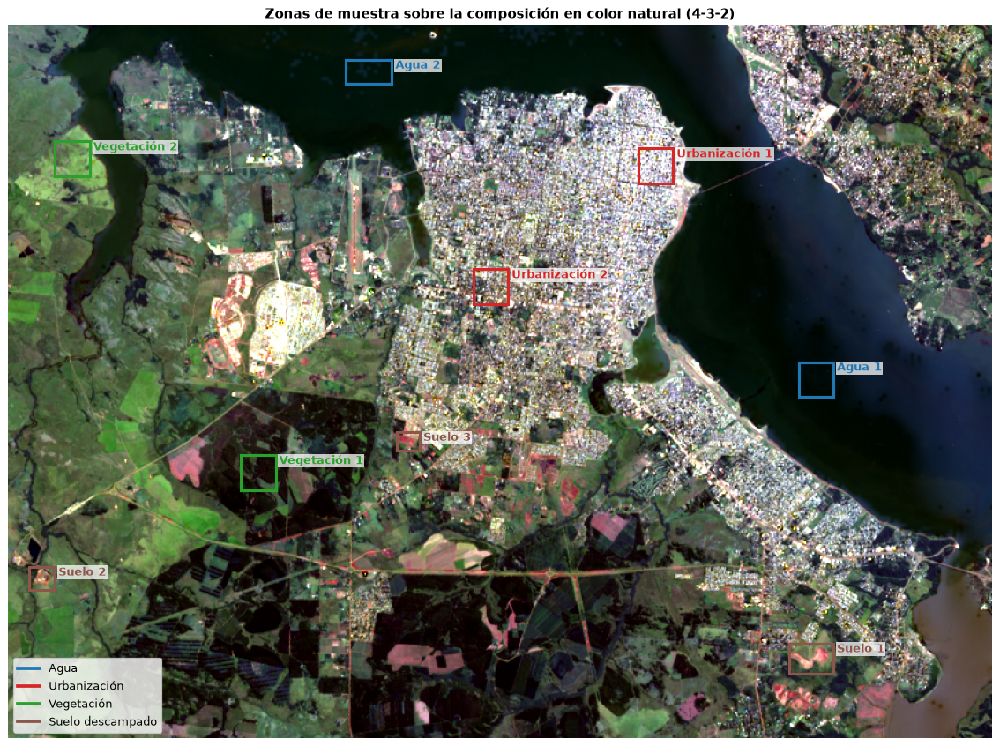

In [4]:
# 1.1 Zonas de muestra: definición y control con QA_PIXEL y NDVI
# Rectángulos en coordenadas del recorte: (fila0, fila1, columna0, columna1)
MUESTRAS = {
    "Agua": [("Paraná, cauce principal", (290, 320, 680, 710)),
             ("Bahía al norte del centro", (30, 50, 290, 330))],
    "Urbanización": [("Microcentro de Posadas", (106, 136, 542, 572)),
                     ("Barrio residencial arbolado", (210, 240, 400, 430))],
    "Vegetación": [("Plantación / monte", (370, 400, 200, 230)),
                   ("Pastura", (100, 130, 40, 70))],
    "Suelo descampado": [("Lote de tierra colorada (sudeste)", (532, 558, 672, 710)),
                         ("Lote de tierra colorada (oeste)", (466, 486, 18, 40)),
                         ("Lote de tierra colorada (sur del centro)", (350, 366, 334, 354))],
}
COLOR_MUESTRA = {"Agua": COLOR_CLASE[3], "Urbanización": COLOR_CLASE[1], "Vegetación": COLOR_CLASE[2],
                 "Suelo descampado": "#8c564b"}
ESTILO_MUESTRA = {"Agua": dict(ls="-", marker="o"), "Urbanización": dict(ls="--", marker="s"),
                  "Vegetación": dict(ls="-.", marker="D"), "Suelo descampado": dict(ls=":", marker="^")}

AGUA_QA = ((DN["QA"] >> 7) & 1) == 1                       # agua según la máscara de calidad de Landsat
NDVI = (REFL[5] - REFL[4]) / (REFL[5] + REFL[4] + 1e-6)

def mascara_muestra(clase, rect):
    """Píxeles del rectángulo que se usan para la clase, con los filtros de control."""
    f0, f1, c0, c1 = rect
    m = np.zeros((H, W), bool)
    m[f0:f1, c0:c1] = True
    m &= AGUA_QA if clase == "Agua" else ~AGUA_QA
    if clase == "Suelo descampado":
        m &= NDVI < 0.3
    return m

filas_control, MASCARA_MUESTRA = [], {}
for clase, zonas in MUESTRAS.items():
    MASCARA_MUESTRA[clase] = np.zeros((H, W), bool)
    for nombre, (f0, f1, c0, c1) in zonas:
        m = mascara_muestra(clase, (f0, f1, c0, c1))
        MASCARA_MUESTRA[clase] |= m
        filas_control.append({"Clase": clase, "Zona": nombre, "Filas": f"{f0}–{f1}", "Columnas": f"{c0}–{c1}",
                              "Píxeles del rectángulo": (f1 - f0) * (c1 - c0), "Píxeles usados": int(m.sum()),
                              "% agua según QA": 100 * AGUA_QA[f0:f1, c0:c1].mean(),
                              "NDVI medio": NDVI[m].mean(), "Desvío del NDVI": NDVI[m].std()})
display(pd.DataFrame(filas_control).style.format(precision=3).hide(axis="index"))

# Figura de ubicación de las zonas de muestra sobre la imagen en color natural
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(13, 9.5), dpi=90)
ax.imshow(np.dstack([estirar(REFL[b]) for b in (4, 3, 2)]))
for clase, zonas in MUESTRAS.items():
    for k, (nombre, (f0, f1, c0, c1)) in enumerate(zonas, 1):
        ax.add_patch(Rectangle((c0, f0), c1 - c0, f1 - f0, fill=False, ec=COLOR_MUESTRA[clase], lw=2.5))
        ax.text(c1 + 3, f0, f"{clase.split()[0]} {k}", color=COLOR_MUESTRA[clase], fontsize=10, fontweight="bold",
                va="top", bbox=dict(fc="white", alpha=0.75, lw=0, pad=1))
ax.legend(handles=[Line2D([], [], color=COLOR_MUESTRA[c], lw=3, label=c) for c in MUESTRAS], loc="lower left")
ax.set_title("Zonas de muestra sobre la composición en color natural (4-3-2)", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "01_zonas_muestra.png"), bbox_inches="tight")
plt.show()

### 1.2 Firmas espectrales

Reflectancia media de cada clase en cada banda, con su desvío estándar. Las barras y la franja sombreada marcan ± 1 desvío.

| Banda | Nombre | λ (µm) | Qué la afecta |
|---|---|---|---|
| B1 | Costera / aerosol | 0.43–0.45 | dispersión atmosférica, agua poco profunda |
| B2 | Azul | 0.45–0.51 | absorción de clorofila, agua |
| B3 | Verde | 0.53–0.59 | pico de reflectancia de la vegetación en el visible |
| B4 | Rojo | 0.64–0.67 | fuerte absorción de clorofila |
| B5 | NIR | 0.85–0.88 | estructura interna de la hoja: la vegetación refleja mucho |
| B6 | SWIR 1 | 1.57–1.65 | contenido de agua: los materiales secos (hormigón, asfalto, suelo) reflejan más |
| B7 | SWIR 2 | 2.11–2.29 | ídem, con más contraste entre seco y húmedo |

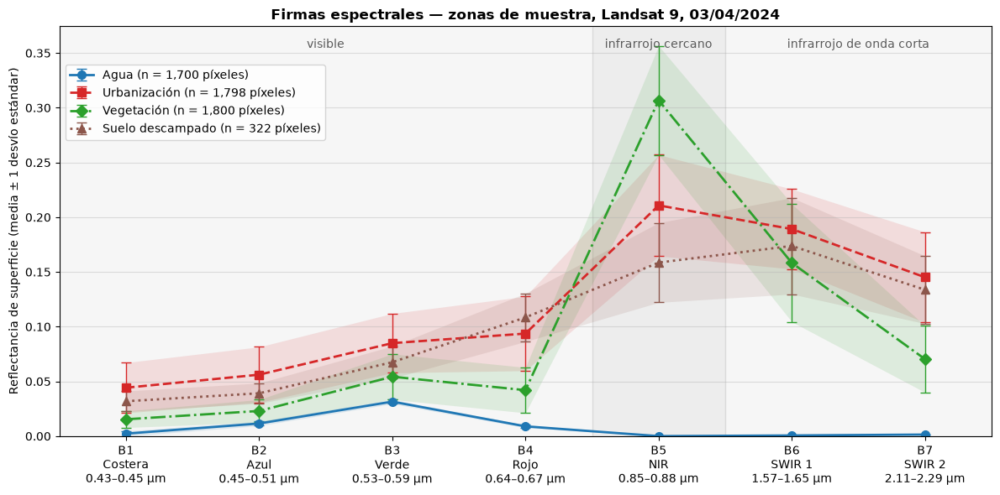

In [5]:
# 1.2 Firmas espectrales B1–B7 por clase (zonas de muestra)
def fisher_ratio(a, b):
    """Razón de Fisher por canal (Notebook 2): (μa − μb)² / (σa² + σb²). Mayor = más separadas."""
    return (a.mean(axis=0) - b.mean(axis=0)) ** 2 / (a.var(axis=0) + b.var(axis=0) + 1e-9)

def overlap_coef(a, b, bins=50):
    """Coeficiente de solapamiento por canal (Notebook 2): masa compartida de los histogramas. Menor = mejor."""
    ovl = []
    for c in range(a.shape[1]):
        lo, hi = min(a[:, c].min(), b[:, c].min()), max(a[:, c].max(), b[:, c].max())
        ha, _ = np.histogram(a[:, c], bins=bins, range=(lo, hi + 1e-6))
        hb, _ = np.histogram(b[:, c], bins=bins, range=(lo, hi + 1e-6))
        ovl.append(np.minimum(ha / ha.sum(), hb / hb.sum()).sum())
    return np.array(ovl)

BANDAS = list(range(1, 8))
NOMBRE_BANDA = {1: "Costera", 2: "Azul", 3: "Verde", 4: "Rojo", 5: "NIR", 6: "SWIR 1", 7: "SWIR 2"}
LAMBDA = {1: "0.43–0.45", 2: "0.45–0.51", 3: "0.53–0.59", 4: "0.64–0.67", 5: "0.85–0.88", 6: "1.57–1.65", 7: "2.11–2.29"}

CUBO = np.stack([REFL[b] for b in BANDAS], axis=-1)                 # (filas, columnas, 7)
FIRMA = {c: CUBO[m] for c, m in MASCARA_MUESTRA.items()}            # píxeles de cada clase, (N, 7)
MEDIA = {c: p.mean(axis=0) for c, p in FIRMA.items()}
DESVIO = {c: p.std(axis=0) for c, p in FIRMA.items()}

fig, ax = plt.subplots(figsize=(12, 6), dpi=100)
x = np.array(BANDAS)
for x0, x1, rotulo in [(0.5, 4.5, "visible"), (4.5, 5.5, "infrarrojo cercano"), (5.5, 7.5, "infrarrojo de onda corta")]:
    ax.axvspan(x0, x1, color="0.5", alpha=0.07 if rotulo != "infrarrojo cercano" else 0.14, zorder=0)
    ax.text((x0 + x1) / 2, 0.97, rotulo, transform=ax.get_xaxis_transform(), ha="center", va="top", color="0.35")
for c in MUESTRAS:
    ax.fill_between(x, MEDIA[c] - DESVIO[c], MEDIA[c] + DESVIO[c], color=COLOR_MUESTRA[c], alpha=0.12, lw=0)
    ax.errorbar(x, MEDIA[c], yerr=DESVIO[c], color=COLOR_MUESTRA[c], lw=2, ms=7, capsize=4, elinewidth=1,
                label=f"{c} (n = {len(FIRMA[c]):,} píxeles)", **ESTILO_MUESTRA[c])
ax.set_xticks(x, [f"B{b}\n{NOMBRE_BANDA[b]}\n{LAMBDA[b]} µm" for b in BANDAS])
ax.set_xlim(0.5, 7.5)
ax.set_ylim(bottom=0)
ax.set_ylabel("Reflectancia de superficie (media ± 1 desvío estándar)")
ax.set_title("Firmas espectrales — zonas de muestra, Landsat 9, 03/04/2024", fontweight="bold")
ax.grid(axis="y", alpha=0.4)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.92))
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "01_firmas_espectrales.png"), bbox_inches="tight")
plt.show()

### 1.3 Tabla resumen de las firmas espectrales

Para cada banda la tabla muestra:
- la reflectancia media ± desvío estándar de cada clase;
- **Δ urb − veg**: la diferencia de medias entre urbanización y vegetación. Si es positiva, lo urbano refleja más;
- la separabilidad de la urbanización frente a cada una de las otras clases, con la razón de Fisher ↑ (mayor es mejor) y el solapamiento OVL ↓ (menor es mejor).

In [6]:
# 1.3 Tabla resumen: reflectancia media ± desvío por clase y separabilidad de la urbanización, banda por banda
u = FIRMA["Urbanización"]
filas_firma = []
for i, b in enumerate(BANDAS):
    fila = {"Banda": f"B{b}", "Nombre": NOMBRE_BANDA[b], "λ (µm)": LAMBDA[b]}
    for c in MUESTRAS:
        fila[f"{c} (μ ± σ)"] = f"{MEDIA[c][i]:.3f} ± {DESVIO[c][i]:.3f}"
    fila["Δ urb − veg"] = MEDIA["Urbanización"][i] - MEDIA["Vegetación"][i]
    filas_firma.append(fila)
df_firmas = pd.DataFrame(filas_firma)
SEPARAB = {}
for otra, corto in [("Vegetación", "veg"), ("Suelo descampado", "suelo"), ("Agua", "agua")]:
    SEPARAB[otra] = (fisher_ratio(u, FIRMA[otra]), overlap_coef(u, FIRMA[otra]))
    df_firmas[f"Fisher urb–{corto} ↑"] = SEPARAB[otra][0]
    df_firmas[f"OVL urb–{corto} ↓"] = SEPARAB[otra][1]
df_firmas.to_csv(os.path.join(IMG_DIR, "tabla_1_firmas_espectrales.csv"), index=False)
cols_f = [c for c in df_firmas.columns if c.startswith("Fisher")]
cols_o = [c for c in df_firmas.columns if c.startswith("OVL")]
display(df_firmas.style.format(precision=3).hide(axis="index")
        .background_gradient(subset=cols_f, cmap="Greens")
        .background_gradient(subset=cols_o, cmap="Reds")
        .background_gradient(subset=["Δ urb − veg"], cmap="RdBu_r", vmin=-0.25, vmax=0.25))
print(LEYENDA)
for otra, (f, o) in SEPARAB.items():
    i = int(np.argmax(f))
    print(f"Banda que mejor separa urbanización de {otra.lower()}: B{BANDAS[i]} ({NOMBRE_BANDA[BANDAS[i]]}) "
          f"— Fisher = {f[i]:.3f}, OVL = {o[i]:.3f}")

Banda,Nombre,λ (µm),Agua (μ ± σ),Urbanización (μ ± σ),Vegetación (μ ± σ),Suelo descampado (μ ± σ),Δ urb − veg,Fisher urb–veg ↑,OVL urb–veg ↓,Fisher urb–suelo ↑,OVL urb–suelo ↓,Fisher urb–agua ↑,OVL urb–agua ↓
B1,Costera,0.43–0.45,0.002 ± 0.002,0.044 ± 0.023,0.015 ± 0.008,0.032 ± 0.009,0.029,1.425,0.297,0.249,0.602,3.305,0.049
B2,Azul,0.45–0.51,0.012 ± 0.002,0.056 ± 0.025,0.023 ± 0.010,0.039 ± 0.009,0.033,1.464,0.300,0.396,0.537,3.071,0.043
B3,Verde,0.53–0.59,0.032 ± 0.002,0.085 ± 0.027,0.054 ± 0.021,0.068 ± 0.015,0.031,0.805,0.570,0.319,0.681,3.867,0.011
B4,Rojo,0.64–0.67,0.009 ± 0.001,0.094 ± 0.034,0.042 ± 0.021,0.108 ± 0.022,0.052,1.688,0.328,0.133,0.672,6.225,0.002
B5,NIR,0.85–0.88,0.000 ± 0.000,0.211 ± 0.046,0.307 ± 0.050,0.159 ± 0.036,-0.096,1.996,0.345,0.789,0.540,20.778,0.000
B6,SWIR 1,1.57–1.65,0.001 ± 0.000,0.189 ± 0.037,0.158 ± 0.054,0.174 ± 0.044,0.031,0.226,0.646,0.072,0.778,26.662,0.000
B7,SWIR 2,2.11–2.29,0.001 ± 0.000,0.145 ± 0.041,0.070 ± 0.030,0.134 ± 0.031,0.075,2.125,0.236,0.049,0.744,12.083,0.000


↑ mayor es mejor · ↓ menor es mejor
Banda que mejor separa urbanización de vegetación: B7 (SWIR 2) — Fisher = 2.125, OVL = 0.236
Banda que mejor separa urbanización de suelo descampado: B5 (NIR) — Fisher = 0.789, OVL = 0.540
Banda que mejor separa urbanización de agua: B6 (SWIR 1) — Fisher = 26.662, OVL = 0.000


### Conclusión 1
**Control de las muestras.** Las muestras pasan los controles:
- todo el agua es agua según QA (NDVI ≈ −1);
- la vegetación tiene NDVI de 0.68 (pastura) y 0.85 (plantación);
- el suelo, filtrado, tiene NDVI ≈ 0.18;
- lo urbano va de NDVI 0.26 en el microcentro a 0.51 en el barrio arbolado. Esa diferencia ya muestra cuánto pesa el arbolado en la ciudad.

**Lectura de las firmas.**
- **Agua:** la firma clásica. Un poco de reflectancia en el visible, con su máximo en el verde (0.032), y **prácticamente 0 en el infrarrojo** (≤ 0.001 en B5 a B7). Es la clase más homogénea, con desvíos mínimos.
- **Vegetación:** baja en el azul y el rojo (0.023 y 0.042, absorción de clorofila), un pico pequeño en el verde y el **salto típico al NIR (0.307)**. Luego cae en los SWIR (0.158 y 0.070), porque el agua de las hojas absorbe en esas longitudes.
- **Urbanización:** es la **más brillante en todo el visible** (rojo 0.094) y tiene el **SWIR 2 más alto** de todas (0.145), por los materiales secos: hormigón, asfalto y techos. En el NIR refleja menos que la vegetación (0.211 contra 0.307). Es la clase **más heterogénea** (mayores desvíos), porque mezcla el microcentro con barrios arbolados.
- **Suelo descampado (tierra colorada):** se parece mucho a lo urbano. Es brillante en el rojo (0.108, el típico suelo rojo de Misiones, rico en óxidos de hierro), moderado en el NIR (0.159) y alto en los SWIR (0.174 y 0.134).

**Separabilidad de la urbanización, banda por banda** (tabla resumen):

| Contra | Separación | Mejores bandas | Peores bandas |
|---|---|---|---|
| **Agua** | trivial en el infrarrojo (Fisher 12 a 27, OVL ≈ 0 en B5–B7) | B6 (SWIR 1, Fisher 26.7) | visible (Fisher 3–6) |
| **Vegetación** | buena | **B7 SWIR 2** (Fisher 2.13, OVL 0.24), **B5 NIR** (2.00) y **B4 rojo** (1.69) | B6 SWIR 1 (0.23): ahí ambas reflejan parecido |
| **Suelo descampado** | **el problema difícil** | B5 NIR (Fisher 0.79), la única donde el suelo queda claramente por debajo de lo urbano | todas las demás: Fisher < 0.4, OVL 0.54–0.78 |

**Consecuencias para la elección de bandas:**
1. Las **tres bandas de la consigna se complementan**:
   - **B4 (rojo)** y **B5 (NIR)** separan lo urbano de la vegetación, en sentidos opuestos: lo urbano refleja más en el rojo y menos en el NIR. Por eso en una composición con ambas lo urbano tiene un color propio.
   - **B5 y B6** separan el agua sin ambigüedad.
   - **B6 sola casi no separa urbano de vegetación** (Fisher 0.23), pero junto con B5 aporta el cambio de signo NIR → SWIR que explotan el NDBI y la composición 6-5-4.
2. **B7 (SWIR 2) es la mejor banda individual contra la vegetación.** Esto anticipa por qué la **7-6-4** (falso color urbano de la cátedra) rinde muy bien en la sección 5.
3. **El suelo desnudo es el principal "impostor" de lo urbano:** ninguna banda lo separa bien y sólo el NIR ayuda algo. Es una limitación física de trabajar con reflectancia a 30 m. En la escena de abril hay pocos lotes desnudos, por eso su efecto sobre los resultados globales es menor. Con una escena de época de siembra, con más suelo arado, sería un problema mayor.
4. Estas firmas vienen de **zonas típicas**. Con todos los píxeles urbanos de OSM (sección 2 en adelante), lo urbano se parece más a la vegetación, porque incluye barrios muy arbolados. Por eso la separabilidad medida en la sección 5 es menor que la que sugiere esta tabla.

### Bitácora — sección 1
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Datos | Reflectancia de superficie: DN × 2.75e-5 − 0.2, recortada a [0, 1] | Magnitud física comparable entre bandas | Valores DN crudos | Escala arbitraria, distinta por producto | Documentación USGS |
| Ubicación de la región | Coordenadas → UTM 21S (serie de Krüger) → fila y columna con la esquina del MTL | Recorte reproducible y alineado con OSM | Índices de fila y columna fijos | No se sabe a qué lugar corresponden; desalineación con OSM | Metadatos (MTL) |
| Muestras | 9 rectángulos elegidos sobre la imagen (2 o 3 por clase) | Firma "típica" de cada cobertura, verificable en un mapa | Todos los píxeles de OSM | Arrancar con OSM era poco natural; mezclaba barrios arbolados | Visual + controles |
| Control del agua | Sólo píxeles con bit 7 de `QA_PIXEL` = agua | Criterio independiente de la elección a ojo | Sólo inspección visual | Píxeles de orilla mezclados | Métrica (100 % agua) |
| Suelo descampado | Sólo píxeles con NDVI < 0.3 dentro de los lotes | En abril hay pocos lotes arados; los bordes tienen vegetación | Rectángulo completo | NDVI de 0.4 a 0.9 en los bordes del lote | Métrica (NDVI) |
| Clases de la firma | 4 curvas: vegetación y suelo por separado | Se comportan distinto en el NIR | Una sola clase "vegetación/suelo" | Ocultaba que el suelo se parece a lo urbano | Firma espectral |

## 2. Etiquetas de referencia independientes: OpenStreetMap en 3 clases

**¿Qué es OSM?** [OpenStreetMap](https://www.openstreetmap.org) es un mapa mundial libre y colaborativo, una especie de "Wikipedia de mapas". Voluntarios dibujan polígonos y les ponen etiquetas como `landuse=residential` (zona residencial), `natural=water` (agua) o `leisure=park` (plaza o parque). Se consulta con la *Overpass API*.

Para medir separabilidad hacen falta etiquetas que **no dependan del color de la propia imagen**. Si no, se cae en el razonamiento circular que advierte el Notebook 2: etiquetar por color y después "descubrir" que el color separa bien. OSM cumple esa condición porque lo dibujan personas a partir de su conocimiento del terreno, no de esta imagen. Los polígonos se guardan en caché local:

| Clase | Etiquetas OSM |
|---|---|
| **Urbano** | `landuse` = residential, commercial, industrial, retail, railway, garages |
| **Vegetación** | `landuse` = forest, farmland, grass, meadow, orchard…; `natural` = wood, scrub, grassland, wetland; `leisure` = park, nature_reserve |
| **Agua** | `natural=water`, `waterway=riverbank` |

Cuando dos polígonos se superponen, gana el más específico: agua > vegetación > urbano. Por ejemplo, una plaza dentro de un barrio cuenta como vegetación.

**Píxeles puros.** Un polígono "residencial" de OSM incluye patios, veredas arboladas y baldíos. A 30 m, muchos de sus píxeles son una mezcla de techo y árbol. Para el análisis de separabilidad y el entrenamiento se usan sólo los píxeles **puros**: cada clase se erosiona 2 píxeles (60 m) para descartar los bordes mezclados. La validación final (sección 10) se hace contra las dos versiones, la completa y la pura.

**Partición espacial.** La imagen se divide en bloques de 64 × 64 píxeles (~1.9 km) dispuestos como un tablero de ajedrez: los bloques "blancos" son de entrenamiento y los "negros" de prueba. Píxeles vecinos son casi idénticos (autocorrelación espacial), y separar al azar dejaría píxeles de prueba "pegados" a los de entrenamiento, inflando los resultados.

**Columnas de la tabla que sigue:**

| Columna | Significado |
|---|---|
| % del recorte (OSM completo) | qué porcentaje de los píxeles del recorte marca OSM con esa clase |
| % del recorte (sólo puros) | lo mismo, después de quitar 2 px de borde a cada polígono (píxeles "seguros", sin mezcla) |
| Nº píxeles puros — entrenamiento | cuántos píxeles puros de esa clase caen en los bloques de entrenamiento (sin sombrear en la figura) |
| Nº píxeles puros — prueba | ídem en los bloques de prueba (sombreados) |

Etiquetas OSM cargadas desde caché: context\osm_landcover_mask.npy


,clase,% del recorte (OSM completo),% del recorte (sólo puros),Nº píxeles puros — entrenamiento,Nº píxeles puros — prueba
0,urbano,29.9,20.6,52294,54910
1,vegetación,27.1,16.9,40091,47553
2,agua,24.2,22.0,56165,58133


Sin etiqueta: 18.9 % de la imagen


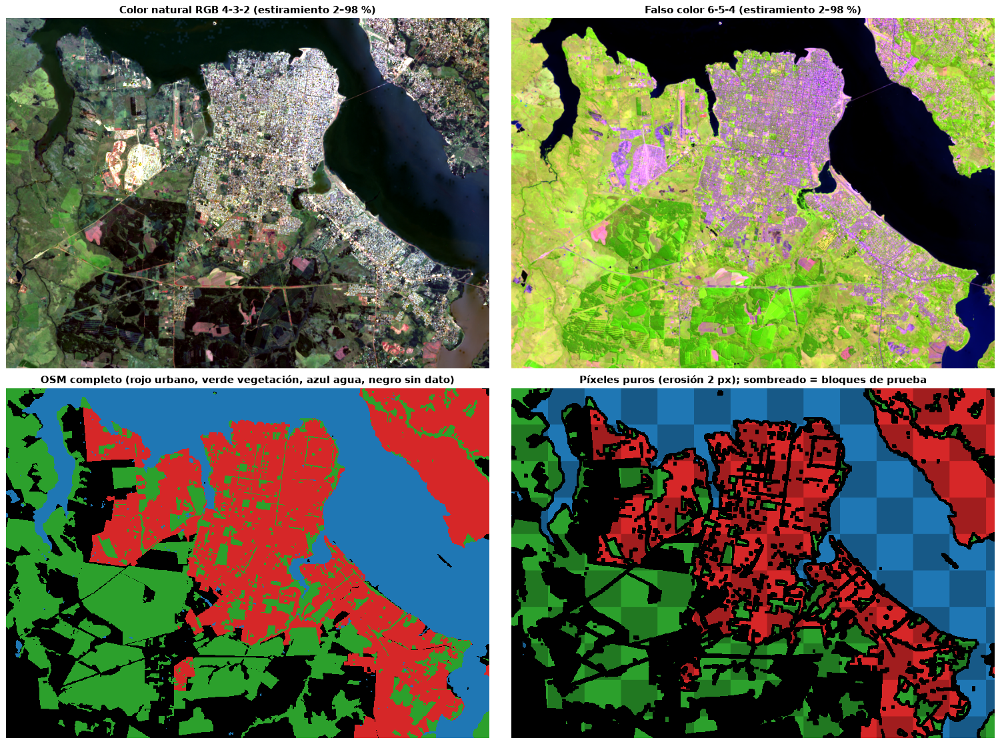

In [7]:
# 2. Descarga (o caché) y rasterización de OpenStreetMap
import requests

OSM_JSON = os.path.join(CTX_DIR, "osm_landcover_posadas.json")
OSM_NPY = os.path.join(CTX_DIR, "osm_landcover_mask.npy")
URB = {"residential", "commercial", "industrial", "retail", "railway", "garages"}
VEG_LU = {"forest", "farmland", "grass", "meadow", "orchard", "plant_nursery", "recreation_ground", "village_green"}
VEG_NAT = {"wood", "scrub", "grassland", "wetland", "heath"}
VEG_LEI = {"park", "nature_reserve", "golf_course"}

def descargar_osm():
    bb = f"({LAT_S},{LON_O},{LAT_N},{LON_E})"
    consulta = f"""[out:json][timeout:90];
    (
      way["landuse"~"^(residential|commercial|industrial|retail|railway|garages)$"]{bb};
      relation["landuse"~"^(residential|commercial|industrial|retail|railway|garages)$"]{bb};
      way["landuse"~"^(forest|farmland|grass|meadow|orchard|plant_nursery|recreation_ground|village_green)$"]{bb};
      relation["landuse"~"^(forest|farmland|grass|meadow|orchard)$"]{bb};
      way["natural"~"^(wood|scrub|grassland|wetland|heath)$"]{bb};
      relation["natural"~"^(wood|scrub|grassland|wetland)$"]{bb};
      way["leisure"~"^(park|nature_reserve|golf_course)$"]{bb};
      relation["leisure"~"^(park|nature_reserve)$"]{bb};
      way["natural"="water"]{bb};
      relation["natural"="water"]{bb};
      way["waterway"="riverbank"]{bb};
    );
    out geom;"""
    r = requests.post("https://overpass-api.de/api/interpreter", data={"data": consulta},
                      headers={"User-Agent": "UNaM-FDPI-catedra/1.0"}, timeout=120)
    r.raise_for_status()
    with open(OSM_JSON, "w", encoding="utf-8") as f:
        json.dump(r.json(), f)

def clase_de(tags):
    if tags.get("natural") == "water" or tags.get("waterway") == "riverbank":
        return 3
    if tags.get("landuse") in URB:
        return 1
    if tags.get("landuse") in VEG_LU or tags.get("natural") in VEG_NAT or tags.get("leisure") in VEG_LEI:
        return 2
    return 0

def unir_anillos(segmentos):
    """Une los tramos (ways) de una relación multipolígono en anillos cerrados."""
    segs = [list(s) for s in segmentos if len(s) >= 2]
    anillos = []
    while segs:
        actual = segs.pop(0)
        cambio = True
        while actual[0] != actual[-1] and cambio:
            cambio = False
            for i, s in enumerate(segs):
                if s[0] == actual[-1]:
                    actual = actual + s[1:]
                elif s[-1] == actual[-1]:
                    actual = actual + s[::-1][1:]
                elif s[-1] == actual[0]:
                    actual = s + actual[1:]
                elif s[0] == actual[0]:
                    actual = s[::-1] + actual[1:]
                else:
                    continue
                segs.pop(i)
                cambio = True
                break
        anillos.append(actual)
    return anillos

def a_poligono(puntos):
    lat = np.array([p[0] for p in puntos])
    lon = np.array([p[1] for p in puntos])
    fil, col = latlon_a_pixel(lat, lon)
    return np.stack([col - C1, fil - R1], axis=1).round().astype(np.int32)

def rasterizar_osm(datos):
    capas = {c: np.zeros((H, W), np.uint8) for c in CLASES}
    for e in datos["elements"]:
        c = clase_de(e.get("tags", {}))
        if c == 0:
            continue
        if e["type"] == "way":
            pts = [(p["lat"], p["lon"]) for p in e.get("geometry", [])]
            if len(pts) >= 3:
                cv2.fillPoly(capas[c], [a_poligono(pts)], 1)
        else:
            miembros = [m for m in e.get("members", []) if m["type"] == "way"]
            geo = lambda m: [(p["lat"], p["lon"]) for p in m.get("geometry", [])]
            tmp = np.zeros((H, W), np.uint8)
            for anillo in unir_anillos([geo(m) for m in miembros if m.get("role") in ("outer", "")]):
                if len(anillo) >= 3:
                    cv2.fillPoly(tmp, [a_poligono(anillo)], 1)
            for anillo in unir_anillos([geo(m) for m in miembros if m.get("role") == "inner"]):
                if len(anillo) >= 3:
                    cv2.fillPoly(tmp, [a_poligono(anillo)], 0)
            capas[c] |= tmp
    etiquetas = np.zeros((H, W), np.uint8)
    for c in (1, 2, 3):  # prioridad creciente: agua > vegetación > urbano
        etiquetas[capas[c] == 1] = c
    return etiquetas

if os.path.exists(OSM_NPY):
    etiquetas = np.load(OSM_NPY)
    print("Etiquetas OSM cargadas desde caché:", OSM_NPY)
else:
    try:
        if not os.path.exists(OSM_JSON):
            print("Descargando OpenStreetMap (Overpass API, ~30 s)...")
            descargar_osm()
        with open(OSM_JSON, encoding="utf-8") as f:
            etiquetas = rasterizar_osm(json.load(f))
        np.save(OSM_NPY, etiquetas)
    except Exception as e:
        # Respaldo: máscara urbana binaria previa + agua del QA_PIXEL de Landsat (bit 7); el resto se toma como "vegetación"
        print(f"No se pudo obtener OSM ({e}). Se usa la máscara binaria previa como respaldo.")
        etiquetas = np.full((H, W), 2, np.uint8)
        etiquetas[np.load(os.path.join(CTX_DIR, "osm_urban_mask.npy")) == 1] = 1
        etiquetas[AGUA_QA] = 3

# Píxeles puros: erosión de 2 px por clase
nucleo = np.ones((5, 5), np.uint8)
puras = np.zeros_like(etiquetas)
for c in CLASES:
    puras[cv2.erode((etiquetas == c).astype(np.uint8), nucleo) == 1] = c

# Partición espacial en bloques tipo tablero de ajedrez
BLOQUE = 64
filas, cols = np.indices((H, W))
es_test = ((filas // BLOQUE + cols // BLOQUE) % 2) == 1

resumen = pd.DataFrame({
    "clase": [CLASES[c] for c in CLASES],
    "% del recorte (OSM completo)": [100 * (etiquetas == c).mean() for c in CLASES],
    "% del recorte (sólo puros)": [100 * (puras == c).mean() for c in CLASES],
    "Nº píxeles puros — entrenamiento": [int(((puras == c) & ~es_test).sum()) for c in CLASES],
    "Nº píxeles puros — prueba": [int(((puras == c) & es_test).sum()) for c in CLASES],
}).round(1)
display(resumen)
print(f"Sin etiqueta: {100 * (etiquetas == 0).mean():.1f} % de la imagen")

# Muestra fija y balanceada de píxeles puros para las métricas de separabilidad (secciones 5 a 7)
rng = np.random.default_rng(SEMILLA)
N_CLASE = 1500
IDX = {c: rng.choice(np.flatnonzero(puras.ravel() == c), N_CLASE, replace=False) for c in CLASES}

cmap_clases = ListedColormap(["#000000", COLOR_CLASE[1], COLOR_CLASE[2], COLOR_CLASE[3]])
fig, axes = plt.subplots(2, 2, figsize=(17, 12.5), dpi=90)
axes[0, 0].imshow(np.dstack([estirar(REFL[b]) for b in (4, 3, 2)]))
axes[0, 0].set_title("Color natural RGB 4-3-2 (estiramiento 2–98 %)", fontweight="bold")
axes[0, 1].imshow(np.dstack([estirar(REFL[b]) for b in (6, 5, 4)]))
axes[0, 1].set_title("Falso color 6-5-4 (estiramiento 2–98 %)", fontweight="bold")
axes[1, 0].imshow(etiquetas, cmap=cmap_clases, vmin=0, vmax=3, interpolation="nearest")
axes[1, 0].set_title("OSM completo (rojo urbano, verde vegetación, azul agua, negro sin dato)", fontweight="bold")
axes[1, 1].imshow(puras, cmap=cmap_clases, vmin=0, vmax=3, interpolation="nearest")
axes[1, 1].imshow(np.ma.masked_where(~es_test, es_test), cmap="gray", alpha=0.25)
axes[1, 1].set_title("Píxeles puros (erosión 2 px); sombreado = bloques de prueba", fontweight="bold")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "02_etiquetas_osm.png"), bbox_inches="tight")
plt.show()

### Bitácora — sección 2
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Referencia | OpenStreetMap en 3 clases (urbano, vegetación, agua), guardado en caché | Independiente de los colores de la imagen | Etiquetar por color o umbral | Razonamiento circular (Notebook 2) | Cátedra |
| Rasterización | Polígonos proyectados a UTM con la misma función del recorte | Imagen y etiquetas en la misma grilla | Interpolar lat/lon linealmente | Desfase de hasta ~200 m: la grilla UTM está rotada ~7 px | Métrica |
| Superposiciones | Prioridad agua > vegetación > urbano | Una plaza dentro de un barrio es vegetación | Sin prioridad | — | Visual |
| Píxeles puros | Erosión de 2 px por clase | Elimina los bordes mezclados | Polígonos completos | Ruido de etiqueta: Silhouette ≈ 0.04 en el notebook anterior | Métrica |
| Partición | Bloques de 64 × 64 px en tablero de ajedrez | Los umbrales de la caja y la asignación de grupos se derivan sólo de los bloques de entrenamiento; la evaluación usa los de prueba | Partición al azar por píxel | Autocorrelación espacial: píxeles de prueba "pegados" a los de entrenamiento inflan los resultados | Buenas prácticas de validación |

## 3. Composiciones RGB: principal (6, 5, 4), secundaria (7-6-4) y referencia (4-3-2)

Fundamento físico de las bandas:

| Banda | Rango | Urbano / construido | Vegetación | Agua |
|---|---|---|---|---|
| B4 Rojo | 0.64–0.67 µm | reflectancia moderada (hormigón, techos) | baja (absorción de clorofila) | baja |
| B5 NIR | 0.85–0.88 µm | moderada-baja | **muy alta** (estructura celular de la hoja) | casi nula |
| B6 SWIR 1 | 1.57–1.65 µm | **alta** (materiales secos, asfalto, techos) | media (agua foliar absorbe) | nula |
| B7 SWIR 2 | 2.11–2.29 µm | **alta** | baja (absorción por agua foliar más fuerte que en B6) | nula |

- **Principal:** las $3! = 6$ permutaciones de {6, 5, 4}, que son las bandas que pide la consigna. El orden en que se asignan a R, G y B cambia el color con el que aparece cada cobertura, y por lo tanto cómo se separan en cada espacio de color.
- **Secundaria (en paralelo):** **7-6-4**, la composición "Falso color (urbano)" de la tabla de la cátedra. Reemplaza el NIR por el SWIR 2. Ambos SWIR responden fuerte a lo construido y el contraste con la vegetación pasa a estar en el canal rojo.
- **Referencia:** 4-3-2 (color natural), para tener una línea de base de "lo que vería un humano".

**Realce por defecto: estiramiento lineal por percentiles 2–98 %** por banda, como en el Notebook 10 de cátedra.

Cada banda trae reflectancias en un rango estrecho (por ejemplo 0.02–0.35), y para mostrarla en 8 bits hay que llevarla a 0–255:
1. Se calculan los percentiles $P_2$ y $P_{98}$ de la banda, es decir los valores que dejan un 2 % de los píxeles por debajo y un 2 % por encima.
2. Se aplica $v' = 255 \cdot \dfrac{v - P_2}{P_{98} - P_2}$, recortando a [0, 255] lo que cae afuera.

Así se sacrifica el 4 % más extremo (reflejos, sombras puntuales) para usar todo el rango de grises en el 96 % restante. La sección 4 compara este realce con otras técnicas y con no aplicar realce.

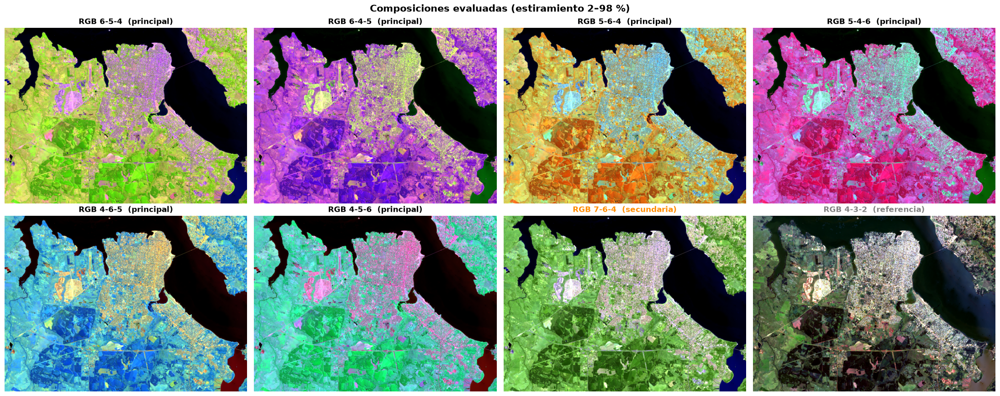

In [8]:
# 3. Realces de contraste por banda y construcción de composiciones
def ecualizar(banda):
    """Ecualización global del histograma a partir de la CDF (Notebooks 6 y 10 de cátedra)."""
    return (exposure.equalize_hist(banda, nbins=4096) * 255).astype(np.uint8)

def clahe_luminancia(rgb, clip=0.02):
    """CLAHE (ecualización adaptativa, Notebook 6) aplicada sólo a L* para no alterar el matiz."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = (exposure.equalize_adapthist(lab[..., 0], clip_limit=clip) * 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

# "sin realce" = escalado lineal mínimo–máximo (percentiles 0–100): la conversión mínima a 8 bits, sin recorte
REALCES = ["sin realce", "estiramiento", "ecualizacion", "clahe"]
_bandas_8bit = {}

def banda_8bit(b, realce):
    modo = realce if realce in ("sin realce", "ecualizacion") else "estiramiento"
    if (b, modo) not in _bandas_8bit:
        if modo == "ecualizacion":
            _bandas_8bit[(b, modo)] = ecualizar(REFL[b])
        elif modo == "sin realce":
            _bandas_8bit[(b, modo)] = estirar(REFL[b], 0, 100)
        else:
            _bandas_8bit[(b, modo)] = estirar(REFL[b])
    return _bandas_8bit[(b, modo)]

def componer(combo, realce="estiramiento"):
    rgb = np.dstack([banda_8bit(b, realce) for b in combo])
    return clahe_luminancia(rgb) if realce == "clahe" else rgb

COMBOS = {f"{r}-{g}-{b}": (r, g, b) for r, g, b in permutations((6, 5, 4))}
COMBOS["7-6-4"] = (7, 6, 4)
COMBOS["4-3-2"] = (4, 3, 2)
GRUPO = {k: "principal" for k in COMBOS}
GRUPO["7-6-4"], GRUPO["4-3-2"] = "secundaria", "referencia"

IMAGENES = {k: componer(c) for k, c in COMBOS.items()}
for k, img in IMAGENES.items():
    plt.imsave(os.path.join(IMG_DIR, f"composicion_{k.replace('-', '')}.png"), img)

fig, axes = plt.subplots(2, 4, figsize=(22, 9), dpi=100)
for ax, (k, img) in zip(axes.flat, IMAGENES.items()):
    ax.imshow(img)
    ax.set_title(f"RGB {k}  ({GRUPO[k]})", fontsize=12, fontweight="bold",
                 color={"principal": "black", "secundaria": "darkorange", "referencia": "gray"}[GRUPO[k]])
    ax.axis("off")
plt.suptitle("Composiciones evaluadas (estiramiento 2–98 %)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "03_mosaico_composiciones.png"), bbox_inches="tight")
plt.show()

### Conclusión 3 (lectura visual)
| Composición | Urbano / construido | Vegetación | Agua |
|---|---|---|---|
| **6-5-4** | lila / lavanda | verde amarillento (plantaciones: verde intenso) | negro |
| **6-4-5** | verde-amarillo pálido; la trama de avenidas resalta | violeta / púrpura | negro |
| **5-6-4** | celeste / cian claro | naranja | negro |
| **5-4-6** | cian blanquecino | magenta / carmesí (estilo infrarrojo color) | negro |
| **4-6-5** | naranja / beige | azul | rojo muy oscuro |
| **4-5-6** | rosado | verde agua | negro |
| **7-6-4** (secundaria) | **blanco a lila claro, el contraste más marcado a la vista** | verde | negro / azul marino |
| **4-3-2** (referencia) | gris / blanco | verde oscuro | **marrón celeste**: el Paraná con sedimentos se parece a lo urbano |

- En todas las composiciones con SWIR se reconocen el **centro de Posadas**, los barrios de Itaembé Miní e Itaembé Guazú, Garupá hacia el sudeste y **Encarnación** en la orilla paraguaya (NE). También el **aeropuerto** (predio claro con la pista, al oeste del centro), la **costanera**, el **puente San Roque González** y las rutas que cruzan el sur.
- Las composiciones con SWIR (B6 y B7) **separan el agua de forma inmediata**: el agua absorbe casi todo el infrarrojo y queda negra. En color natural, en cambio, el río con sedimentos tiene un tono parecido al de lo construido.
- **La lectura visual no alcanza para decidir:** varias combinaciones "se ven bien", cada una con colores distintos. Por eso la decisión se toma con métricas en la sección 5.

### Bitácora — sección 3
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Combinaciones principales | Las 6 permutaciones de {6, 5, 4} | La consigna pide esas bandas; el orden cambia el color | Sólo la 6-5-4 | El orden "estándar" no tiene por qué ser el mejor | Consigna |
| Secundaria | 7-6-4, en paralelo | Es la "Falso color (urbano)" de la tabla de la cátedra | Ignorarla | — | Cátedra |
| Referencia | 4-3-2 (color natural) | Línea de base humana | — | — | — |
| Realce por defecto | Estiramiento 2–98 % por banda | Neutro y lineal; es el de la cátedra (Notebook 10) | Escalado mínimo–máximo | Pocos píxeles muy brillantes oscurecen toda la imagen | Visual |

## 4. Mejora de contraste (técnicas de la cátedra)

Se comparan las tres técnicas de los Notebooks 6 (*Ecualización Adaptativa*) y 10 (*Composición con Bandas Landsat 8*) contra una línea base:

0. **Sin realce (línea base):** escalado lineal del mínimo al máximo de cada banda a [0, 255], sin recortar nada. Es la conversión mínima posible a 8 bits. Como unos pocos píxeles muy brillantes (techos de chapa, reflejos) definen el máximo, la mayoría queda comprimida en tonos oscuros.
1. **Estiramiento lineal 2–98 %:** mapea el rango entre los percentiles 2 y 98 a [0, 255]. Recorta extremos (nubes, reflejos especulares) sin deformar el histograma.
2. **Ecualización global:** usa la CDF de cada banda como función de transferencia, de modo que el histograma de salida queda aproximadamente uniforme. Maximiza el contraste global, pero exagera diferencias en zonas homogéneas.
3. **CLAHE:** ecualización adaptativa por bloques con límite de recorte (`clip_limit = 0.02`). Se aplica sólo sobre la luminancia $L^*$ para no alterar el matiz, que es lo que identifica a cada cobertura.

Abajo se muestra cada imagen junto al histograma de su luminancia y la CDF (en rojo), al estilo de `plot_img_and_hist` del Notebook 6. La tabla agrega dos medidas objetivas de contraste global: el **contraste RMS** (desvío estándar de la luminancia) y la **entropía** del histograma.

> **Nota teórica.** El estiramiento y la ecualización global son transformaciones **monótonas por banda**: no crean información nueva, sólo redistribuyen las intensidades. Pueden mejorar métricas basadas en medias y distancias (Fisher, Silhouette), pero casi no cambian la separabilidad "real" (k-NN). CLAHE, en cambio, es **espacialmente variable**: el mismo valor de entrada puede salir distinto según su vecindario, lo que puede ayudar o perjudicar. La sección 5b lo mide.

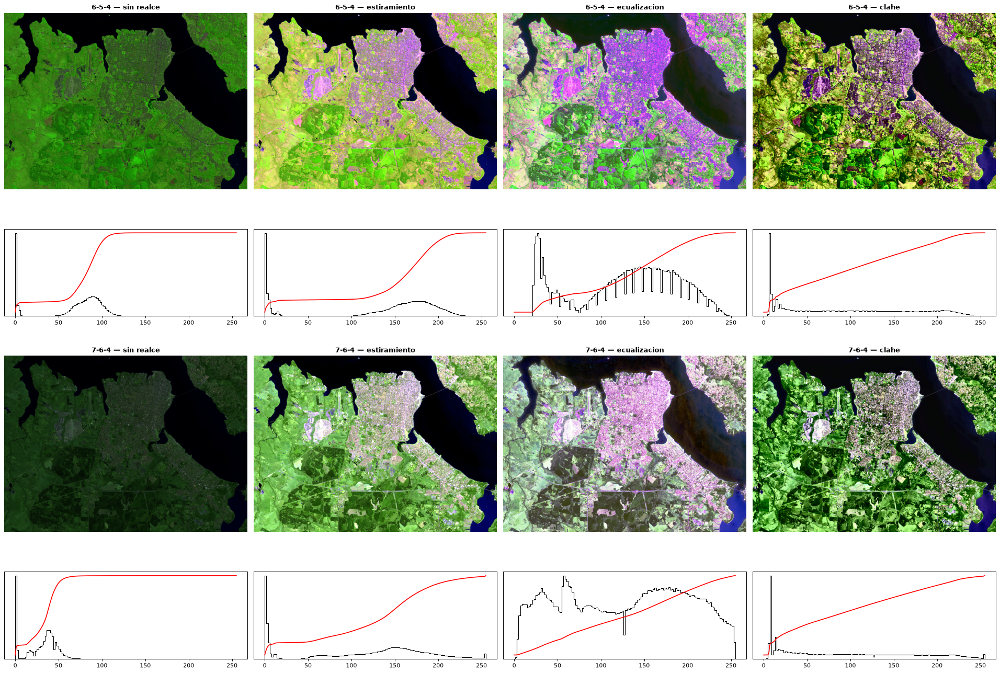

,composición,realce,contraste RMS ↑,entropía (bits) ↑
0,6-5-4,sin realce,37.44,5.78
1,6-5-4,estiramiento,74.09,6.71
2,6-5-4,ecualizacion,60.94,7.60
3,6-5-4,clahe,72.65,7.45
4,7-6-4,sin realce,18.52,5.37
5,7-6-4,estiramiento,73.04,7.23
6,7-6-4,ecualizacion,70.79,7.95
7,7-6-4,clahe,75.08,7.46


↑ mayor es mejor · ↓ menor es mejor


In [9]:
# 4. Comparación visual y cuantitativa de los realces
def entropia(gris):
    p = np.bincount(gris.ravel(), minlength=256) / gris.size
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

filas_tabla = []
fig, axes = plt.subplots(4, len(REALCES), figsize=(24, 17), dpi=80, gridspec_kw={"height_ratios": [3, 1, 3, 1]})
for i, combo in enumerate(["6-5-4", "7-6-4"]):
    for j, realce in enumerate(REALCES):
        img = componer(COMBOS[combo], realce)
        gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        ax_img, ax_hist = axes[2 * i, j], axes[2 * i + 1, j]
        ax_img.imshow(img)
        ax_img.set_title(f"{combo} — {realce}", fontweight="bold")
        ax_img.axis("off")
        ax_hist.hist(gris.ravel(), bins=128, histtype="step", color="black")
        ax_hist.set_yticks([])
        ax_cdf = ax_hist.twinx()
        ax_cdf.plot(np.arange(256), np.cumsum(np.bincount(gris.ravel(), minlength=256)) / gris.size, "r")
        ax_cdf.set_yticks([])
        filas_tabla.append({"composición": combo, "realce": realce,
                            "contraste RMS": gris.std(), "entropía (bits)": entropia(gris)})
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "04_realces_contraste.png"), bbox_inches="tight")
plt.show()
display(con_flechas(pd.DataFrame(filas_tabla)).round(2))
print(LEYENDA)

### Conclusión 4
- **Sin realce** (escalado mínimo–máximo), la imagen queda **oscura y apagada**: el contraste RMS cae a 37 en 6-5-4 y a 19 en 7-6-4, y la entropía a 5.4–5.8 bits. Unos pocos píxeles muy brillantes fijan el máximo y comprimen todo lo demás, así que algún realce es imprescindible para **ver** la imagen.
- La **ecualización global** es la que más "llena" el histograma: la entropía sube de 6.71 a 7.60 bits en 6-5-4 y de 7.23 a 7.95 en 7-6-4. A cambio, en 6-5-4 **baja el contraste RMS** (74 → 61) y exagera las diferencias dentro de zonas homogéneas, con colores saturados y menos naturales.
- **CLAHE** aumenta la entropía (≈ 7.45) manteniendo el contraste RMS (72–75) y **realza el detalle local**: calles, manzanas y bordes de barrio se leen mejor. Es la mejor opción **para mirar** la imagen.
- El **estiramiento 2–98 %** ya aprovecha bien el rango dinámico: la escena no tiene nubes ni valores extremos que lo arruinen.
- Que una imagen se vea más contrastada no implica que las clases sean más separables. Eso se mide en la sección 5b.

### Bitácora — sección 4
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Técnicas | Sin realce, estiramiento 2–98 %, ecualización global y CLAHE | Las técnicas de los Notebooks 6 y 10, más una línea base | Sólo estiramiento | No permitía saber si el realce ayuda | Cátedra |
| CLAHE | Aplicado sólo a L\* (LAB) | No altera el matiz, que identifica a cada cobertura | CLAHE por banda | Cambia los colores relativos | Teoría |
| Medida | Contraste RMS y entropía | Objetivas y comparables | Sólo mirar la imagen | Subjetivo | Métrica |

## 5. Separabilidad empírica: composiciones × espacios de color

### 5.0 ¿Son confiables Fisher, OVL y Silhouette para este problema?

Las tres métricas del Notebook 2 se mantienen, pero conviene saber qué miden y qué suponen:

| Métrica | Qué mide | Supuesto implícito | Problema en este caso |
|---|---|---|---|
| **Razón de Fisher** $\frac{(\mu_a-\mu_b)^2}{\sigma_a^2+\sigma_b^2}$ | distancia entre medias / dispersión, **canal por canal** | clases unimodales, separables por un umbral en un eje | si "no urbano" junta vegetación, agua y suelo (**multimodal**), su media cae entre los modos y su varianza explota → subestima |
| **Solapamiento OVL** $\sum_k \min(p_a,p_b)$ | masa de probabilidad compartida, **por canal** | ninguno sobre la forma (no paramétrica) | es **marginal**: dos clases pueden solaparse en cada eje por separado y separarse en 3D |
| **Silhouette** | cohesión vs. separación con **distancia euclídea** | grupos **compactos y convexos** ("esferas") | castiga clases **alargadas** (pilares en HSV, elipsoides en RGB) aunque una frontera curva las separe perfectamente |

Lo que sospechabas es correcto: **cuando la frontera entre clases no es esférica, la distancia euclídea no refleja la separabilidad real**. Hay además un cuarto factor que pesa tanto como la geometría: el **ruido de etiqueta**, por los píxeles mezclados de los polígonos OSM. Ya se mitigó con los píxeles puros.

**Abordaje adoptado:**

1. **Comparar por pares de clases**, no "urbano vs. todo lo demás". El par difícil y relevante es **urbano–vegetación**: urbano–agua es casi trivial y se informa aparte con JM.
2. Agregar dos métricas que **no suponen esfericidad**:
   - **Distancia de Jeffries–Matusita (JM)**, el estándar en teledetección para elegir bandas. Modela cada clase como una gaussiana con **covarianza completa** (elipsoides de cualquier orientación y alargamiento): $JM = 2(1-e^{-B})$, con $B$ la distancia de Bhattacharyya. Su rango es $[0, 2]$: con $JM > 1.9$ la separabilidad es muy buena y con $JM < 1$ es pobre.
   - **Exactitud balanceada de un k-NN** (k = 5, validación cruzada de 3 particiones). Es no paramétrica y local: se adapta a cualquier forma de frontera. Responde directamente "¿qué tan bien se pueden separar las clases con estos canales?".
3. **Ranking de Borda:** cada configuración recibe un puesto en cada una de las 5 métricas (en OVL, menor es mejor) y se ordena por el **puesto promedio**. Así ninguna métrica decide sola.
4. **Matiz circular:** en HSV y HLS, H se reemplaza por $(\cos H, \sin H)$, tal como corrige el Notebook 2 (sección 4.1), porque $H = 0$ y $H = 179$ son el mismo rojo.

**Espacios evaluados:** RGB, HSV, HLS, escala de grises (1 canal, que depende del orden de las bandas porque $Y = 0.299R + 0.587G + 0.114B$) y CIE L\*a\*b\*. Todas las métricas se calculan sobre la **misma muestra** de 1 500 píxeles puros por clase.

#### JM en lenguaje llano
Cada clase se imagina como una "nube" de puntos con forma de elipsoide, que puede ser alargada, inclinada o achatada. JM mide cuánto se **superponen esas dos nubes** teniendo en cuenta tanto la distancia entre sus centros como su forma:

| Valor de JM | Interpretación |
|---|---|
| 0 | las nubes son idénticas, imposible separarlas |
| 2 | no se tocan, separación perfecta |
| ≥ 1.9 | separabilidad muy buena |
| 1.0 – 1.9 | separabilidad parcial |
| < 1.0 | separabilidad pobre |

En las tablas aparecen dos columnas:
- **JM urb–veg:** urbano contra vegetación. Es el par difícil y la que entra en el ranking.
- **JM urb–agua:** urbano contra agua. Es un control: se informa pero no entra en el ranking.

#### Puesto promedio (ranking de Borda), paso a paso
Las 5 métricas tienen escalas distintas (Fisher puede valer 0.4 y OVL 0.6) y unas son "mejor si más alto" y otras "mejor si más bajo". Por eso no se suman: se **ordenan**.

1. En cada métrica se ordenan todas las configuraciones de mejor a peor y se les asigna un **puesto**, donde 1 es la mejor. En Fisher, Silhouette, JM y k-NN es mejor el valor más alto; en OVL, el más bajo.
2. Se promedian los 5 puestos de cada configuración.
3. **Menor puesto promedio = mejor configuración en conjunto.**

Ejemplo con 3 configuraciones:

| Config. | Fisher ↑ | OVL ↓ | Silhouette ↑ | JM ↑ | k-NN ↑ | Puestos | Puesto promedio ↓ |
|---|---|---|---|---|---|---|---|
| A | 0.70 (1º) | 0.52 (1º) | 0.20 (1º) | 0.75 (3º) | 0.745 (3º) | 1, 1, 1, 3, 3 | **1.8** |
| B | 0.47 (2º) | 0.59 (3º) | 0.15 (3º) | 1.41 (1º) | 0.792 (2º) | 2, 3, 3, 1, 2 | 2.2 |
| C | 0.42 (3º) | 0.55 (2º) | 0.17 (2º) | 0.93 (2º) | 0.796 (1º) | 3, 2, 2, 2, 1 | 2.0 |

A gana por ser la mejor en 3 de las 5 métricas, aunque B tenga el JM más alto. Ninguna métrica decide sola.

En todas las tablas, **↑ significa "mayor es mejor"** y **↓ significa "menor es mejor"**.

In [10]:
# 5.1 Herramientas: conversión de espacios y métricas de separabilidad
ESPACIOS = ["RGB", "HSV", "HLS", "Gris", "LAB"]
CANALES = {"RGB": ["R", "G", "B"], "HSV": ["cosH", "sinH", "S", "V"], "HLS": ["cosH", "sinH", "L", "S"],
           "Gris": ["Y"], "LAB": ["L*", "a*", "b*"]}
CANALES_CRUDOS = {"RGB": ["R", "G", "B"], "HSV": ["H", "S", "V"], "HLS": ["H", "L", "S"],
                  "Gris": ["Y"], "LAB": ["L*", "a*", "b*"]}
CODIGO_CV = {"HSV": cv2.COLOR_RGB2HSV, "HLS": cv2.COLOR_RGB2HLS, "LAB": cv2.COLOR_RGB2LAB}

def convertir_crudo(rgb, espacio):
    """Imagen (o arreglo N x 3) RGB uint8 -> canales crudos del espacio, en uint8 y con la escala de OpenCV."""
    arr = rgb.reshape(-1, 1, 3)
    if espacio == "RGB":
        out = arr
    elif espacio == "Gris":
        out = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)[..., None]
    else:
        out = cv2.cvtColor(arr, CODIGO_CV[espacio])
    return out.reshape(rgb.shape[:-1] + (out.shape[-1],))

def a_espacio(pix_rgb, espacio):
    """Pixeles (N x 3) RGB uint8 -> features del espacio, con el matiz como (cos H, sin H)."""
    x = convertir_crudo(pix_rgb, espacio).astype(np.float32)
    if espacio in ("HSV", "HLS"):
        ang = x[:, 0] * (2 * np.pi / 180.0)  # OpenCV: H en [0, 179] representa [0°, 358°]
        x = np.column_stack([np.cos(ang), np.sin(ang), x[:, 1], x[:, 2]])
    return x

# fisher_ratio y overlap_coef están definidas en la sección 1 (firmas espectrales)

def jeffries_matusita(a, b):
    """Distancia JM entre dos clases modeladas como gaussianas con covarianza completa (rango [0, 2])."""
    escala = StandardScaler().fit(np.vstack([a, b]))
    a, b = escala.transform(a), escala.transform(b)
    reg = 1e-6 * np.eye(a.shape[1])
    Sa, Sb = np.atleast_2d(np.cov(a, rowvar=False)) + reg, np.atleast_2d(np.cov(b, rowvar=False)) + reg
    S = (Sa + Sb) / 2
    dm = a.mean(axis=0) - b.mean(axis=0)
    bhat = dm @ np.linalg.solve(S, dm) / 8 + 0.5 * (np.linalg.slogdet(S)[1]
                                                    - 0.5 * (np.linalg.slogdet(Sa)[1] + np.linalg.slogdet(Sb)[1]))
    return float(2 * (1 - np.exp(-bhat)))

CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
SUB_SIL = np.random.default_rng(SEMILLA).choice(2 * N_CLASE, 1500, replace=False)

def evaluar(rgb, espacio):
    """Métricas de separabilidad urbano–vegetación (+ JM urbano–agua) sobre la muestra fija de píxeles puros."""
    pix = rgb.reshape(-1, 3)
    Xu, Xv, Xa = (a_espacio(pix[IDX[c]], espacio) for c in (1, 2, 3))
    X = np.vstack([Xu, Xv])
    y = np.r_[np.zeros(N_CLASE), np.ones(N_CLASE)]
    Xs = StandardScaler().fit_transform(X)
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    return {
        "Fisher": float(fisher_ratio(Xu, Xv).mean()),
        "OVL": float(overlap_coef(Xu, Xv).mean()),
        "Silhouette": float(silhouette_score(Xs[SUB_SIL], y[SUB_SIL])),
        "JM": jeffries_matusita(Xu, Xv),
        "kNN": float(cross_val_score(knn, X, y, cv=CV3, scoring="balanced_accuracy").mean()),
        "JM urb-agua": jeffries_matusita(Xu, Xa),
    }

METRICAS = ["Fisher", "OVL", "Silhouette", "JM", "kNN"]

def ranking_borda(df):
    """Puesto promedio en las 5 métricas (OVL: menor es mejor; el resto: mayor es mejor)."""
    puestos = pd.concat([df[m].rank(ascending=(m == "OVL")) for m in METRICAS], axis=1)
    df = df.copy()
    df["Puesto promedio"] = puestos.mean(axis=1)
    return df.sort_values("Puesto promedio").reset_index(drop=True)

def mostrar_tabla(df, archivo=None):
    df = con_flechas(df)
    if archivo:
        df.to_csv(os.path.join(IMG_DIR, archivo), index=False)
    f = FLECHAS
    sty = df.style.format(precision=3)
    sty = sty.background_gradient(subset=[f["Fisher"], f["Silhouette"], f["JM"], f["kNN"]], cmap="Greens")
    sty = sty.background_gradient(subset=[f["OVL"]], cmap="Reds").background_gradient(subset=[f["Puesto promedio"]], cmap="Blues_r")
    display(sty)
    print(LEYENDA)

### 5a. Grilla de 40 configuraciones: ¿con qué realce?

Las 40 configuraciones (8 composiciones × 5 espacios) usan el mismo realce, el **estiramiento lineal 2–98 %**, para que la comparación entre combinaciones y espacios sea justa. Se eligió ése por tres motivos:

1. **Hace falta algún paso a 8 bits.** OpenCV convierte a HSV, HLS y LAB a partir de imágenes de 0–255, y las reflectancias originales son decimales entre 0 y 1. No existe un "sin realce" literal.
2. **Es lo más neutro posible.** Es lineal y por banda: no cambia la forma del histograma ni depende del vecindario del píxel. La única diferencia con un escalado mínimo–máximo puro es que recorta el 4 % de valores extremos.
3. **Es la línea base de la cátedra** (Notebook 10).

El efecto de los otros realces, y de no realzar (escalado mínimo–máximo), se mide aparte en la **sección 5b**, sobre las mejores configuraciones.

#### Recordatorio: qué mide cada columna de la tabla

Todas las métricas comparan **urbano contra vegetación** (el par difícil), salvo "JM urb–agua". Se calculan sobre la misma muestra de 1 500 píxeles puros por clase.

| Columna | Qué mide | Por qué importa | Rango |
|---|---|---|---|
| **Fisher ↑** | distancia entre las medias de las dos clases dividida por su dispersión, canal por canal (se promedian los canales) | separación "en promedio": si es alta, un umbral en ese canal ya separa bastante | 0 a ∞ (> 1 es buena separación) |
| **OVL ↓** | qué fracción de los histogramas de ambas clases se superpone, canal por canal | cuántos píxeles quedarían "en la zona gris" con un umbral; no supone ninguna forma de distribución | 0 (no se tocan) a 1 (idénticas) |
| **Silhouette ↑** | para cada píxel, compara su distancia a su propia clase con su distancia a la otra, usando los canales juntos y la distancia euclídea | si las clases forman grupos compactos y apartados (lo que necesita K-Means) | −1 a 1 (> 0.5 grupos muy marcados) |
| **JM urb–veg ↑** | Jeffries–Matusita: superposición de las dos nubes modeladas como elipsoides (gaussianas con covarianza completa) | separación teniendo en cuenta la **forma y orientación** de las nubes, no sólo las medias; es el estándar en teledetección | 0 a 2 (≥ 1.9 muy buena) |
| **k-NN ↑** | exactitud balanceada de un clasificador de 5 vecinos más cercanos, con validación cruzada | responde directamente "¿qué fracción de píxeles se clasifica bien con estos canales?", sin suponer ninguna forma | 0.5 (azar) a 1 (perfecto) |
| **JM urb–agua ↑** | lo mismo que JM, pero urbano contra agua | control: confirma que la composición no confunde ciudad con río. **No entra en el ranking** | 0 a 2 |
| **Puesto promedio ↓** | promedio de los puestos de la configuración en Fisher, OVL, Silhouette, JM urb–veg y k-NN (1 = mejor) | combina las 5 métricas sin que ninguna decida sola | 1 (la mejor en todo) a 40 |

40 configuraciones evaluadas en 3.7 s


,composición,grupo,espacio,realce,Fisher ↑,OVL ↓,Silhouette ↑,JM urb–veg ↑,k-NN ↑,JM urb–agua ↑,Puesto promedio ↓
0,7-6-4,secundaria,HSV,estiramiento,0.473,0.592,0.152,1.407,0.792,2.000,5.600
1,4-3-2,referencia,RGB,estiramiento,0.738,0.551,0.184,0.776,0.792,1.509,5.800
2,7-6-4,secundaria,RGB,estiramiento,0.610,0.578,0.165,0.928,0.796,2.000,6.000
3,7-6-4,secundaria,LAB,estiramiento,0.546,0.589,0.179,0.960,0.789,2.000,6.600
4,7-6-4,secundaria,HLS,estiramiento,0.348,0.583,0.143,1.370,0.787,2.000,11.000
5,6-4-5,principal,LAB,estiramiento,0.700,0.525,0.198,0.750,0.745,2.000,12.200
6,4-5-6,principal,HLS,estiramiento,0.405,0.628,0.142,0.958,0.757,2.000,14.700
7,4-3-2,referencia,Gris,estiramiento,0.692,0.569,0.167,0.354,0.651,1.247,15.200
8,4-6-5,principal,HLS,estiramiento,0.405,0.628,0.142,0.958,0.756,2.000,15.500
9,6-4-5,principal,Gris,estiramiento,0.601,0.587,0.152,0.283,0.640,1.871,17.200


↑ mayor es mejor · ↓ menor es mejor


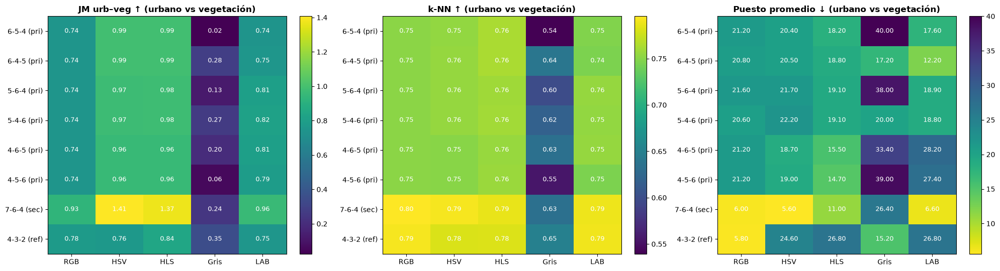

Mejor principal : 6-4-5 en LAB  | JM=0.750  kNN=0.745  Fisher=0.700  OVL=0.525  Silhouette=0.198  (puesto prom. 12.2)
Mejor secundaria: 7-6-4 en HSV  | JM=1.407  kNN=0.792  Fisher=0.473  OVL=0.592  Silhouette=0.152  (puesto prom. 5.6)
Mejor referencia: 4-3-2 en RGB  | JM=0.776  kNN=0.792  Fisher=0.738  OVL=0.551  Silhouette=0.184  (puesto prom. 5.8)


In [11]:
# 5a. Grilla: 8 composiciones x 5 espacios de color (realce base: estiramiento)
t0 = time.time()
filas_4a = []
for combo, img in IMAGENES.items():
    for esp in ESPACIOS:
        filas_4a.append({"composición": combo, "grupo": GRUPO[combo], "espacio": esp,
                         "realce": "estiramiento", **evaluar(img, esp)})
df4a = ranking_borda(pd.DataFrame(filas_4a))
print(f"40 configuraciones evaluadas en {time.time() - t0:.1f} s")
mostrar_tabla(df4a, "tabla_5a_separabilidad.csv")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), dpi=100)
for ax, (metrica, cmap) in zip(axes, [("JM", "viridis"), ("kNN", "viridis"), ("Puesto promedio", "viridis_r")]):
    tabla = df4a.pivot(index="composición", columns="espacio", values=metrica).loc[list(COMBOS), ESPACIOS]
    im = ax.imshow(tabla.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(len(ESPACIOS)), ESPACIOS)
    ax.set_yticks(range(len(COMBOS)), [f"{k} ({GRUPO[k][:3]})" for k in COMBOS])
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            ax.text(j, i, f"{tabla.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=9)
    ax.set_title(f"{FLECHAS[metrica]} (urbano vs vegetación)", fontweight="bold")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "05a_mapa_calor_separabilidad.png"), bbox_inches="tight")
plt.show()

def mejor_de(df, grupo):
    return df[df["grupo"] == grupo].iloc[0]

for g in ["principal", "secundaria", "referencia"]:
    f = mejor_de(df4a, g)
    print(f"Mejor {g:10s}: {f['composición']} en {f['espacio']:4s} | JM={f['JM']:.3f}  kNN={f['kNN']:.3f}  "
          f"Fisher={f['Fisher']:.3f}  OVL={f['OVL']:.3f}  Silhouette={f['Silhouette']:.3f}  (puesto prom. {f['Puesto promedio']:.1f})")

### Conclusión 5a
1. **En RGB, las 6 permutaciones de {6, 5, 4} son idénticas para las métricas:** Fisher 0.417, OVL 0.640, Silhouette 0.133, JM 0.743 y k-NN 0.751 en las seis. Permutar bandas en RGB sólo **reordena los ejes**, y todas las métricas (con estandarización) son invariantes a ese reordenamiento. El orden de las bandas cambia **cómo lo percibe un humano**, no **la información disponible**. Las diferencias aparecen recién al pasar a espacios **no lineales** (HSV, HLS, LAB, gris), cuyas fórmulas tratan distinto a R, G y B.
2. **La escala de grises es el peor espacio:** 6-5-4 en gris queda último de las 40 configuraciones (JM 0.025, k-NN 0.54, casi azar). La luminancia $Y = 0.299R + 0.587G + 0.114B$ mezcla el SWIR alto de lo urbano con el NIR alto de la vegetación, y ambas coberturas terminan con el mismo brillo. Un solo canal no alcanza.
3. **Mejor combinación principal: 6-4-5 en LAB** (puesto promedio 12.2). Logra los mejores Fisher (0.700), OVL (0.525) y Silhouette (0.198) del grupo principal, con k-NN 0.745 y JM 0.75.
4. **La secundaria 7-6-4 domina el ranking:** primera en HSV (JM 1.41, k-NN 0.792) y tercera en RGB (k-NN 0.796, el más alto de las 40), con 4 de sus 5 espacios en el top 5. El SWIR 2 distingue mejor que el NIR los materiales secos (techos, asfalto) de la vegetación húmeda, sobre todo en barrios arbolados donde el NIR "ve" las copas de los árboles.
5. **La referencia 4-3-2 es sorprendentemente competitiva para urbano–vegetación** (2.ª, k-NN 0.792): los techos y pavimentos claros contrastan con la vegetación oscura. Pero falla con el agua: **JM urbano–agua = 1.51**, contra **2.00 (separación perfecta)** en todas las composiciones con SWIR. Ese es el aporte que justifica las bandas de la consigna.
6. **Sobre las métricas:** Fisher y Silhouette quedan bajos (0.1–0.2), mientras que k-NN (≈ 0.75–0.80) y JM (hasta 1.41) muestran una separabilidad bastante mayor. En HSV/HLS, Fisher es bajo pero JM es alto: las clases **no difieren tanto en sus medias como en la forma y orientación de sus nubes**, justo lo que las métricas euclídeas o de medias no ven. Esto confirma la sospecha planteada en la sección 5.0. Además, con etiquetas puras y comparación por pares, el Silhouette pasó de ~0.04 (notebook anterior) a 0.13–0.20.
7. Con cualquier terna de bandas, urbano–vegetación tiene un **techo de ≈ 0.80** de exactitud. La causa es física: a 30 m, un píxel de un barrio arbolado de Posadas mezcla techo, calle y copa de árbol.

In [12]:
# 5b. ¿Ayuda el realce de contraste? Se prueban las mejores configuraciones sin realce y con los 3 realces
candidatos = pd.concat([df4a.head(3), df4a[df4a["grupo"] == "principal"].head(1),
                        df4a[df4a["grupo"] == "secundaria"].head(1)]).drop_duplicates(["composición", "espacio"])
filas_4b = []
for _, f in candidatos.iterrows():
    for realce in REALCES:
        filas_4b.append({"composición": f["composición"], "grupo": f["grupo"], "espacio": f["espacio"],
                         "realce": realce, **evaluar(componer(COMBOS[f["composición"]], realce), f["espacio"])})
df4b = ranking_borda(pd.DataFrame(filas_4b))
mostrar_tabla(df4b, "tabla_5b_realces.csv")

# Efecto de cada realce comparado contra la línea base "sin realce" (escalado mínimo–máximo)
for metrica in ["kNN", "JM"]:
    tabla = df4b.pivot_table(index=["composición", "espacio"], columns="realce", values=metrica)[REALCES]
    delta = tabla[REALCES[1:]].sub(tabla["sin realce"], axis=0)
    delta.columns = [f"Δ {c}" for c in delta.columns]
    print(f"\n{FLECHAS[metrica]} según el realce (valores y diferencia respecto de 'sin realce'; Δ > 0 = el realce mejora):")
    display(pd.concat([tabla, delta], axis=1).style.format(precision=3)
            .background_gradient(subset=list(delta.columns), cmap="RdYlGn", vmin=-0.1, vmax=0.1))

# Configuraciones ganadoras que se usan en el resto del notebook (principal y secundaria, en paralelo)
GANADOR_P = mejor_de(df4b, "principal")
GANADOR_S = mejor_de(df4b, "secundaria")
CONFIG = {
    "principal": dict(combo=GANADOR_P["composición"], espacio=GANADOR_P["espacio"], realce=GANADOR_P["realce"]),
    "secundaria": dict(combo=GANADOR_S["composición"], espacio=GANADOR_S["espacio"], realce=GANADOR_S["realce"]),
}
for nombre, cfg in CONFIG.items():
    cfg["rgb"] = componer(COMBOS[cfg["combo"]], cfg["realce"])
    cfg["etiqueta"] = f"{cfg['combo']} | {cfg['espacio']} | {cfg['realce']}"
    print(f"GANADOR {nombre.upper():10s}: {cfg['etiqueta']}")

,composición,grupo,espacio,realce,Fisher ↑,OVL ↓,Silhouette ↑,JM urb–veg ↑,k-NN ↑,JM urb–agua ↑,Puesto promedio ↓
0,4-3-2,referencia,RGB,estiramiento,0.738,0.551,0.184,0.776,0.792,1.509,4.600
1,4-3-2,referencia,RGB,ecualizacion,0.751,0.549,0.197,0.563,0.792,1.508,5.400
2,7-6-4,secundaria,RGB,estiramiento,0.610,0.578,0.165,0.928,0.796,2.000,5.600
3,7-6-4,secundaria,RGB,ecualizacion,0.599,0.572,0.177,0.785,0.794,1.920,5.800
4,6-4-5,principal,LAB,ecualizacion,0.721,0.513,0.215,0.640,0.757,1.981,5.800
5,6-4-5,principal,LAB,estiramiento,0.700,0.525,0.198,0.750,0.745,2.000,6.400
6,4-3-2,referencia,RGB,sin realce,0.644,0.553,0.176,0.794,0.777,1.494,6.400
7,7-6-4,secundaria,RGB,sin realce,0.555,0.575,0.158,1.004,0.790,2.000,7.000
8,7-6-4,secundaria,HSV,estiramiento,0.473,0.592,0.152,1.407,0.792,2.000,7.400
9,7-6-4,secundaria,HSV,sin realce,0.289,0.604,0.126,1.705,0.790,2.000,8.800


↑ mayor es mejor · ↓ menor es mejor

k-NN ↑ según el realce (valores y diferencia respecto de 'sin realce'; Δ > 0 = el realce mejora):



JM urb–veg ↑ según el realce (valores y diferencia respecto de 'sin realce'; Δ > 0 = el realce mejora):


GANADOR PRINCIPAL : 6-4-5 | LAB | ecualizacion
GANADOR SECUNDARIA: 7-6-4 | RGB | estiramiento


### Conclusión 5b
Todas las comparaciones son **contra la línea base "sin realce"** (escalado mínimo–máximo):

| Realce | Δ k-NN ↑ | Δ JM urb–veg ↑ | Lectura |
|---|---|---|---|
| **Estiramiento 2–98 %** | +0.002 a +0.015 | −0.02 a −0.30 | mejora apenas la exactitud; recortar extremos "aplana" las colas de las distribuciones |
| **Ecualización global** | +0.004 a **+0.026** | −0.16 a −0.94 | el mayor aumento de k-NN (6-4-5 LAB: 0.731 → 0.757); deforma las distribuciones y JM, que supone forma gaussiana, cae mucho |
| **CLAHE** | **−0.044** a +0.012 | −0.23 a −0.39 | empeora casi siempre (7-6-4 RGB: 0.790 → 0.746; 4-3-2: 0.777 → 0.733) |

- **El valor más alto de JM se obtiene sin realce** (7-6-4 HSV: **1.705**, contra 1.407 con estiramiento). Cualquier transformación no lineal (recorte, ecualización, CLAHE) aleja las nubes de la forma gaussiana que modela JM.
- La exactitud k-NN, que no asume forma, **mejora poco** con el estiramiento o la ecualización: hasta +0.026. Las transformaciones monótonas por banda **no crean información**; a lo sumo reparten mejor los niveles de gris disponibles en 8 bits.
- **CLAHE**, al ser espacialmente variable, da valores distintos al mismo material según su vecindario y **aumenta la dispersión dentro de cada clase**. Sirve para ver detalle, no para clasificar.
- **Configuraciones ganadoras para el resto del análisis:**
  - **Principal:** **6-4-5 | LAB | ecualización**.
  - **Secundaria:** **7-6-4 | RGB | estiramiento 2–98 %**.
  - El ganador principal lleva ecualización porque es el que mejor puesto promedio obtiene: mejora k-NN, Fisher, OVL y Silhouette, aunque pierde JM.
- **Conclusión general:** la mejora de contraste es imprescindible para **visualizar** (ver la conclusión 4), pero no agrega separabilidad. Las ganancias son de centésimas, y los valores de JM indican incluso que conviene clasificar sobre datos sin realzar.

### Bitácora — sección 5
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Métricas | Fisher, OVL y Silhouette (cátedra) + JM y k-NN | JM y k-NN no suponen nubes esféricas | Sólo las 3 de la cátedra | Subestiman con nubes alargadas o multimodales | Métrica |
| Clases comparadas | Urbano–vegetación para el ranking; urbano–agua como control | "No urbano" es multimodal | Urbano contra "todo lo demás" | Fisher y Silhouette engañosos | Métrica |
| Matiz | (cos H, sin H) | H es un ángulo: 0 y 179 son el mismo rojo | H crudo | Varianza inflada | Notebook 2 |
| Ranking | Puesto promedio (Borda) en 5 métricas | Ninguna métrica decide sola | Desempate por Silhouette | Arbitrario | — |
| Muestra | 1 500 píxeles puros por clase, fija | Rápido (< 10 s) y comparable entre configuraciones | Toda la imagen | Lento | Tiempo |
| Ganadores | Principal: 6-4-5 LAB ecualización; secundaria: 7-6-4 RGB estiramiento | Mejor puesto de su grupo | 6-5-4 en RGB | En RGB las 6 permutaciones empatan | Métrica |

## 6. Histogramas espectrales por espacio de color

- **5a. Histogramas globales:** las 8 composiciones en los 5 espacios, con los canales crudos (H en la escala 0–179 de OpenCV). Muestran cómo cambia la distribución al permutar las bandas.
- **5b. Histogramas condicionados por clase:** urbano, vegetación y agua superpuestos, para las dos configuraciones ganadoras. Son los que permiten **elegir umbrales**: un canal sirve para segmentar si el pico urbano queda aislado del de vegetación.

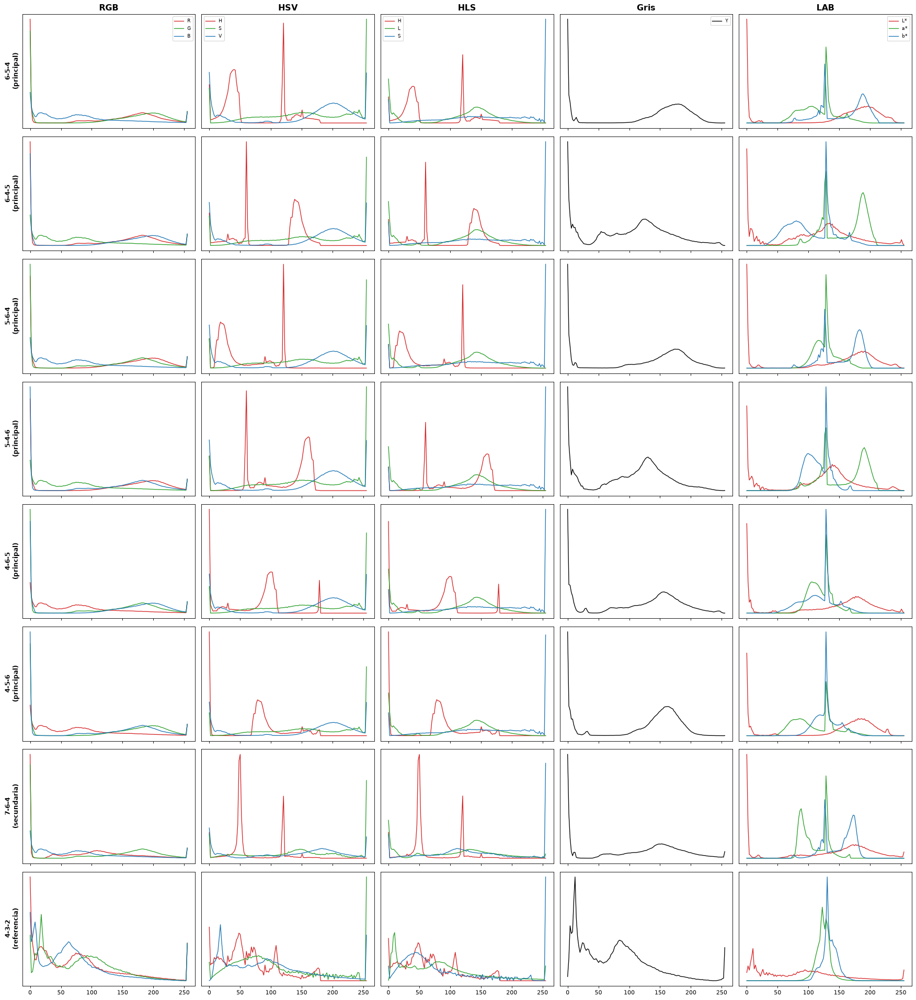

In [13]:
# 6a. Histogramas globales: 8 composiciones x 5 espacios
colores_canal = ["#d62728", "#2ca02c", "#1f77b4"]
fig, axes = plt.subplots(len(COMBOS), len(ESPACIOS), figsize=(22, 24), dpi=80, sharex=True)
for i, (combo, img) in enumerate(IMAGENES.items()):
    for j, esp in enumerate(ESPACIOS):
        crudo = convertir_crudo(img, esp)
        ax = axes[i, j]
        for c, nombre in enumerate(CANALES_CRUDOS[esp]):
            hist = cv2.calcHist([crudo], [c], None, [128], [0, 256]).ravel()
            ax.plot(np.linspace(0, 255, 128), hist / hist.sum(), color="black" if esp == "Gris" else colores_canal[c],
                    label=nombre, lw=1.2)
        ax.set_yticks([])
        if i == 0:
            ax.set_title(esp, fontsize=14, fontweight="bold")
        if j == 0:
            ax.set_ylabel(f"{combo}\n({GRUPO[combo]})", fontsize=11, fontweight="bold")
        if i == 0:
            ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "06a_histogramas_globales.png"), bbox_inches="tight")
plt.show()

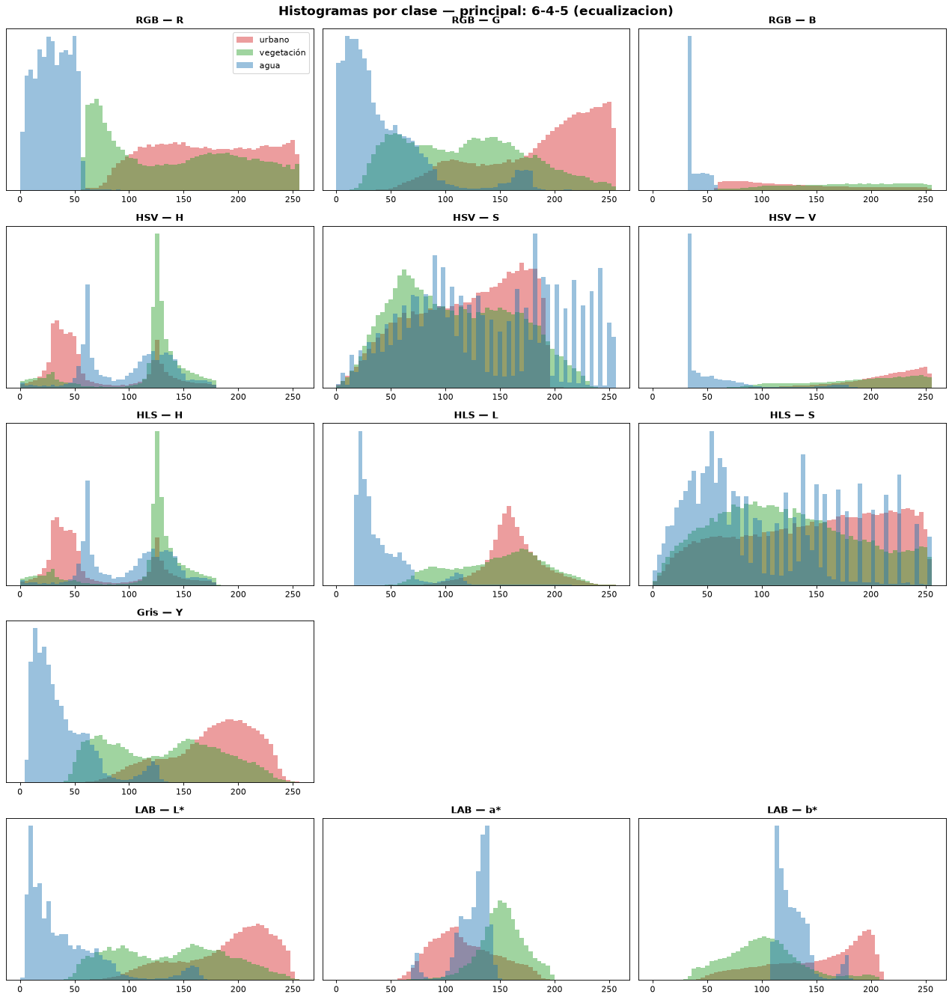

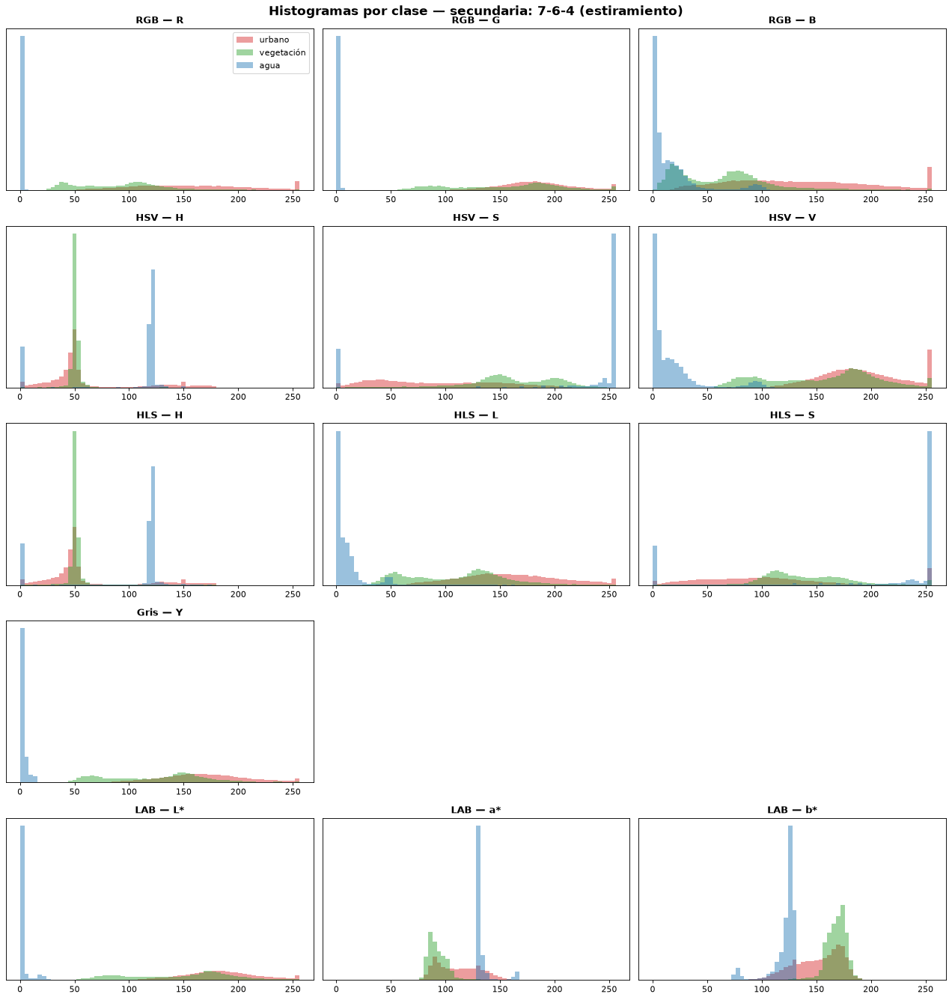

config,composición,espacio,canal,Fisher ↑,OVL ↓,urbano > vegetación
principal,6-4-5,LAB,a*,0.832,0.463,False
principal,6-4-5,LAB,b*,0.731,0.505,True
principal,6-4-5,RGB,G,0.781,0.513,True
principal,6-4-5,LAB,L*,0.600,0.571,True
principal,6-4-5,Gris,Y,0.474,0.628,True
secundaria,7-6-4,HSV,S,0.968,0.471,False
secundaria,7-6-4,RGB,R,0.849,0.497,True
secundaria,7-6-4,LAB,a*,0.751,0.513,True
secundaria,7-6-4,RGB,B,0.763,0.519,True
secundaria,7-6-4,HLS,S,0.198,0.540,False


↑ mayor es mejor · ↓ menor es mejor
Mejor canal individual (principal): LAB-a*  OVL=0.463  Fisher=0.832
Mejor canal individual (secundaria): HSV-S  OVL=0.471  Fisher=0.968


In [14]:
# 6b. Histogramas por clase (píxeles puros) para las configuraciones ganadoras, en los 5 espacios
def histogramas_por_clase(rgb, titulo, archivo):
    fig, axes = plt.subplots(len(ESPACIOS), 3, figsize=(16, 17), dpi=80)
    for i, esp in enumerate(ESPACIOS):
        crudo = convertir_crudo(rgb, esp)
        for j in range(3):
            ax = axes[i, j]
            if j >= crudo.shape[-1]:
                ax.axis("off")
                continue
            for c in CLASES:
                hist = cv2.calcHist([np.ascontiguousarray(crudo[..., j])], [0], (puras == c).astype(np.uint8),
                                    [64], [0, 256]).ravel()
                ax.stairs(hist / hist.sum(), np.linspace(0, 256, 65), fill=True, alpha=0.45,
                          color=COLOR_CLASE[c], label=CLASES[c])
            ax.set_title(f"{esp} — {CANALES_CRUDOS[esp][j]}", fontweight="bold")
            ax.set_yticks([])
            if i == 0 and j == 0:
                ax.legend()
    plt.suptitle(titulo, fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(IMG_DIR, archivo), bbox_inches="tight")
    plt.show()

for nombre, cfg in CONFIG.items():
    histogramas_por_clase(cfg["rgb"], f"Histogramas por clase — {nombre}: {cfg['combo']} ({cfg['realce']})",
                          f"06b_histogramas_clase_{nombre}.png")

# Separabilidad de cada canal individual (urbano vs vegetación), para elegir el canal de umbralización
filas_canal = []
for nombre, cfg in CONFIG.items():
    for esp in ESPACIOS:
        crudo = convertir_crudo(cfg["rgb"], esp).reshape(-1, len(CANALES_CRUDOS[esp]))
        for j, canal in enumerate(CANALES_CRUDOS[esp]):
            if canal == "H":
                continue  # el matiz es circular: no admite un umbral simple
            u, v = crudo[IDX[1], j:j + 1].astype(float), crudo[IDX[2], j:j + 1].astype(float)
            filas_canal.append({"config": nombre, "composición": cfg["combo"], "espacio": esp, "canal": canal,
                                "Fisher": fisher_ratio(u, v)[0], "OVL": overlap_coef(u, v)[0],
                                "urbano > vegetación": bool(u.mean() > v.mean())})
df_canal = pd.DataFrame(filas_canal).sort_values(["config", "OVL"])
display(con_flechas(df_canal.groupby("config").head(5)).round(3).style.format(precision=3).hide(axis="index"))
print(LEYENDA)
MEJOR_CANAL = {n: df_canal[df_canal["config"] == n].iloc[0] for n in CONFIG}
for n, f in MEJOR_CANAL.items():
    print(f"Mejor canal individual ({n}): {f['espacio']}-{f['canal']}  OVL={f['OVL']:.3f}  Fisher={f['Fisher']:.3f}")

#### Cómo leer la tabla de canales individuales

La tabla de arriba prepara la **umbralización de la sección 8**, que necesita **un solo canal**. Responde: si tuviera que separar urbano de vegetación mirando un único canal, ¿cuál conviene?

- **Qué se evaluó:** se tomó la imagen de cada configuración ganadora:
  - **principal** = composición 6-4-5 con ecualización;
  - **secundaria** = 7-6-4 con estiramiento.

  Cada una se convirtió a los 5 espacios de color y **cada canal se evaluó por separado** (R, G y B de RGB; S y V de HSV; L\*, a\* y b\* de LAB; etc.). El matiz H se excluye porque es un ángulo y no admite un umbral simple.
- **Columnas:**
  - **config / composición:** la configuración ganadora de la que sale la imagen.
  - **espacio / canal:** en qué espacio se convirtió y qué canal se mira.
  - **Fisher ↑ y OVL ↓:** separación urbano–vegetación **en ese único canal**.
  - **urbano > vegetación:** `True` si lo urbano tiene valores **más altos** que la vegetación en ese canal y `False` si los tiene más bajos. Define el **sentido del umbral**: urbano = "por encima" o "por debajo" del corte.
- **Orden:** se muestran los 5 mejores canales de cada configuración, ordenados por OVL (menor solapamiento primero).
- **Lectura:**
  - en la **principal**, el mejor canal es **a\* de LAB** (OVL 0.463). `False` significa que lo urbano tiene a\* **más bajo** (más verde-amarillo) que la vegetación (más magenta);
  - en la **secundaria**, el mejor es **S de HSV** (OVL 0.471). Lo urbano está **menos saturado** (más blanquecino) que la vegetación.
- **Uso:** estos dos canales son los que se umbralizan con Otsu en la sección 8.

### Conclusión 6
- En **RGB**, los histogramas de las 6 permutaciones son los mismos tres histogramas reordenados, lo que explica que sus métricas coincidan. En HSV, HLS, LAB y gris, en cambio, la forma cambia con el orden de las bandas.
- **El agua es la única clase aislada** en casi todos los canales: un pico angosto en valores bajos de luminancia y brillo.
- **Urbano y vegetación se superponen en todos los canales individuales.** Los mejores canales sueltos son:
  - Principal (6-4-5): **a\* de LAB** (OVL 0.463, Fisher 0.832). Lo urbano tiene a\* **menor**: tira a verde-amarillo, mientras la vegetación tira a magenta.
  - Secundaria (7-6-4): **S de HSV** (OVL 0.471, Fisher 0.968). Lo urbano está **menos saturado** (blanquecino) que la vegetación (verde intenso).
- Aun en el mejor canal, cerca del **46 % de la distribución se comparte**. Un umbral sobre un solo canal tiene un límite claro, y eso anticipa los resultados de la sección 8.

### Bitácora — sección 6
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Histogramas por clase | Píxeles puros de cada clase superpuestos | Muestran qué canal separa urbano de vegetación | Sólo histogramas globales | No dicen qué clase es cada pico | Visual |
| Canal para umbralizar | Menor OVL urbano–vegetación, sin el matiz H | Otsu necesita un solo canal; OVL no supone forma | Elegir a ojo | Subjetivo | Métrica |
| Cálculo | `cv2.calcHist` con máscara | Rápido | `plt.hist` | 13 s de ejecución | Tiempo |

## 7. Visualización tridimensional de nubes de color

Se proyecta una muestra balanceada de píxeles puros en el espacio 3D de cada configuración, coloreados por clase (o por su color real). Siguiendo la técnica del Notebook 1, HSV y HLS se dibujan en coordenadas **cilíndricas**, $(S\cos H,\ S\sin H,\ V)$ o $(S\cos H,\ S\sin H,\ L)$. Así el matiz es un ángulo y no hay un corte artificial en 0/179.

- **Estática:** las 3 mejores configuraciones del ranking 4b.
- **Interactiva (Plotly):** se puede rotar con el mouse (clic y arrastrar), hacer zoom con la rueda y:
  - **Desplegable de configuración:** las 8 composiciones × RGB, HSV, HLS y LAB con estiramiento, más los ganadores y el top-3 con su realce. Incluye, por ejemplo, 6-5-4 en HSV.
  - **Color por clase / Color real:** cambia la coloración sin perder la configuración elegida.
  - **Accesos rápidos:** botones para el **ganador principal**, el **ganador secundario (7-6-4)** y el **top 1, 2 y 3** del ranking 4b.
  - **El título dice qué está seleccionado:** el nombre del botón u opción, la composición, el espacio y el realce, y debajo sus métricas con ↑/↓.
  - **La clase se identifica dentro del gráfico:** cada clase tiene su símbolo (● urbano, ◆ vegetación, ■ agua), que se mantiene aun en modo "color real". Al pasar el mouse sobre un punto se ve su clase, sus coordenadas y su color RGB.
  - Se exporta también a `imagenes_v2/nubes_3d_interactivo.html`, que se abre con cualquier navegador.

La escala de grises tiene un solo canal, así que no tiene nube 3D y queda fuera de esta sección.

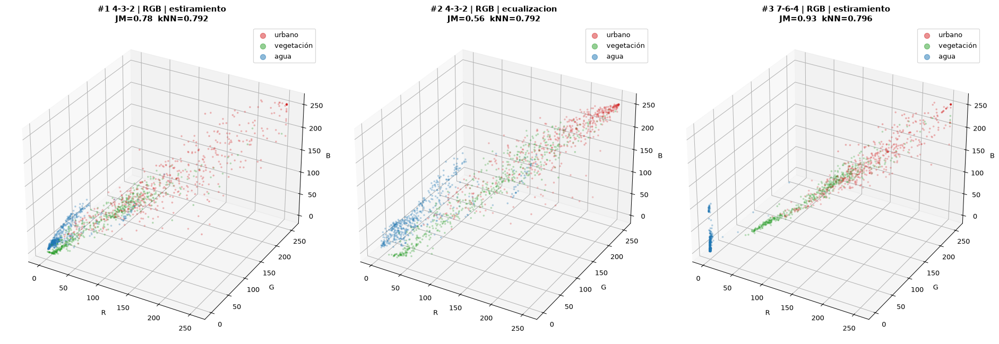

34 configuraciones disponibles en el visor 3D. Accesos rápidos:


,botón,configuración
0,🏆 Ganador principal,6-4-5 | LAB | ecualizacion
1,Ganador secundaria (7-6-4),7-6-4 | RGB | estiramiento
2,Top 1,4-3-2 | RGB | estiramiento
3,Top 2,4-3-2 | RGB | ecualizacion
4,Top 3,7-6-4 | RGB | estiramiento


In [15]:
# 7. Nubes 3D: estática (top-3) e interactiva rotatoria (top-5)
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "colab" if "google.colab" in sys.modules else "notebook_connected"

def coords_3d(pix_rgb, espacio):
    x = convertir_crudo(pix_rgb, espacio).astype(float)
    if espacio in ("HSV", "HLS"):
        ang = x[:, 0] * (2 * np.pi / 180.0)
        sat = x[:, 1] if espacio == "HSV" else x[:, 2]
        alt = x[:, 2] if espacio == "HSV" else x[:, 1]
        return np.column_stack([sat * np.cos(ang), sat * np.sin(ang), alt]), (
            "S·cosH", "S·sinH", "V" if espacio == "HSV" else "L")
    if espacio == "LAB":
        return x[:, [1, 2, 0]], ("a*", "b*", "L*")
    return x, ("R", "G", "B")

top_3d = df4b[df4b["espacio"] != "Gris"].drop_duplicates(["composición", "espacio", "realce"])
top5 = top_3d.head(5)
if "secundaria" not in set(top5["grupo"]) and (top_3d["grupo"] == "secundaria").any():
    top5 = pd.concat([top5.head(4), top_3d[top_3d["grupo"] == "secundaria"].head(1)])
N3D = 500
sub = {c: IDX[c][:N3D] for c in CLASES}

# Estática
fig = plt.figure(figsize=(21, 7), dpi=90)
for k, (_, f) in enumerate(top5.head(3).iterrows()):
    pix = componer(COMBOS[f["composición"]], f["realce"]).reshape(-1, 3)
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    for c in CLASES:
        xyz, ejes = coords_3d(pix[sub[c]], f["espacio"])
        ax.scatter(*xyz.T, s=4, alpha=0.5, color=COLOR_CLASE[c], label=CLASES[c])
    ax.set_xlabel(ejes[0]); ax.set_ylabel(ejes[1]); ax.set_zlabel(ejes[2])
    ax.set_title(f"#{k+1} {f['composición']} | {f['espacio']} | {f['realce']}\nJM={f['JM']:.2f}  kNN={f['kNN']:.3f}",
                 fontweight="bold")
    ax.legend(markerscale=4)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "07_nubes_3d_top3.png"), bbox_inches="tight")
plt.show()

# Interactiva: todas las composiciones x {RGB, HSV, HLS, LAB} con estiramiento + ganadores y top-3 con su realce.
# Cada configuración aporta 3 trazas (una por clase). Un desplegable elige la configuración (visibilidad),
# otro menú cambia el color (por clase o color real) y una fila de botones da acceso rápido a ganadores y top-3.
SIMBOLO = {1: "circle", 2: "diamond", 3: "square"}
N_INTERACTIVO = 300
sub_i = {c: IDX[c][:N_INTERACTIVO] for c in CLASES}
metricas_de = {(r["composición"], r["espacio"], r["realce"]): r
               for df in (df4a, df4b) for _, r in df.iterrows()}

configs_3d = [(combo, esp, "estiramiento") for combo in COMBOS for esp in ["RGB", "HSV", "HLS", "LAB"]]
destacadas = {"🏆 Ganador principal": (CONFIG["principal"]["combo"], CONFIG["principal"]["espacio"], CONFIG["principal"]["realce"]),
              "Ganador secundaria (7-6-4)": (CONFIG["secundaria"]["combo"], CONFIG["secundaria"]["espacio"], CONFIG["secundaria"]["realce"])}
for k, (_, f) in enumerate(top_3d.head(3).iterrows()):
    destacadas[f"Top {k+1}"] = (f["composición"], f["espacio"], f["realce"])
for cfg_3d in destacadas.values():
    if cfg_3d not in configs_3d:
        configs_3d.append(cfg_3d)

fig3d = go.Figure()
colores_clase, colores_reales, vistas = [], [], []
for i, (combo, esp, realce) in enumerate(configs_3d):
    pix = componer(COMBOS[combo], realce).reshape(-1, 3)
    for c in CLASES:
        p = pix[sub_i[c]]
        xyz, ejes = coords_3d(p, esp)
        fig3d.add_trace(go.Scatter3d(
            x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2], mode="markers", name=CLASES[c], legendgroup=CLASES[c],
            visible=(i == 0), customdata=[f"({r}, {g}, {b})" for r, g, b in p],
            marker=dict(size=3, color=COLOR_CLASE[c], symbol=SIMBOLO[c], opacity=0.75),
            hovertemplate=(f"<b>clase: {CLASES[c]}</b><br>{ejes[0]} = %{{x:.1f}}<br>{ejes[1]} = %{{y:.1f}}<br>"
                           f"{ejes[2]} = %{{z:.1f}}<br>RGB compuesto = %{{customdata}}<extra></extra>")))
        colores_clase.append(COLOR_CLASE[c])
        colores_reales.append([f"rgb({r},{g},{b})" for r, g, b in p])
    m = metricas_de.get((combo, esp, realce))
    puntaje = (f"JM urb–veg = {m['JM']:.2f} ↑ · k-NN = {m['kNN']:.3f} ↑ · Fisher = {m['Fisher']:.3f} ↑ · "
               f"OVL = {m['OVL']:.3f} ↓ · Silhouette = {m['Silhouette']:.3f} ↑") if m is not None else ""
    vis = [False] * (3 * len(configs_3d))
    vis[3 * i:3 * i + 3] = [True, True, True]
    vistas.append(dict(visible=vis, config=f"{combo} | {esp} | {realce}", puntaje=puntaje, ejes=ejes))

# Etiqueta de cada configuración en el desplegable: se marca si es ganadora o top
marcas = {}
for nombre, cfg_3d in destacadas.items():
    marcas.setdefault(cfg_3d, []).append(nombre.replace("🏆 ", ""))
etiquetas_menu = [f"{'🏆 ' if marcas.get(cfg) else ''}{v['config']}" + (f"  ({', '.join(marcas[cfg])})" if marcas.get(cfg) else "")
                  for cfg, v in zip(configs_3d, vistas)]

def args_vista(i, seleccion):
    """Muestra la configuración i; el título dice qué se seleccionó y el desplegable queda sincronizado."""
    v = vistas[i]
    titulo = (f"<b>Seleccionado: {seleccion}</b> → composición {v['config'].replace(' | ', ' · espacio ', 1).replace(' | ', ' · realce ')}"
              f"<br><span style='font-size:12px'>{v['puntaje']}</span>")
    return [{"visible": v["visible"]},
            {"title.text": titulo, "updatemenus[0].active": i,
             "scene.xaxis.title.text": v["ejes"][0], "scene.yaxis.title.text": v["ejes"][1],
             "scene.zaxis.title.text": v["ejes"][2]}]

menu_config = dict(type="dropdown", direction="down", x=0, y=1.20, xanchor="left", yanchor="top", active=0,
                   buttons=[dict(label=etiquetas_menu[i], method="update", args=args_vista(i, etiquetas_menu[i]))
                            for i in range(len(configs_3d))])
menu_color = dict(type="buttons", direction="right", x=0.55, y=1.20, xanchor="left", yanchor="top",
                  buttons=[dict(label="Color por clase", method="restyle", args=[{"marker.color": colores_clase}]),
                           dict(label="Color real", method="restyle", args=[{"marker.color": colores_reales}])])
menu_rapido = dict(type="buttons", direction="right", x=0, y=1.10, xanchor="left", yanchor="top", showactive=True,
                   buttons=[dict(label=nombre, method="update", args=args_vista(configs_3d.index(cfg_3d), nombre))
                            for nombre, cfg_3d in destacadas.items()])
titulo0 = args_vista(0, etiquetas_menu[0])[1]["title.text"]
fig3d.update_layout(
    title=dict(text=titulo0, y=0.97),
    updatemenus=[menu_config, menu_color, menu_rapido],
    scene=dict(xaxis_title=vistas[0]["ejes"][0], yaxis_title=vistas[0]["ejes"][1], zaxis_title=vistas[0]["ejes"][2]),
    annotations=[dict(text="Símbolos: ● urbano · ◆ vegetación · ■ agua (se mantienen en modo color real)",
                      x=0, y=0.98, xref="paper", yref="paper", xanchor="left", showarrow=False)],
    height=800, margin=dict(l=0, r=0, t=190, b=0),
    legend=dict(title="Clase (OSM)", itemsizing="constant"))
fig3d.write_html(os.path.join(IMG_DIR, "nubes_3d_interactivo.html"), include_plotlyjs="cdn")
fig3d.show()
print(f"{len(configs_3d)} configuraciones disponibles en el visor 3D. Accesos rápidos:")
display(pd.DataFrame([{"botón": n, "configuración": " | ".join(c)} for n, c in destacadas.items()]))

### Conclusión 7
- **Las nubes no son esferas.** En RGB, urbano y vegetación forman **bandas alargadas a lo largo de la diagonal de brillo**: el mismo material aparece más claro o más oscuro según iluminación y mezcla. Se tocan en la zona media, que corresponde a los barrios arbolados. Esa forma explica por qué Silhouette y K-Means rinden poco y por qué JM, con covarianza completa, y k-NN las separan mejor.
- **El agua es una nube compacta** y, en 7-6-4 y 6-4-5, completamente **apartada** del resto. Coincide con el JM urbano–agua = 2.0. En 4-3-2 la nube del agua queda pegada a la vegetación oscura y a parte de lo urbano.
- En **LAB (6-4-5)**, lo urbano ocupa la parte alta de $L^*$ y se separa hacia valores bajos de $a^*$, mientras la vegetación se extiende hacia $a^*$ alto. Es la separación por "eje cromático" que midió Fisher en a\*.
- En el visor interactivo (`imagenes_v2/nubes_3d_interactivo.html`) se puede comparar, por ejemplo, **6-5-4 en RGB contra 6-5-4 en HSV**. En HSV el matiz abre la nube en un "cono" donde la vegetación y lo urbano ocupan sectores angulares distintos, y por eso su JM (0.99) supera al de RGB (0.74). Al rotar las configuraciones se comprueba que el ranking coincide con lo que se ve: más superposición en el centro de la nube, peor puesto.
- Nota de uso: el **título** del gráfico siempre indica qué se seleccionó (por ejemplo "Seleccionado: Top 1 → composición 4-3-2 · espacio RGB · realce estiramiento") junto con sus métricas. El desplegable se sincroniza también al usar los botones de acceso rápido, y en él las configuraciones ganadoras y del top 3 aparecen marcadas con 🏆.

### Bitácora — sección 7
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Coordenadas HSV y HLS | Cilíndricas (S·cosH, S·sinH, V o L) | El matiz es un ángulo; sin corte en 0/179 | H, S y V crudos como ejes | Nube "partida" en el rojo | Notebook 1 |
| Configuraciones | 34: todas las composiciones × 4 espacios + ganadores y top 3 | Comparar cualquier combinación | Sólo el top 5 | No dejaba ver, por ejemplo, la 6-5-4 en HSV | Pedido |
| Puntos | 300 por clase y configuración | Archivo HTML liviano (~2 MB) y fluido | Todos los píxeles | Archivo enorme | Tiempo |
| Escala de grises | Excluida del 3D | Tiene un solo canal | — | — | — |

## 8. Segmentación por umbralización

Los ejemplos de la cátedra muestran dos formas de umbralizar:

- **Notebook 3 (*Umbral interactivo*):** un umbral sobre **un solo canal** con `cv2.threshold`, incluido el método de **Otsu**, que elige automáticamente el umbral que mejor separa un histograma bimodal (maximiza la varianza entre clases).
- **Notebook 1 (*Segmentación por color*):** una **caja** de rangos $[min, max]$ en cada canal (RGB o HSV), ajustada con sliders.

**¿Qué se umbraliza?** Umbralizar es decidir, píxel por píxel, si el valor de **un canal** cae de un lado u otro de un **valor de corte**. El resultado es una **máscara binaria**: blanco = "urbano", negro = "no urbano". Cada máscara de esta sección umbraliza un canal distinto, que sale de las secciones 5 y 6:

| Máscara | Imagen de partida | Canal que se umbraliza (valores 0–255) | Por qué ese canal |
|---|---|---|---|
| **Otsu (principal)** | composición 6-4-5 con ecualización (ganadora principal, sección 5b) | **a\* de LAB** | es el mejor canal individual de la principal (tabla de la sección 6) |
| **Caja (principal)** | la misma 6-4-5 con ecualización, en LAB (su espacio ganador) | **L\* de LAB** (a\* y b\* se descartan) | es el único canal de LAB cuya "caja" urbana deja afuera algo de vegetación |
| **Otsu (secundaria)** | composición 7-6-4 con estiramiento (ganadora secundaria) | **S de HSV** | mejor canal individual de la secundaria |
| **Caja (secundaria)** | la misma 7-6-4, en RGB (su espacio ganador) | **R de RGB, que es la banda B7 (SWIR 2) estirada** (G y B se descartan) | ídem |
| **NDBI > 0** | reflectancias B6 y B5, sin composición | el **índice NDBI** = (B6 − B5)/(B6 + B5), entre −1 y 1 | referencia clásica de teledetección |

La celda de código imprime esta misma tabla con los **valores de corte calculados** (por ejemplo "a\* ≤ 126").

- Con **un canal**, basta un número (el umbral $t$): urbano si el valor es $\le t$ (o $> t$, según el sentido).
- Con una **caja** se usan varios canales a la vez. Para cada uno se fija un rango $[\min, \max]$, y un píxel es urbano sólo si **todos** sus canales caen dentro de su rango. En 3 canales eso son **6 números**. Por ejemplo, en LAB: $L^* \in [112, 241]$, $a^* \in [76, 171]$, $b^* \in [68, 203]$.

**El problema de la caja es qué valores elegir.** En el Notebook 1 de la cátedra esos 6 números se ajustan con sliders, mirando la imagen "a ojo". Con tantos valores posibles es fácil elegir una caja que se vea bien en una zona y falle en otra, y además el resultado depende de quién la ajuste. La recomendación es **no elegirlos a ojo, sino derivarlos de los datos**:

1. **Otsu sobre el mejor canal individual** de la sección 6 (menor OVL urbano–vegetación). El umbral sale solo del histograma, y el sentido (mayor o menor) se toma de las medias de cada clase.
2. **Caja por percentiles:** en los bloques de **entrenamiento**, se toma el intervalo $[P_5, P_{95}]$ de la clase urbana en cada canal crudo del espacio ganador. Sólo se conservan los canales donde ese intervalo deja afuera al menos la mitad de la vegetación; los demás no discriminan y sólo agregan ruido. El matiz H se excluye por ser circular.
3. **Caja manual con sliders** (`ipywidgets`, como en el Notebook 1), sobre **los tres canales de LAB** (L\*, a\* y b\*) de la principal. Arranca en los valores de la variable `AJUSTE_MANUAL`, que hoy guarda el ajuste final elegido con los sliders (L\* ∈ [171, 255], a\* ∈ [53, 149], b\* ∈ [90, 206]); con `None` arrancaría en los percentiles 5–95 de lo urbano. Se ajusta a mano mirando la imagen, el IoU y los km² en vivo. La máscara que resulta entra como un método más, **"Caja manual (principal)"**, en la validación de la sección 10 y en la comparación de km². Para fijar un ajuste encontrado, se copian sus rangos en la variable `AJUSTE_MANUAL` de la celda 8.3.
4. **Referencia clásica de teledetección:** el índice **NDBI** = (SWIR1 − NIR) / (SWIR1 + NIR) > 0, calculado sobre reflectancias.

Todo se aplica en paralelo a la configuración **principal** y a la **secundaria**.

**¿Cómo se mide si la máscara está bien? IoU (*Intersection over Union*, índice de Jaccard):**
$$\text{IoU} = \frac{|\text{máscara} \cap \text{OSM urbano}|}{|\text{máscara} \cup \text{OSM urbano}|}$$

Es la cantidad de píxeles que **ambos** marcan como urbano, dividida por la cantidad que marca **al menos uno** de los dos. Vale 1 si la máscara coincide exactamente con OSM y 0 si no tienen nada en común. Penaliza por igual marcar de más (falsos positivos) y de menos (falsos negativos). Como referencia, IoU = 0.5 significa que la parte compartida es la mitad de todo lo marcado entre los dos. Se calcula sólo en los **bloques de prueba** y sobre los píxeles que OSM etiqueta.

[principal] 6-4-5 | LAB | ecualizacion
   Otsu sobre LAB-a*: umbral = 126 (urbano <= umbral)  -> IoU test = 0.428
   Caja: límites urbano P5–P95 = {'L*': (112, 241), 'a*': (76, 171), 'b*': (68, 203)}
         fracción de vegetación dentro del intervalo = {'L*': 0.63, 'a*': 0.82, 'b*': 0.82}
         canales usados = ['L*']  -> IoU test = 0.521
[secundaria] 7-6-4 | RGB | estiramiento
   Otsu sobre HSV-S: umbral = 123 (urbano <= umbral)  -> IoU test = 0.525
   Caja: límites urbano P5–P95 = {'R': (78, 255), 'G': (132, 246), 'B': (40, 253)}
         fracción de vegetación dentro del intervalo = {'R': 0.62, 'G': 0.63, 'B': 0.63}
         canales usados = ['R']  -> IoU test = 0.571
NDBI > 0 -> IoU test = 0.090 | mediana de NDBI por clase (píxeles puros): urbano = -0.158, vegetación = -0.302, agua = +0.998

Qué se umbraliza exactamente en cada máscara (valores de 0 a 255 del canal indicado, salvo el NDBI):


máscara,imagen de partida,espacio,canal umbralizado,regla (urbano si…)
NDBI > 0,reflectancias B6 y B5 (sin composición),—,índice NDBI = (B6 − B5)/(B6 + B5),NDBI > 0
Otsu (principal),composición 6-4-5 con ecualizacion,LAB,a*,a* ≤ 126
Caja P5–P95 (principal),composición 6-4-5 con ecualizacion,LAB,L*,112 ≤ L* ≤ 241
Otsu (secundaria),composición 7-6-4 con estiramiento,HSV,S,S ≤ 123
Caja P5–P95 (secundaria),composición 7-6-4 con estiramiento,RGB,R (= banda B7),78 ≤ R ≤ 255


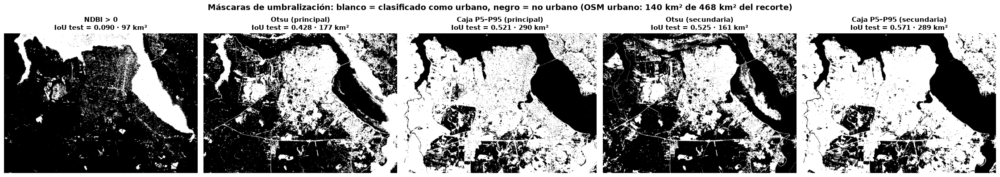

In [16]:
# 8. Umbralizaciones derivadas de los datos
from sklearn.metrics import f1_score, jaccard_score, precision_score, recall_score

etiquetado_test = es_test & (etiquetas > 0)

def iou_test(mascara):
    """IoU de la máscara urbana contra OSM completo, en los píxeles etiquetados de los bloques de prueba."""
    return jaccard_score(etiquetas[etiquetado_test] == 1, mascara[etiquetado_test])

def umbral_otsu(cfg, fila_canal):
    crudo = convertir_crudo(cfg["rgb"], fila_canal["espacio"])
    canal = np.ascontiguousarray(crudo[..., CANALES_CRUDOS[fila_canal["espacio"]].index(fila_canal["canal"])])
    t, _ = cv2.threshold(canal, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return (canal > t) if fila_canal["urbano > vegetación"] else (canal <= t), t

def caja_percentiles(cfg):
    esp = cfg["espacio"]
    crudo = convertir_crudo(cfg["rgb"], esp)
    urb_tr, veg_tr = (puras == 1) & ~es_test, (puras == 2) & ~es_test
    limites, fraccion_veg = {}, {}
    for j, canal in enumerate(CANALES_CRUDOS[esp]):
        if canal == "H":
            continue
        lo, hi = np.percentile(crudo[..., j][urb_tr], (5, 95))
        v = crudo[..., j][veg_tr]
        limites[canal] = (int(lo), int(hi))
        fraccion_veg[canal] = float(((v >= lo) & (v <= hi)).mean())
    usados = [c for c, fr in fraccion_veg.items() if fr < 0.5] or [min(fraccion_veg, key=fraccion_veg.get)]
    mascara = np.ones((H, W), bool)
    for canal in usados:
        lo, hi = limites[canal]
        j = CANALES_CRUDOS[esp].index(canal)
        mascara &= (crudo[..., j] >= lo) & (crudo[..., j] <= hi)
    return mascara, limites, fraccion_veg, usados

KM2_PIXEL = PIXEL * PIXEL / 1e6           # cada píxel de 30 m × 30 m = 0.0009 km²

def nombre_canal(cfg, espacio, canal):
    """Nombre del canal, aclarando qué banda Landsat es cuando el espacio es RGB."""
    if espacio == "RGB":
        return f"{canal} (= banda B{cfg['combo'].split('-')['RGB'.index(canal)]})"
    return canal

ndbi = (REFL[6] - REFL[5]) / (REFL[6] + REFL[5] + 1e-6)
MASCARAS = {"NDBI > 0": ndbi > 0}
QUE_SE_UMBRALIZA = [{"máscara": "NDBI > 0", "imagen de partida": "reflectancias B6 y B5 (sin composición)",
                     "espacio": "—", "canal umbralizado": "índice NDBI = (B6 − B5)/(B6 + B5)",
                     "regla (urbano si…)": "NDBI > 0"}]
CAJAS = {}
for nombre, cfg in CONFIG.items():
    m_otsu, t = umbral_otsu(cfg, MEJOR_CANAL[nombre])
    MASCARAS[f"Otsu ({nombre})"] = m_otsu
    m_caja, limites, frac, usados = caja_percentiles(cfg)
    MASCARAS[f"Caja P5–P95 ({nombre})"] = m_caja
    CAJAS[nombre] = limites
    f = MEJOR_CANAL[nombre]
    imagen = f"composición {cfg['combo']} con {cfg['realce']}"
    QUE_SE_UMBRALIZA.append({
        "máscara": f"Otsu ({nombre})", "imagen de partida": imagen, "espacio": f["espacio"],
        "canal umbralizado": nombre_canal(cfg, f["espacio"], f["canal"]),
        "regla (urbano si…)": f"{f['canal']} {'>' if f['urbano > vegetación'] else '≤'} {t:.0f}"})
    QUE_SE_UMBRALIZA.append({
        "máscara": f"Caja P5–P95 ({nombre})", "imagen de partida": imagen, "espacio": cfg["espacio"],
        "canal umbralizado": ", ".join(nombre_canal(cfg, cfg["espacio"], c) for c in usados),
        "regla (urbano si…)": " y ".join(f"{limites[c][0]} ≤ {c} ≤ {limites[c][1]}" for c in usados)})
    print(f"[{nombre}] {cfg['etiqueta']}")
    print(f"   Otsu sobre {f['espacio']}-{f['canal']}: umbral = {t:.0f} "
          f"({'urbano > umbral' if f['urbano > vegetación'] else 'urbano <= umbral'})  -> IoU test = {iou_test(m_otsu):.3f}")
    print(f"   Caja: límites urbano P5–P95 = {limites}")
    print(f"         fracción de vegetación dentro del intervalo = { {k: round(v, 2) for k, v in frac.items()} }")
    print(f"         canales usados = {usados}  -> IoU test = {iou_test(m_caja):.3f}")
print(f"NDBI > 0 -> IoU test = {iou_test(MASCARAS['NDBI > 0']):.3f} | mediana de NDBI por clase (píxeles puros): "
      + ", ".join(f"{CLASES[c]} = {np.median(ndbi[puras == c]):+.3f}" for c in CLASES))

print("\nQué se umbraliza exactamente en cada máscara (valores de 0 a 255 del canal indicado, salvo el NDBI):")
display(pd.DataFrame(QUE_SE_UMBRALIZA).style.hide(axis="index"))

AREA_OSM = (etiquetas == 1).sum() * KM2_PIXEL
fig, axes = plt.subplots(1, len(MASCARAS), figsize=(5 * len(MASCARAS), 4.8), dpi=90)
for ax, (nombre, m) in zip(axes, MASCARAS.items()):
    ax.imshow(m, cmap="gray")
    ax.set_title(f"{nombre}\nIoU test = {iou_test(m):.3f} · {m.sum() * KM2_PIXEL:.0f} km²", fontweight="bold")
    ax.axis("off")
plt.suptitle(f"Máscaras de umbralización: blanco = clasificado como urbano, negro = no urbano "
             f"(OSM urbano: {AREA_OSM:.0f} km² de {H * W * KM2_PIXEL:.0f} km² del recorte)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "08_umbralizaciones.png"), bbox_inches="tight")
plt.show()

In [17]:
# 8.3 Ajuste fino interactivo de la caja (configuración principal), al estilo del Notebook 1
import ipywidgets as widgets

cfg_p = CONFIG["principal"]
crudo_p = convertir_crudo(cfg_p["rgb"], cfg_p["espacio"])

# Valores iniciales de la caja manual. Si se encuentra un ajuste que convence, se copian acá los rangos
# de los sliders (por ejemplo {"L*": (120, 230), "a*": (80, 125), "b*": (110, 200)}) para que queden fijos
# al volver a ejecutar el notebook. Con None se arranca de los percentiles 5–95 de lo urbano en los 3 canales.
AJUSTE_MANUAL = {"L*": (171, 255), "a*": (53, 149), "b*": (90, 206)}   # ajuste manual elegido con los sliders

sliders = {}
for j, canal in enumerate(CANALES_CRUDOS[cfg_p["espacio"]]):
    tope = 179 if canal == "H" else 255
    ini = (AJUSTE_MANUAL or CAJAS["principal"]).get(canal, (0, tope))
    sliders[canal] = widgets.IntRangeSlider(value=list(ini), min=0, max=tope, description=canal,
                                            continuous_update=False, layout=widgets.Layout(width="420px"))

def caja_manual(rangos):
    m = np.ones((H, W), bool)
    for canal, (lo, hi) in rangos.items():
        j = CANALES_CRUDOS[cfg_p["espacio"]].index(canal)
        m &= (crudo_p[..., j] >= lo) & (crudo_p[..., j] <= hi)
    return m

def mascara_caja_manual():
    """Máscara con los valores ACTUALES de los sliders (la usan también las secciones 10 y 10.2)."""
    return caja_manual({canal: s.value for canal, s in sliders.items()})

def ver_caja(**rangos):
    m = caja_manual(rangos)
    resaltado = cfg_p["rgb"].copy()
    resaltado[m] = (255, 255, 0)
    plt.figure(figsize=(9, 6.5), dpi=80)
    plt.imshow(resaltado)
    plt.title(f"Caja manual en {cfg_p['espacio']} ({cfg_p['combo']}) — IoU test = {iou_test(m):.3f} · "
              f"{m.sum() * KM2_PIXEL:.0f} km² (OSM: {AREA_OSM:.0f} km²)", fontweight="bold")
    plt.axis("off")
    plt.show()

display(widgets.HTML(f"<b>Ajustá los rangos de {cfg_p['espacio']} (iniciados en AJUSTE_MANUAL, o en P5–P95 de la clase urbana si es None). "
                     f"Para dejar un canal sin restricción, abrí su rango completo. Las secciones 10 y 10.2 usan los "
                     f"valores que tengan los sliders cuando se ejecuten.</b>"))
display(widgets.VBox(list(sliders.values())), widgets.interactive_output(ver_caja, sliders))

MASCARAS["Caja manual (principal)"] = mascara_caja_manual()
print("Caja manual inicial: " + " y ".join(f"{s.value[0]} ≤ {c} ≤ {s.value[1]}" for c, s in sliders.items()))

# Segunda caja manual: ajuste corregido guiado por los histogramas por clase (sección 8.4):
# claro (L* alto), a* bajo (tonos verde-amarillo de lo urbano en la 6-4-5) y b* sin restringir
AJUSTE_CORREGIDO = {"L*": (150, 255), "a*": (0, 126), "b*": (0, 255)}
MASCARAS["Caja manual corregida (principal)"] = caja_manual(AJUSTE_CORREGIDO)
print("Caja manual corregida: " + " y ".join(f"{lo} ≤ {c} ≤ {hi}" for c, (lo, hi) in AJUSTE_CORREGIDO.items()))

HTML(value='<b>Ajustá los rangos de LAB (iniciados en AJUSTE_MANUAL, o en P5–P95 de la clase urbana si es None…

Output()

Caja manual inicial: 171 ≤ L* ≤ 255 y 53 ≤ a* ≤ 149 y 90 ≤ b* ≤ 206
Caja manual corregida: 150 ≤ L* ≤ 255 y 0 ≤ a* ≤ 126 y 0 ≤ b* ≤ 255


### 8.4 Máscara del ajuste manual y su coincidencia con OSM

Esta subsección compara **dos cajas manuales** con la referencia de OpenStreetMap:
- **Caja manual (ajuste propio):** los valores que tengan los sliders, que al ejecutar el notebook son los de `AJUSTE_MANUAL`, elegidos con los sliders mirando el IoU y los km² en vivo.
- **Caja manual corregida:** `AJUSTE_CORREGIDO`, elegido mirando los **histogramas por clase**: L\* alto, a\* bajo y b\* sin restringir.

Para cada una se mide:

1. **Coincidencia con OSM:** IoU, F1, precisión y recall en los bloques de prueba, y los km² sobre todo el recorte: total, coincidentes, marcados de más y de menos.
2. **Diagnóstico canal por canal:** qué fracción de los píxeles **puros** de cada clase cae dentro del rango elegido en cada canal, y dentro de la caja completa. Una caja útil deja entrar mucho urbano y poca vegetación y agua.
3. **Histogramas por clase con el rango elegido sombreado:** muestran si cada rango está sobre la distribución urbana o sobre la de otra clase.
4. **Mapa de aciertos y errores** de la máscara contra OSM.

Caja manual evaluada: 171 ≤ L* ≤ 255 y 53 ≤ a* ≤ 149 y 90 ≤ b* ≤ 206


caja,rangos,Área marcada (km²),Área urbana OSM (km²),Coincide con OSM urbano (km²) ↑,Marca de más (km²) ↓,Marca de menos (km²) ↓,IoU ↑,F1 ↑,Precisión ↑,Recall ↑
Caja manual (ajuste propio),171 ≤ L* ≤ 255 y 53 ≤ a* ≤ 149 y 90 ≤ b* ≤ 206,150.5,139.9,93.8,35.0,46.1,0.540,0.701,0.745,0.662
Caja manual corregida (histogramas),150 ≤ L* ≤ 255 y 0 ≤ a* ≤ 126 y 0 ≤ b* ≤ 255,122.4,139.9,88.2,25.6,51.6,0.533,0.696,0.786,0.624


↑ mayor es mejor · ↓ menor es mejor


condición,% urbano dentro,% vegetación dentro,% agua dentro,mediana urbana de L*,mediana urbana de a*,mediana urbana de b*
171 ≤ L* ≤ 255,71.1,29.6,0.2,199.0,—,—
53 ≤ a* ≤ 149,83.0,45.3,99.7,—,113.0,—
90 ≤ b* ≤ 206,86.1,63.1,99.9,—,—,163.0
caja completa (todas a la vez),65.9,20.5,0.1,—,—,—


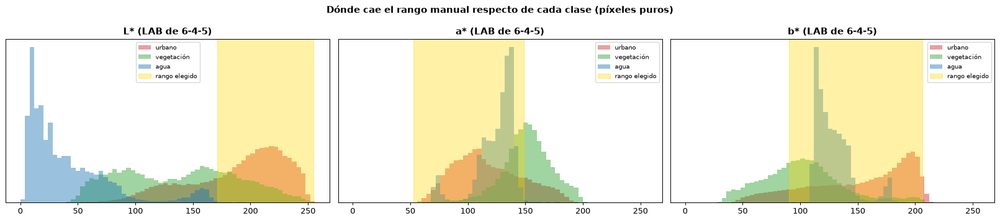

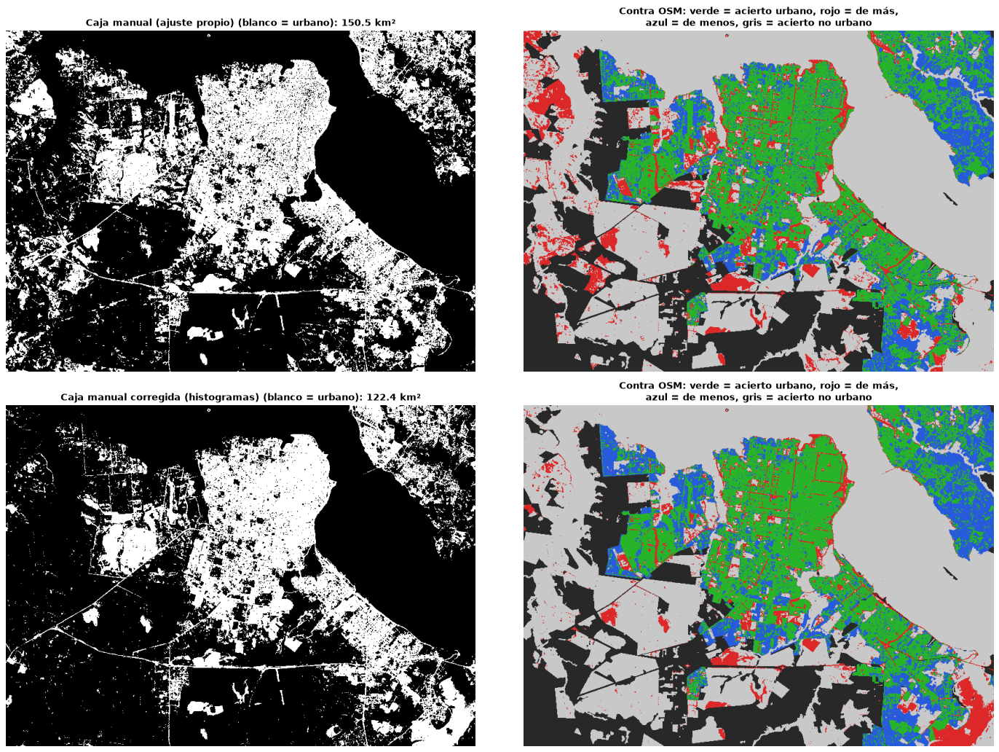

In [18]:
# 8.4 Coincidencia de la caja manual con OSM y diagnóstico canal por canal
rangos_man = {canal: s.value for canal, s in sliders.items()}
m_man = caja_manual(rangos_man)
print("Caja manual evaluada: " + " y ".join(f"{lo} ≤ {c} ≤ {hi}" for c, (lo, hi) in rangos_man.items()))

# 1. Coincidencia con OSM (bloques de prueba) y área (todo el recorte) de las dos cajas manuales
m_corr = MASCARAS["Caja manual corregida (principal)"]
y_ref = (etiquetas == 1)[etiquetado_test]
filas_coinc = []
for nombre, rangos, m in [("Caja manual (ajuste propio)", rangos_man, m_man),
                          ("Caja manual corregida (histogramas)", AJUSTE_CORREGIDO, m_corr)]:
    y_m = m[etiquetado_test]
    filas_coinc.append({
        "caja": nombre, "rangos": " y ".join(f"{lo} ≤ {c} ≤ {hi}" for c, (lo, hi) in rangos.items()),
        "Área marcada (km²)": m.sum() * KM2_PIXEL, "Área urbana OSM (km²)": AREA_OSM,
        "Coincide con OSM urbano (km²) ↑": (m & (etiquetas == 1)).sum() * KM2_PIXEL,
        "Marca de más (km²) ↓": (m & (etiquetas > 1)).sum() * KM2_PIXEL,
        "Marca de menos (km²) ↓": (~m & (etiquetas == 1)).sum() * KM2_PIXEL,
        "IoU ↑": jaccard_score(y_ref, y_m, zero_division=0), "F1 ↑": f1_score(y_ref, y_m, zero_division=0),
        "Precisión ↑": precision_score(y_ref, y_m, zero_division=0), "Recall ↑": recall_score(y_ref, y_m, zero_division=0)})
coincidencia = pd.DataFrame(filas_coinc)
display(coincidencia.style.format(precision=3).format(precision=1, subset=[c for c in coincidencia.columns if "km²" in c])
        .hide(axis="index"))
print(LEYENDA)

# 2. Diagnóstico: % de píxeles puros de cada clase que caen dentro del rango de cada canal y de la caja completa
filas_diag = []
for canal, (lo, hi) in rangos_man.items():
    j = CANALES_CRUDOS[cfg_p["espacio"]].index(canal)
    dentro = (crudo_p[..., j] >= lo) & (crudo_p[..., j] <= hi)
    filas_diag.append({"condición": f"{lo} ≤ {canal} ≤ {hi}",
                       **{f"% {CLASES[c]} dentro": 100 * dentro[puras == c].mean() for c in CLASES},
                       f"mediana urbana de {canal}": float(np.median(crudo_p[..., j][puras == 1]))})
filas_diag.append({"condición": "caja completa (todas a la vez)",
                   **{f"% {CLASES[c]} dentro": 100 * m_man[puras == c].mean() for c in CLASES}})
display(pd.DataFrame(filas_diag).style.format(precision=1, na_rep="—").hide(axis="index"))

# 3. Histogramas por clase de cada canal, con el rango elegido sombreado
fig, axes = plt.subplots(1, len(rangos_man), figsize=(6 * len(rangos_man), 4), dpi=90)
for ax, (canal, (lo, hi)) in zip(np.atleast_1d(axes), rangos_man.items()):
    j = CANALES_CRUDOS[cfg_p["espacio"]].index(canal)
    canal_img = np.ascontiguousarray(crudo_p[..., j])
    for c in CLASES:
        hist = cv2.calcHist([canal_img], [0], (puras == c).astype(np.uint8), [64], [0, 256]).ravel()
        ax.stairs(hist / hist.sum(), np.linspace(0, 256, 65), fill=True, alpha=0.45, color=COLOR_CLASE[c],
                  label=CLASES[c])
    ax.axvspan(lo, hi, color="gold", alpha=0.35, label="rango elegido")
    ax.set_title(f"{canal} ({cfg_p['espacio']} de {cfg_p['combo']})", fontweight="bold")
    ax.set_yticks([])
    ax.legend(fontsize=8)
plt.suptitle("Dónde cae el rango manual respecto de cada clase (píxeles puros)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "08_caja_manual_diagnostico.png"), bbox_inches="tight")
plt.show()

# 4. Máscaras y mapas de aciertos/errores contra OSM de las dos cajas manuales
ref, con_dato_ = etiquetas == 1, etiquetas > 0
fig, axes = plt.subplots(2, 2, figsize=(18, 13), dpi=80)
for fila, (nombre, m) in enumerate([("Caja manual (ajuste propio)", m_man), ("Caja manual corregida (histogramas)", m_corr)]):
    viz = np.full((H, W, 3), 40, np.uint8)
    viz[con_dato_ & ref & m] = (40, 180, 40)
    viz[con_dato_ & ~ref & m] = (220, 40, 40)
    viz[con_dato_ & ref & ~m] = (40, 90, 220)
    viz[con_dato_ & ~ref & ~m] = (200, 200, 200)
    axes[fila, 0].imshow(m, cmap="gray")
    axes[fila, 0].set_title(f"{nombre} (blanco = urbano): {m.sum() * KM2_PIXEL:.1f} km²", fontweight="bold")
    axes[fila, 1].imshow(viz)
    axes[fila, 1].set_title("Contra OSM: verde = acierto urbano, rojo = de más,\nazul = de menos, gris = acierto no urbano",
                            fontweight="bold")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "08_caja_manual_vs_osm.png"), bbox_inches="tight")
plt.show()

#### Lectura del ajuste manual
Con el ajuste final, elegido con los sliders mirando el IoU y los km² en vivo (171 ≤ L\* ≤ 255, 53 ≤ a\* ≤ 149, 90 ≤ b\* ≤ 206), la caja marca **150.5 km²**, un 7.6 % más que OSM (140 km²), y llega a **IoU 0.540** en los bloques de prueba. El diagnóstico canal por canal muestra qué aporta cada rango:

| Canal | Rango elegido | % de lo urbano que entra | % de vegetación | % de agua | Lectura |
|---|---|---|---|---|---|
| **L\*** | 171–255 | 71.1 % | 29.6 % | 0.2 % | **hace casi todo el trabajo**: deja afuera el agua y 7 de cada 10 píxeles de vegetación. Corta por debajo de la mediana urbana (199), así que pierde sobre todo los barrios más oscuros, los arbolados |
| **a\*** | 53–149 | 83.0 % | 45.3 % | 99.7 % | **está del lado correcto**: contiene la mediana urbana (113, tonos verde-amarillo en la 6-4-5) y excluye los a\* altos (tonos magenta), que son vegetación. No filtra el agua, pero de eso ya se encarga L\* |
| **b\*** | 90–206 | 86.1 % | 63.1 % | 99.9 % | casi no discrimina: deja entrar la mayor parte de todas las clases |
| **Caja completa** | las tres a la vez | **65.9 %** | **20.5 %** | **0.1 %** | sumar a\* y b\* baja la vegetación de 29.6 % a 20.5 %, a cambio de perder 5 puntos de lo urbano (71.1 % → 65.9 %) |

**Cómo se llegó a este ajuste.** Un primer intento hecho sólo mirando la imagen (221 ≤ L\* ≤ 241, 182 ≤ a\* ≤ 224, 134 ≤ b\* ≤ 195) daba una **máscara vacía**. En la composición 6-4-5 ecualizada lo urbano se ve verde-amarillo, y eso en LAB es **a\* bajo**; el rango de a\* de ese intento estaba sobre los tonos magenta, donde sólo hay vegetación. Además, cada canal que se agrega es una condición más que todos los píxeles deben cumplir, así que una caja angosta se vacía rápido. Con el IoU y los km² a la vista, el rango de a\* pasó al lado urbano y la caja se abrió.

**Caja manual corregida**, guiada por los histogramas: `AJUSTE_CORREGIDO = {"L*": (150, 255), "a*": (0, 126), "b*": (0, 255)}`. Es decir, claro, con a\* bajo y sin restringir b\*, porque b\* no discrimina. Las tres cajas de la principal contra OSM (tabla de arriba y sección 10.2):

| | Ajuste propio (sliders) | Corregida (histogramas) | Caja automática P5–P95 (principal) |
|---|---|---|---|
| IoU ↑ | **0.540** | 0.533 | 0.521 |
| F1 ↑ | **0.701** | 0.696 | 0.685 |
| Precisión ↑ | 0.745 | **0.786** | 0.556 |
| Recall ↑ | 0.662 | 0.624 | **0.892** |
| Área marcada (OSM: 140 km²) | **150.5 km²** | 122.4 km² | 290.3 km² |
| Coincide con OSM urbano ↑ | 93.8 km² | 88.2 km² | **125.8 km²** |
| Marca de más ↓ | 35.0 km² | **25.6 km²** | 96.0 km² |
| Marca de menos ↓ | 46.1 km² | 51.6 km² | **14.1 km²** |

- **Tu ajuste y la corregida casi empatan en IoU** (0.540 y 0.533), pero reparten distinto el error:
  - tu ajuste encuentra más ciudad: recall 0.662 contra 0.624 y 94 contra 88 km² coincidentes;
  - la corregida marca menos campo: precisión 0.786 contra 0.745 y 26 contra 35 km² de más.
- La diferencia está en dos cortes: tu ajuste exige más brillo (L\* ≥ 171 contra 150), pero admite a\* más altos (hasta 149 contra 126), hacia el lado de la vegetación, donde caen los píxeles mezclados de los barrios arbolados. En el mapa se ve: cubre más barrios periféricos y suma manchas sueltas de campo al oeste.
- Tu ajuste da el **área total más cercana a OSM** entre las umbralizaciones (+7.6 %, contra −12.5 % de la corregida).
- La caja automática hace lo contrario que las manuales: encuentra casi toda la ciudad, pero duplica el área con campo.

**Qué enseña.** El ajuste manual funciona cuando se guía por una **medida**: el IoU y los km² en vivo, o los histogramas por clase (sección 6 y figura de arriba), donde el rango de cada canal debe quedar sobre la joroba urbana y lejos de la de vegetación y la de agua. Mirando sólo la imagen, el primer intento quedó vacío.

### Conclusión 8
- **Caja por percentiles (P5–P95):** mejor umbralización, con IoU de prueba **0.571** en la secundaria 7-6-4 y **0.521** en la principal 6-4-5. Ningún canal cumplió el criterio de dejar afuera la mitad de la vegetación (todos dejan entrar entre el 62 y el 82 %). La regla se quedó entonces con el mejor canal solo: R (= B7, SWIR 2) en 7-6-4 y L\* en 6-4-5. El resultado tiene **recall muy alto (0.89–0.95) y precisión baja (0.56–0.59)**: encuentra casi todo lo urbano, pero también marca suelo desnudo y vegetación clara.
- **Otsu sobre el mejor canal:** IoU 0.525 (S de HSV en 7-6-4) y 0.428 (a\* en 6-4-5). Otsu supone un histograma **bimodal** y acá hay tres clases, de modo que el umbral queda entre agua y "resto" más que entre urbano y vegetación.
- **NDBI > 0 fracasa** (IoU 0.090), y en su máscara se ve por qué: lo que queda en blanco es casi sólo **el río**. Hay dos problemas, y las medianas por clase los muestran (urbano −0.158, vegetación −0.302, agua +0.998):
  1. **Lo urbano de Posadas tiene NDBI negativo.** La ciudad es muy arbolada y el NIR de las copas pesa en cada píxel. El umbral 0 de la literatura viene de ciudades áridas y aquí no aplica: el índice ordena bien urbano y vegetación, pero con otro umbral.
  2. **El agua da NDBI ≈ +1.** En el agua el NIR vale prácticamente 0, así que $(SWIR_1 - NIR)/(SWIR_1 + NIR) \approx SWIR_1/SWIR_1 = 1$ aunque ambas reflectancias sean casi nulas. El NDBI sólo sirve después de enmascarar el agua.

**Cómo leer la figura de máscaras** (blanco = urbano):

| Máscara | Qué marca | IoU |
|---|---|---|
| **NDBI > 0** | sobre todo el agua; casi nada de la ciudad | 0.090 |
| **Otsu (principal)**, a\* de 6-4-5 ≤ 126 | la ciudad, pero también muchas pasturas | 0.428 |
| **Caja P5–P95 (principal)**, sólo L\* ∈ [112, 241] | la ciudad entera, pero también buena parte del campo, porque basta con ser "claro" (recall alto, precisión baja); deja afuera el agua y la plantación oscura | 0.521 |
| **Otsu (secundaria)**, S de HSV de 7-6-4 ≤ 123 | ciudad y algunos campos poco saturados | 0.525 |
| **Caja P5–P95 (secundaria)**, sólo R = SWIR 2 ∈ [78, 255] | todo lo que refleja en el SWIR 2: ciudad, suelo y pasturas secas; afuera el agua y el monte húmedo | **0.571**, la mejor |
| **Caja manual (principal)**, ajuste final con los sliders: L\* ∈ [171, 255], a\* ∈ [53, 149], b\* ∈ [90, 206] | la ciudad y buena parte de los barrios periféricos, con manchas sueltas de campo al oeste (ver sección 8.4) | **0.540**, la mejor de la principal |
| **Caja manual corregida (principal)**, guiada por los histogramas: L\* ∈ [150, 255], a\* ∈ [0, 126], b\* libre | el núcleo de la ciudad, con muy poco campo; pierde barrios arbolados | 0.533, la más precisa |

En las cuatro máscaras de color la ciudad aparece entera en blanco: el problema no es "no encontrar" lo urbano, sino **marcar también campo**. Esto confirma lo visto en las firmas espectrales: el suelo y las pasturas secas se parecen a lo urbano.
- **Caja manual:** con los sliders y el IoU a la vista llega a **0.540**, por encima de la caja automática (0.521) y de Otsu (0.428) de la principal, y marca 150.5 km² contra 140 de OSM. El primer intento, sólo mirando la imagen, daba una máscara vacía: el ajuste manual sirve si se guía por una medida.
- **Recomendación:** derivar los umbrales de los datos, con percentiles de una clase etiquetada u Otsu, y no fijarlos a ojo. Después, ajustarlos con los sliders mirando el IoU. Como ningún canal solo separa bien, conviene pasar a métodos multicanal (sección 9).

### Bitácora — sección 8
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Umbral de un canal | Otsu sobre el mejor canal | Automático, sale del histograma | Umbral a ojo | Subjetivo | Notebook 3 |
| Caja | Percentiles 5–95 de lo urbano en los bloques de entrenamiento; sólo canales que dejan fuera ≥ 50 % de la vegetación | Derivada de los datos | Sliders a ojo (Notebook 1) | 6 números arbitrarios | Métrica |
| Caja manual | Sliders con el IoU y los km² en vivo; valores fijados en `AJUSTE_MANUAL` | Reproducible al volver a ejecutar | Ajuste a ojo sólo sobre la imagen | Primer intento con a\* alto: máscara vacía | Métrica |
| Índice | NDBI > 0 como referencia | Clásico en teledetección | — | Marca el agua (NDBI ≈ 1) y lo urbano de Posadas tiene NDBI < 0 | Métrica |
| Evaluación | IoU contra OSM en los bloques de prueba | Penaliza marcar de más y de menos | Inspección visual | Subjetivo | Métrica |

## 9. Agrupamiento no supervisado: K-Means y Mezcla de Gaussianas (GMM)

Como advierte el Notebook 1 de la cátedra, **K-Means presupone grupos esféricos**: asigna cada píxel al centroide más cercano en distancia euclídea. Las nubes de la sección 7 no son esferas. El agua es una nube compacta, mientras que lo urbano es difuso y alargado, de modo que conviene contrastarlo con un modelo que se adapte a esa forma:

- **K-Means** (k = 4) en el espacio ganador (principal y secundaria) y, para la principal, también en un espacio alternativo (LAB, o RGB si el ganador ya es LAB).
- **GMM** con `covariance_type="full"`: cada componente es un **elipsoide con orientación y alargamiento propios**. El número de componentes (3 a 6) se elige con el criterio **BIC**, que penaliza la complejidad.

Los modelos se ajustan con una muestra de 10 000 píxeles y luego se aplican a toda la imagen. Las etiquetas OSM **no se usan para agrupar**, sólo para **interpretar**: se designan como "urbanos" los grupos en los que más de la mitad de los píxeles son OSM-urbano, medido en los bloques de entrenamiento. Puede haber más de uno, porque el GMM suele partir lo urbano en "denso" y "arbolado".

K-Means LAB (principal)      k=4  grupos urbanos=[1]  proporción OSM-urbano por grupo=[0.44 0.75 0.27 0.02]
K-Means RGB (principal)      k=4  grupos urbanos=[3]  proporción OSM-urbano por grupo=[0.42 0.01 0.32 0.79]


GMM LAB (principal)          k=6  grupos urbanos=[1, 4]  proporción OSM-urbano por grupo=[0.   0.66 0.21 0.38 0.76 0.  ]  BIC: k=3: 20,731, k=4: 18,721, k=5: 18,530, k=6: 15,720
K-Means RGB (secundaria)     k=4  grupos urbanos=[0, 2]  proporción OSM-urbano por grupo=[0.81 0.22 0.51 0.  ]


GMM RGB (secundaria)         k=6  grupos urbanos=[1, 4]  proporción OSM-urbano por grupo=[0.   0.64 0.11 0.32 0.84 0.16]  BIC: k=3: -1,800, k=4: -2,841, k=5: -3,666, k=6: -3,855
Clustering completo en 1.3 s


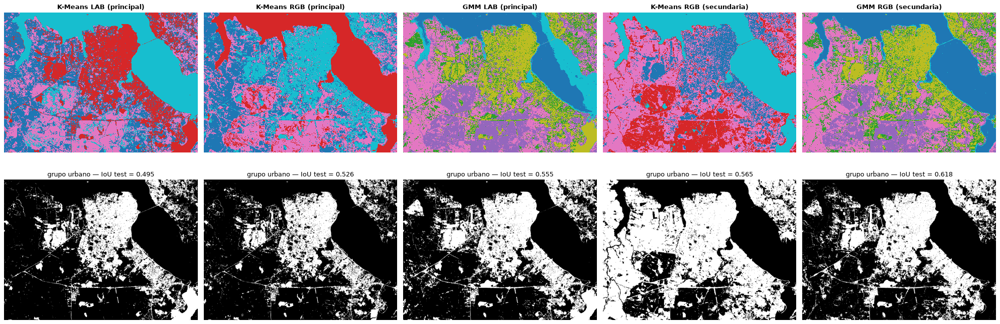

In [19]:
# 9. Clustering no supervisado
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

idx_ajuste = np.random.default_rng(SEMILLA).choice(H * W, 10000, replace=False)

def features_imagen(rgb, espacio):
    X = a_espacio(rgb.reshape(-1, 3), espacio)
    return StandardScaler().fit(X[idx_ajuste]).transform(X)

def grupos_urbanos(etiq_grupos):
    """Grupos mayoritariamente urbanos (> 50 % de píxeles OSM-urbano en los bloques de entrenamiento etiquetados).
    Si ninguno supera el 50 %, se toma el de mayor proporción."""
    sel = (~es_test & (etiquetas > 0)).ravel()
    prop = np.array([((etiquetas.ravel()[sel] == 1) & (etiq_grupos[sel] == g)).sum() / max((etiq_grupos[sel] == g).sum(), 1)
                     for g in range(etiq_grupos.max() + 1)])
    elegidos = np.flatnonzero(prop > 0.5)
    return (elegidos if len(elegidos) else np.array([prop.argmax()])), prop

def bic_gmm(X):
    modelos = {k: GaussianMixture(k, covariance_type="full", random_state=SEMILLA, max_iter=200).fit(X[idx_ajuste[:5000]])
               for k in range(3, 7)}
    bics = {k: m.bic(X[idx_ajuste[:5000]]) for k, m in modelos.items()}
    k_opt = min(bics, key=bics.get)
    return modelos[k_opt], k_opt, bics

t0 = time.time()
CLUSTERS = {}
esp_alternativo = "LAB" if CONFIG["principal"]["espacio"] != "LAB" else "RGB"
experimentos = [("K-Means", "principal", CONFIG["principal"]["espacio"]), ("K-Means", "principal", esp_alternativo),
                ("GMM", "principal", CONFIG["principal"]["espacio"]),
                ("K-Means", "secundaria", CONFIG["secundaria"]["espacio"]), ("GMM", "secundaria", CONFIG["secundaria"]["espacio"])]
for metodo, nombre, esp in experimentos:
    X = features_imagen(CONFIG[nombre]["rgb"], esp)
    if metodo == "K-Means":
        modelo, k = KMeans(4, random_state=SEMILLA, n_init=5).fit(X[idx_ajuste]), 4
        extra = ""
    else:
        modelo, k, bics = bic_gmm(X)
        extra = "  BIC: " + ", ".join(f"k={kk}: {v:,.0f}" for kk, v in bics.items())
    grupos = modelo.predict(X)
    g_urb, prop = grupos_urbanos(grupos)
    clave = f"{metodo} {esp} ({nombre})"
    CLUSTERS[clave] = grupos.reshape(H, W)
    MASCARAS[clave] = np.isin(grupos, g_urb).reshape(H, W)
    print(f"{clave:28s} k={k}  grupos urbanos={[int(g) for g in g_urb]}  proporción OSM-urbano por grupo={np.round(prop, 2)}{extra}")
print(f"Clustering completo en {time.time() - t0:.1f} s")

fig, axes = plt.subplots(2, len(CLUSTERS), figsize=(5 * len(CLUSTERS), 9), dpi=80)
for j, (clave, grupos) in enumerate(CLUSTERS.items()):
    axes[0, j].imshow(grupos, cmap="tab10", interpolation="nearest")
    axes[0, j].set_title(clave, fontweight="bold")
    axes[1, j].imshow(MASCARAS[clave], cmap="gray")
    axes[1, j].set_title(f"grupo urbano — IoU test = {iou_test(MASCARAS[clave]):.3f}")
    for ax in axes[:, j]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "09_clustering.png"), bbox_inches="tight")
plt.show()

### 9.1 Las tres preguntas del Notebook 1, con estos datos
El Notebook 1 de la cátedra cierra su sección de *clustering* (K-Means sobre una foto de frutas, en RGB, HSV y LAB) con tres preguntas: **¿se validan las hipótesis?**, **¿es K-Means adecuado para las distribuciones de los puntos?** y **¿se consiguen objetivos diferentes según el espacio de color?** Allá el resultado se juzga a ojo. Acá se repite el experimento sobre las dos composiciones ganadoras y se mide con el IoU contra OSM en los bloques de prueba:

- **K-Means en RGB, HSV y LAB**, como en el Notebook 1.
- **K-Means contra GMM con el mismo número de grupos** (k = 4 y k = 6). Arriba, K-Means usó k = 4 y el GMM k = 6 (elegido por BIC), así que la comparación mezclaba dos efectos: la forma de los grupos y cuántos son.
- **LAB sin estandarizar**, donde la distancia euclídea es la ΔE perceptual de la hipótesis 3. En el resto de la sección los canales se estandarizan, y eso cambia la distancia.
- **Qué agrupa K-Means (k = 4) en cada espacio** sobre la 7-6-4: brillo medio, matiz mediano y saturación media de cada grupo.

Estas máscaras no se suman a la validación de la sección 10.

In [20]:
# 9.1 El experimento del Notebook 1 sobre estos datos: K-Means en RGB, HSV y LAB, y K-Means contra GMM con el mismo k
from skimage import color

def mascara_de_grupos(grupos):
    return np.isin(grupos, grupos_urbanos(grupos)[0]).reshape(H, W)

def agrupar(X, metodo, k):
    if metodo == "K-Means":
        return KMeans(k, random_state=SEMILLA, n_init=5).fit(X[idx_ajuste]).predict(X)
    return GaussianMixture(k, covariance_type="full", random_state=SEMILLA, max_iter=200).fit(X[idx_ajuste[:5000]]).predict(X)

t0 = time.time()
filas = []
for nombre in ["principal", "secundaria"]:
    rgb = CONFIG[nombre]["rgb"]
    for esp in ["RGB", "HSV", "LAB"]:
        X = features_imagen(rgb, esp)
        fila = {"composición": f"{CONFIG[nombre]['combo']} ({nombre})", "espacio": esp}
        for metodo in ["K-Means", "GMM"]:
            for k in (4, 6):
                fila[f"{metodo} k={k}"] = iou_test(mascara_de_grupos(agrupar(X, metodo, k)))
        filas.append(fila)
    # LAB sin estandarizar (escala CIE de skimage): la distancia euclídea es la ΔE perceptual de la hipótesis 3
    X = color.rgb2lab(rgb.astype(np.float32) / 255).reshape(-1, 3)
    filas.append({"composición": filas[-1]["composición"], "espacio": "LAB sin estandarizar (ΔE)",
                  "K-Means k=4": iou_test(mascara_de_grupos(agrupar(X, "K-Means", 4)))})
tabla_91 = pd.DataFrame(filas).set_index(["composición", "espacio"])
print("IoU ↑ contra OSM en los bloques de prueba (grupo urbano: > 50 % de píxeles OSM-urbano en entrenamiento)")
display(tabla_91.style.format(precision=3, na_rep="—").background_gradient(cmap="Greens", axis=None))

# Qué separa K-Means (k = 4) en cada espacio, sobre la secundaria 7-6-4: grupos ordenados de más claro a más oscuro
rgb_s = CONFIG["secundaria"]["rgb"].reshape(-1, 3)
brillo = rgb_s.astype(np.float32).mean(axis=1)
hsv_s = convertir_crudo(rgb_s, "HSV").astype(np.float32)
filas = []
for esp in ["RGB", "HSV", "LAB"]:
    grupos = agrupar(features_imagen(CONFIG["secundaria"]["rgb"], esp), "K-Means", 4)
    g_urb, prop = grupos_urbanos(grupos)
    for orden, g in enumerate(sorted(range(4), key=lambda g: -brillo[grupos == g].mean()), 1):
        m = grupos == g
        filas.append({"espacio": esp, "grupo": orden, "% de la imagen": 100 * m.mean(), "% OSM-urbano": 100 * prop[g],
                      "brillo medio (0–255)": brillo[m].mean(), "matiz H mediano (0–179)": np.median(hsv_s[m, 0]),
                      "saturación S media (0–255)": hsv_s[m, 1].mean(), "¿urbano?": "sí" if g in g_urb else "no"})
print("\nGrupos de K-Means (k = 4) sobre 7-6-4, ordenados por brillo")
display(pd.DataFrame(filas).set_index(["espacio", "grupo"]).style.format(precision=0)
        .background_gradient(subset=["% OSM-urbano"], cmap="Reds", vmin=0, vmax=100))
print(f"Experimento completo en {time.time() - t0:.1f} s")

IoU ↑ contra OSM en los bloques de prueba (grupo urbano: > 50 % de píxeles OSM-urbano en entrenamiento)



Grupos de K-Means (k = 4) sobre 7-6-4, ordenados por brillo


Experimento completo en 4.8 s


#### Respuestas

**1. ¿Se validan las hipótesis?**

| Hipótesis del Notebook 1 | ¿Se cumple? | Evidencia (tablas de arriba) |
|---|---|---|
| **RGB:** K-Means mezcla color y brillo; separa un mismo color claro de uno oscuro | **Sí** | En la 7-6-4, los tres grupos de tierra tienen el **mismo matiz** (H ≈ 50) y sólo cambian en brillo: 199, 133 y 72. Son "rodajas" de brillo. Acá eso no es del todo malo: el brillo de esta composición es reflectancia SWIR y lo urbano refleja más, así que la rodaja más clara es 81 % urbana. La del medio, la de los barrios arbolados, queda mezclada (51 % urbana) |
| **HSV:** agrupa por matiz, con problemas por la circularidad del matiz y cerca de los grises | **En parte** | La circularidad no aparece porque el matiz entra como (cos H, sin H). Los grises sí: HSV es el único espacio que arma un grupo por color y no por brillo, uno **casi gris** (S ≈ 27, 13 % de la imagen, 64 % urbano: techos y pavimento). Su matiz mediano (21) no se parece al del resto (≈ 50) porque, sin saturación, H es ruido. IoU 0.517, menor que en RGB (0.565) |
| **LAB:** da los grupos más coherentes, por ser perceptualmente uniforme | **No con K-Means** | Con k = 4, LAB queda último o empatado último: 0.495 en la 6-4-5 y 0.424 en la 7-6-4, contra 0.526 y 0.565 en RGB. Sin estandarizar, con la ΔE real, tampoco mejora (0.493 y 0.450). La uniformidad de LAB está pensada para los colores que ve el ojo; acá los canales son SWIR, NIR y rojo mostrados en falso color, y una ΔE entre dos falsos colores no mide una diferencia de materiales. En la 7-6-4, LAB parte la zona mezclada en dos grupos de 39 % y 41 % urbano: ninguno supera el 50 % y se pierden los barrios arbolados |

**2. ¿Es K-Means adecuado para las distribuciones de los puntos?**

No es el modelo adecuado, como advierte la cátedra, pero reemplazarlo por un GMM sólo ayuda en algunas configuraciones:

- **Supone grupos esféricos y las nubes son alargadas** (sección 7). Por eso corta la nube por brillo en lugar de buscar un hueco entre coberturas.
- **Con el mismo k, el GMM no gana siempre.** De los 12 pares de la primera tabla, el GMM gana en 4, K-Means en 5 y empatan en 3 (diferencia menor a 0.01). K-Means gana, por ejemplo, en la 6-4-5 RGB (0.526 contra 0.438 con k = 4).
- **Pero los dos mejores resultados son del GMM**, ambos en la 7-6-4: RGB con k = 6 (0.618, contra 0.467 de K-Means) y LAB con k = 4 (0.602, contra 0.424). Cuando el GMM gana, gana por mucho. En la 7-6-4 RGB reparte la zona mezclada en un grupo 64 % urbano y otro 32 % urbano (salida de la sección 9), en lugar del único grupo de 51 % de K-Means, y su precisión sube de 0.61 a 0.78 (sección 10).
- **El límite está en los datos, no sólo en el algoritmo.** Entre lo urbano y la vegetación no hay un hueco sino un continuo: a 30 m, un barrio arbolado mezcla techo, calle y copa. Cualquier agrupamiento lo corta en algún lugar, y los grupos de esa zona quedan cerca del 50 % de OSM-urbano. Un grupo de 51 % entra en la máscara y uno de 49 % no, y por eso el IoU salta entre 0.42 y 0.62 al cambiar el espacio o el k. Diferencias de pocas centésimas no alcanzan para preferir un método.

**3. ¿Se consiguen objetivos diferentes según el espacio de color?**

Sí, aunque en esta imagen los tres espacios tienden a ordenar los grupos por brillo:

- **Qué separa cada espacio** (K-Means, k = 4, 7-6-4):
  - **RGB:** tres niveles de brillo del mismo matiz. El del medio, mezclado, entra como urbano: la máscara tiene mucho recall y menos precisión.
  - **LAB:** los mismos niveles, con los cortes en otro lugar. La zona media queda partida en dos grupos que no llegan al 50 %, y la máscara se reduce al núcleo denso (83 % urbano): IoU 0.424.
  - **HSV:** separa lo **gris** de lo **coloreado**. Es el único criterio cromático y no de brillo.
- **El mejor espacio cambia con el algoritmo y el k.** Con K-Means k = 4 gana RGB en las dos composiciones; con GMM k = 4 en la 7-6-4 gana LAB (0.602); con k = 6 en la 6-4-5 gana LAB con los dos métodos (0.553 y 0.555). No hay un espacio mejor para todo, igual que en el ranking de la sección 5.
- **Las bandas pesan tanto como el espacio:** los dos mejores resultados (0.618 y 0.602) son de la 7-6-4, que suma el SWIR 2.

### Conclusión 9
- **El GMM sobre 7-6-4 en RGB es el mejor método no supervisado** (IoU 0.618, F1 0.764). El BIC eligió **6 componentes**, y dos de ellas son urbanas (64 % y 84 % de píxeles OSM-urbano): una corresponde al tejido **denso** y otra al **arbolado**. En esta composición la covarianza completa sí marca la diferencia: K-Means con el mismo k = 6 llega sólo a 0.467 (ver 9.1).
- **K-Means** con k = 4 rinde algo menos (IoU 0.565 en 7-6-4 RGB y 0.526 en 6-4-5 RGB). Corta las nubes alargadas en "rodajas" de brillo, tal como anticipa la nota de la cátedra: en la 7-6-4, sus tres grupos de tierra tienen el mismo matiz, y la rodaja del medio, la de los barrios arbolados, queda 51 % urbana (ver 9.1).
- En la principal 6-4-5, el **GMM en LAB** (IoU 0.555) supera a **K-Means en LAB** con k = 4 (0.495), pero la ventaja viene sobre todo de usar más grupos: K-Means en LAB con k = 6 llega a 0.553 (ver 9.1).
- **Ninguno de estos métodos usó etiquetas para agrupar** y aun así superan a la umbralización de un canal. La estructura de las nubes de color ya contiene la información urbana; hace falta un modelo con la forma adecuada para aprovecharla.

### Bitácora — sección 9
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Algoritmos | K-Means (k = 4) y GMM con covarianza completa | GMM se adapta a nubes elípticas | Sólo K-Means | Supone grupos esféricos (Notebook 1) | Cátedra |
| Componentes del GMM | Elegidos con BIC entre 3 y 6 | Penaliza la complejidad | k fijo | Arbitrario | Métrica |
| Grupo urbano | Todos los grupos con > 50 % de píxeles OSM-urbano (en entrenamiento) | El GMM parte lo urbano en "denso" y "arbolado" | Sólo el de mayor proporción | Recall bajo (IoU 0.43 → 0.62 en 7-6-4) | Métrica |
| Ajuste | 10 000 píxeles; predicción sobre toda la imagen | Rápido | Ajustar con toda la imagen | Lento | Tiempo |
| Comparación K-Means–GMM (9.1) | Mismo k (4 y 6) en RGB, HSV y LAB | Separa el efecto de la forma de los grupos del de su cantidad | K-Means k = 4 contra GMM con k por BIC | Mezclaba los dos efectos y exageraba la ventaja del GMM en la 6-4-5 | Métrica |

## 10. Validación contra OpenStreetMap

Este es el control que sugirió tu compañero: **¿la máscara que produce cada método marca efectivamente lo urbano?** Se comparan las máscaras de umbralización automática (Otsu, cajas por percentiles y NDBI), la **caja manual** de la sección 8.3 y los agrupamientos (K-Means y GMM). Todas se comparan con OSM **sólo en los bloques de prueba**, que no se usaron para fijar ningún umbral ni para nombrar ningún grupo, y en dos versiones de la referencia:

- **(A) OSM completo:** todos los píxeles etiquetados. Penaliza a los métodos que no marcan como urbano los patios y arbolado dentro de los barrios, aunque desde el satélite sean vegetación.
- **(B) OSM puro:** sólo los píxeles puros, sin bordes mezclados. Mide la capacidad de separar las coberturas "limpias".

**Métricas:**

| Métrica | Qué responde |
|---|---|
| **IoU** (índice de Jaccard) | ¿cuánto se superpone la máscara con la referencia? |
| **F1** (coeficiente de Dice) | media armónica de precisión y recall |
| **Precisión** | de lo que el método marcó como urbano, ¿cuánto lo es? |
| **Recall** | de lo urbano real, ¿cuánto encontró? |

Caja manual usada: 171 ≤ L* ≤ 255 y 53 ≤ a* ≤ 149 y 90 ≤ b* ≤ 206


,método,tipo,IoU (A) ↑,F1 (A) ↑,Precisión (A) ↑,Recall (A) ↑,IoU (B) ↑,F1 (B) ↑,Precisión (B) ↑,Recall (B) ↑
0,GMM RGB (secundaria),no supervisado,0.618,0.764,0.783,0.746,0.666,0.800,0.866,0.743
1,Caja P5–P95 (secundaria),umbral automático,0.571,0.727,0.591,0.945,0.607,0.755,0.630,0.942
2,K-Means RGB (secundaria),no supervisado,0.565,0.722,0.614,0.875,0.592,0.744,0.649,0.872
3,GMM LAB (principal),no supervisado,0.555,0.714,0.735,0.694,0.581,0.735,0.788,0.688
4,Caja manual (principal),umbral manual,0.540,0.701,0.745,0.662,0.570,0.726,0.812,0.657
5,Caja manual corregida (principal),umbral manual,0.533,0.696,0.786,0.624,0.556,0.715,0.852,0.616
6,K-Means RGB (principal),no supervisado,0.526,0.689,0.825,0.591,0.551,0.711,0.909,0.584
7,Otsu (secundaria),umbral automático,0.525,0.689,0.687,0.691,0.541,0.702,0.720,0.684
8,Caja P5–P95 (principal),umbral automático,0.521,0.685,0.556,0.892,0.547,0.707,0.585,0.892
9,K-Means LAB (principal),no supervisado,0.495,0.662,0.761,0.586,0.510,0.675,0.818,0.575


↑ mayor es mejor · ↓ menor es mejor


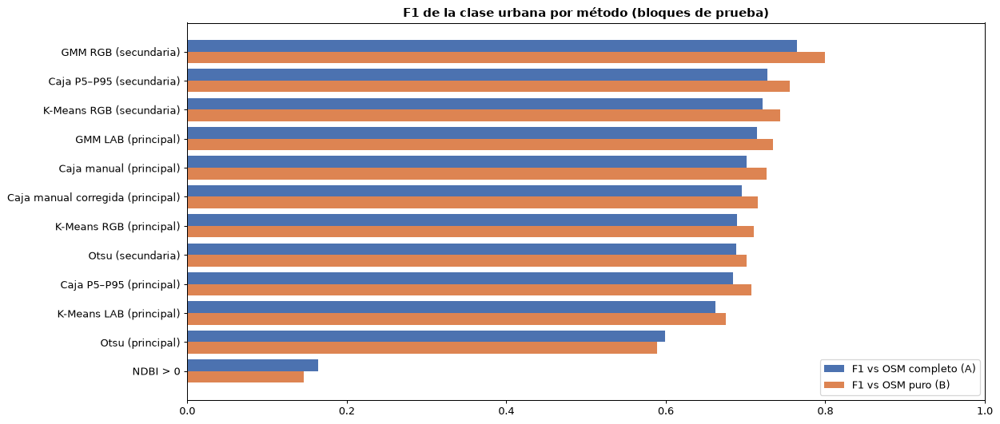

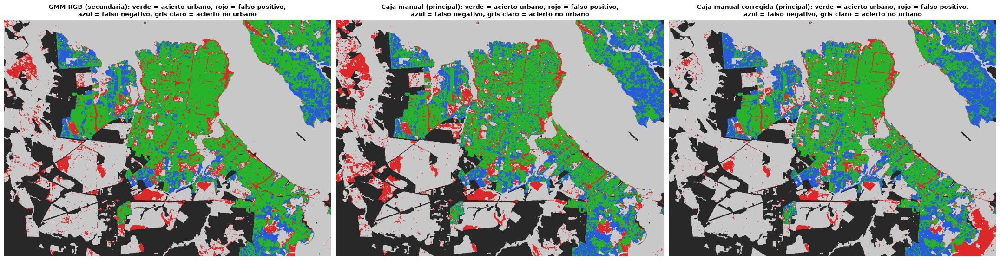

In [21]:
# 10. Comparación de todos los métodos contra OSM (bloques de prueba)
def metricas_vs(mascara, seleccion, referencia):
    y, p = referencia[seleccion], mascara[seleccion]
    return jaccard_score(y, p), f1_score(y, p), precision_score(y, p, zero_division=0), recall_score(y, p)

# La caja manual se toma con los valores que tengan AHORA los sliders de la sección 8.3:
# si se los mueve, alcanza con volver a ejecutar esta celda y la siguiente para actualizar la comparación.
MASCARAS["Caja manual (principal)"] = mascara_caja_manual()
print("Caja manual usada: " + " y ".join(f"{s.value[0]} ≤ {c} ≤ {s.value[1]}" for c, s in sliders.items()))

sel_a, sel_b = es_test & (etiquetas > 0), es_test & (puras > 0)
filas_val = []
for nombre, m in MASCARAS.items():
    ia, fa, pa, ra = metricas_vs(m, sel_a, etiquetas == 1)
    ib, fb, pb, rb = metricas_vs(m, sel_b, puras == 1)
    tipo = ("no supervisado" if nombre in CLUSTERS else "índice" if nombre.startswith("NDBI")
            else "umbral manual" if "manual" in nombre else "umbral automático")
    filas_val.append({"método": nombre, "tipo": tipo, "IoU (A)": ia, "F1 (A)": fa, "Precisión (A)": pa,
                      "Recall (A)": ra, "IoU (B)": ib, "F1 (B)": fb, "Precisión (B)": pb, "Recall (B)": rb})
df_val = pd.DataFrame(filas_val).sort_values("F1 (A)", ascending=False).reset_index(drop=True)
con_flechas(df_val).to_csv(os.path.join(IMG_DIR, "tabla_10_validacion_osm.csv"), index=False)
display(con_flechas(df_val).style.format(precision=3).background_gradient(
    subset=["IoU (A) ↑", "F1 (A) ↑", "IoU (B) ↑", "F1 (B) ↑"], cmap="Greens"))
print(LEYENDA)

fig, ax = plt.subplots(figsize=(14, 6), dpi=90)
pos = np.arange(len(df_val))
ax.barh(pos - 0.2, df_val["F1 (A)"], 0.4, label="F1 vs OSM completo (A)", color="#4c72b0")
ax.barh(pos + 0.2, df_val["F1 (B)"], 0.4, label="F1 vs OSM puro (B)", color="#dd8452")
ax.set_yticks(pos, df_val["método"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.legend()
ax.set_title("F1 de la clase urbana por método (bloques de prueba)", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "10_comparacion_metodos.png"), bbox_inches="tight")
plt.show()

# Mapa de aciertos y errores del mejor método automático y de la caja manual
def mapa_errores(m):
    viz = np.full((H, W, 3), 40, np.uint8)
    ref = etiquetas == 1
    con_dato = etiquetas > 0
    viz[con_dato & ref & m] = (40, 180, 40)      # verdadero positivo
    viz[con_dato & ~ref & m] = (220, 40, 40)     # falso positivo
    viz[con_dato & ref & ~m] = (40, 90, 220)     # falso negativo
    viz[con_dato & ~ref & ~m] = (200, 200, 200)  # verdadero negativo
    return viz

mejor_auto = df_val[df_val["tipo"] != "umbral manual"].iloc[0]["método"]
fig, axes = plt.subplots(1, 3, figsize=(27, 7.5), dpi=80)
for ax, nombre in zip(axes, [mejor_auto, "Caja manual (principal)", "Caja manual corregida (principal)"]):
    ax.imshow(mapa_errores(MASCARAS[nombre]))
    ax.set_title(f"{nombre}: verde = acierto urbano, rojo = falso positivo,\nazul = falso negativo, gris claro = acierto no urbano",
                 fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "10_mapa_errores.png"), bbox_inches="tight")
plt.show()

### 10.2 Área urbana en km²: OSM contra cada máscara

Una comparación más tangible que IoU o F1: **¿cuántos km² de urbanización da cada método y cuántos da OpenStreetMap?** Cada píxel de Landsat mide 30 m × 30 m = 900 m² = **0.0009 km²**, así que el área es la cantidad de píxeles marcados × 0.0009. Se calcula sobre **todo el recorte** (≈ 468 km²).

| Columna | Qué es |
|---|---|
| Área urbana total | todo lo que el método marca como urbano |
| Diferencia con OSM | área del método − área urbana de OSM (en km² y en %). Positiva = el método marca más que OSM |
| Coincide con OSM urbano ↑ | km² que el método y OSM marcan como urbano a la vez |
| Marca de más ↓ | km² que el método llama urbano y OSM llama vegetación o agua |
| Marca de menos ↓ | km² urbanos según OSM que el método no detectó |
| En zonas sin dato OSM | km² marcados donde OSM no tiene ninguna etiqueta (≈ 19 % del recorte); no se puede decir si están bien o mal |
| IoU en km² ↑ | coincide / (coincide + de más + de menos): el mismo IoU de antes, pero sobre todo el recorte con dato OSM y no sólo sobre los bloques de prueba. La tabla se ordena por esta columna |

> Dos cosas a tener en cuenta al leer los km²:
> - Que el **total** se parezca al de OSM no alcanza: un método puede acertar la cantidad de km² marcando lugares equivocados. Por eso se desglosan los aciertos, lo marcado de más y lo marcado de menos.
> - OSM tampoco es perfecto: sus polígonos residenciales incluyen patios y arbolado, y no incluye rutas ni caminos.

método,tipo,Área urbana total (km²),Diferencia con OSM (km²),Diferencia con OSM (%),Coincide con OSM urbano (km²) ↑,Marca de más (km²) ↓,Marca de menos (km²) ↓,En zonas sin dato OSM (km²),IoU en km² (zona con dato OSM) ↑
OpenStreetMap (referencia),referencia,139.9,0.0,0.0,139.9,0.0,0.0,0.0,1.000
GMM RGB (secundaria),no supervisado,155.9,16.1,11.5,106.3,32.1,33.5,17.5,0.618
Caja P5–P95 (secundaria),umbral automático,289.0,149.1,106.6,133.0,88.6,6.9,67.4,0.582
K-Means RGB (secundaria),no supervisado,258.2,118.4,84.6,123.7,75.3,16.2,59.2,0.575
GMM LAB (principal),no supervisado,150.2,10.3,7.4,98.2,36.9,41.7,15.1,0.555
Caja manual (principal),umbral manual,150.5,10.6,7.6,93.8,35.0,46.1,21.8,0.536
Caja P5–P95 (principal),umbral automático,290.3,150.4,107.5,125.8,96.0,14.1,68.5,0.533
Caja manual corregida (principal),umbral manual,122.4,-17.5,-12.5,88.2,25.6,51.6,8.5,0.533
K-Means RGB (principal),no supervisado,113.4,-26.5,-19.0,83.6,20.2,56.3,9.6,0.522
Otsu (secundaria),umbral automático,160.9,21.0,15.0,97.7,48.6,42.2,14.6,0.518


↑ mayor es mejor · ↓ menor es mejor


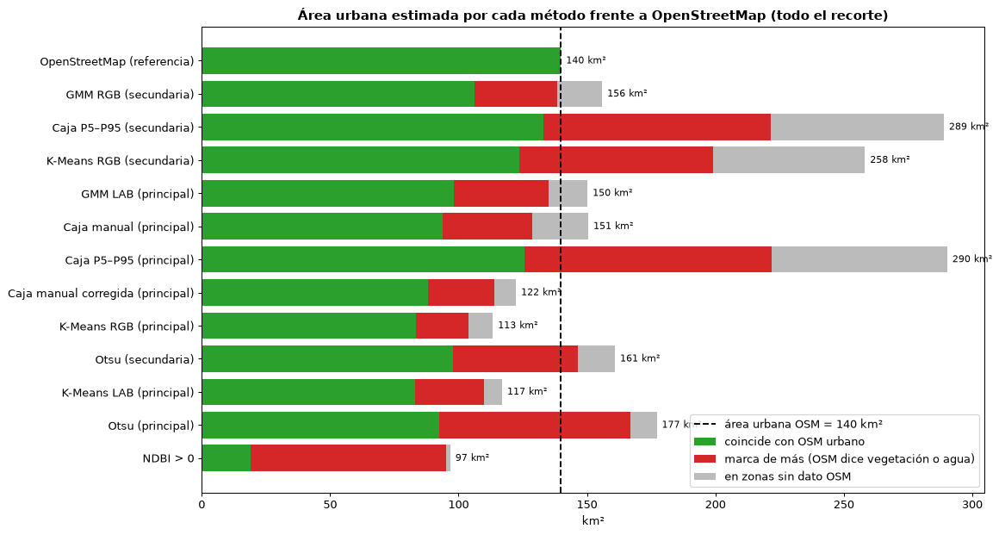

In [22]:
# 10.2 Área urbana (km²) de cada máscara frente a OSM, sobre todo el recorte
osm_urbano, con_dato = etiquetas == 1, etiquetas > 0
tipo_de = dict(zip(df_val["método"], df_val["tipo"]))
filas_area = [{"método": "OpenStreetMap (referencia)", "tipo": "referencia", "Área urbana total (km²)": AREA_OSM,
               "Diferencia con OSM (km²)": 0.0, "Diferencia con OSM (%)": 0.0,
               "Coincide con OSM urbano (km²)": AREA_OSM, "Marca de más (km²)": 0.0,
               "Marca de menos (km²)": 0.0, "En zonas sin dato OSM (km²)": 0.0}]
for nombre, m in MASCARAS.items():
    total = m.sum() * KM2_PIXEL
    filas_area.append({
        "método": nombre, "tipo": tipo_de[nombre], "Área urbana total (km²)": total,
        "Diferencia con OSM (km²)": total - AREA_OSM, "Diferencia con OSM (%)": 100 * (total / AREA_OSM - 1),
        "Coincide con OSM urbano (km²)": (m & osm_urbano).sum() * KM2_PIXEL,
        "Marca de más (km²)": (m & con_dato & ~osm_urbano).sum() * KM2_PIXEL,
        "Marca de menos (km²)": (~m & osm_urbano).sum() * KM2_PIXEL,
        "En zonas sin dato OSM (km²)": (m & ~con_dato).sum() * KM2_PIXEL})
df_area = pd.DataFrame(filas_area)
# IoU en km² sobre la zona con dato OSM: coincidencia / (coincidencia + de más + de menos)
df_area["IoU en km² (zona con dato OSM)"] = df_area["Coincide con OSM urbano (km²)"] / (
    df_area["Coincide con OSM urbano (km²)"] + df_area["Marca de más (km²)"] + df_area["Marca de menos (km²)"])
df_area = pd.concat([df_area.head(1), df_area.iloc[1:].sort_values("IoU en km² (zona con dato OSM)", ascending=False)])
df_area = df_area.rename(columns={"Coincide con OSM urbano (km²)": "Coincide con OSM urbano (km²) ↑",
                                  "Marca de más (km²)": "Marca de más (km²) ↓",
                                  "Marca de menos (km²)": "Marca de menos (km²) ↓",
                                  "IoU en km² (zona con dato OSM)": "IoU en km² (zona con dato OSM) ↑"})
df_area.to_csv(os.path.join(IMG_DIR, "tabla_10_area_km2.csv"), index=False)
display(df_area.style.format(precision=1).format(precision=3, subset=["IoU en km² (zona con dato OSM) ↑"])
        .hide(axis="index")
        .background_gradient(subset=["Coincide con OSM urbano (km²) ↑", "IoU en km² (zona con dato OSM) ↑"], cmap="Greens")
        .background_gradient(subset=["Marca de más (km²) ↓", "Marca de menos (km²) ↓"], cmap="Reds")
        .background_gradient(subset=["Diferencia con OSM (%)"], cmap="RdBu_r", vmin=-100, vmax=100))
print(LEYENDA)

# Barras apiladas: coincidencia + marcado de más + zonas sin dato = área total; línea = área urbana de OSM
d = df_area.iloc[::-1]
pos = np.arange(len(d))
fig, ax = plt.subplots(figsize=(13, 7), dpi=90)
ax.barh(pos, d["Coincide con OSM urbano (km²) ↑"], color="#2ca02c", label="coincide con OSM urbano")
ax.barh(pos, d["Marca de más (km²) ↓"], left=d["Coincide con OSM urbano (km²) ↑"], color="#d62728",
        label="marca de más (OSM dice vegetación o agua)")
ax.barh(pos, d["En zonas sin dato OSM (km²)"],
        left=d["Coincide con OSM urbano (km²) ↑"] + d["Marca de más (km²) ↓"], color="#bbbbbb",
        label="en zonas sin dato OSM")
ax.axvline(AREA_OSM, color="black", ls="--", lw=1.5, label=f"área urbana OSM = {AREA_OSM:.0f} km²")
for p, total in zip(pos, d["Área urbana total (km²)"]):
    ax.text(total + 2, p, f"{total:.0f} km²", va="center", fontsize=9)
ax.set_yticks(pos, d["método"])
ax.set_xlabel("km²")
ax.set_title("Área urbana estimada por cada método frente a OpenStreetMap (todo el recorte)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "10_area_km2.png"), bbox_inches="tight")
plt.show()

### Conclusión 10
- **Ranking frente a OSM (F1 contra OSM completo / OSM puro, bloques de prueba):**
  1. **GMM sobre 7-6-4 en RGB: 0.76 / 0.80**, el mejor método. No usa etiquetas para agrupar y se adapta a las nubes alargadas.
  2. Caja por percentiles 7-6-4 y K-Means 7-6-4: ≈ 0.72–0.73 / 0.74–0.76.
  3. GMM LAB, K-Means, cajas de la principal 6-4-5 y las **dos cajas manuales** (ajuste propio 0.70 / 0.73, corregida 0.70 / 0.71): ≈ 0.66–0.71.
  4. Otsu: 0.60–0.69.
  5. NDBI > 0: 0.16.
- **Las dos cajas manuales:**
  - **Ajuste propio con los sliders** (171 ≤ L\* ≤ 255, 53 ≤ a\* ≤ 149, 90 ≤ b\* ≤ 206): IoU **0.540** y F1 0.70, la **mejor umbralización de la principal** y la quinta de los 12 métodos. Precisión 0.745 y recall 0.662: encuentra más ciudad que la corregida, a costa de algo más de campo. La sección 8.4 lo diagnostica canal por canal.
  - **Ajuste corregido con los histogramas por clase** (L\* ∈ [150, 255], a\* ∈ [0, 126], b\* libre): IoU 0.533 y F1 0.70. Es la **umbralización más precisa** (79 % de lo marcado es urbano, contra 75 % del ajuste propio y 56 % de la caja automática), pero encuentra menos ciudad (recall 0.624).
  - **Las dos superan a la caja automática y a Otsu de la principal**, aunque no al GMM. **Lección:** un ajuste manual funciona si se guía por una medida, el IoU en vivo o los histogramas por clase; el primer intento, hecho sólo mirando la imagen, quedó vacío.
- **Todos los métodos mejoran contra OSM puro.** Parte del "error" contra OSM completo no es del método, sino de la referencia: los polígonos residenciales incluyen patios y arbolado que el satélite ve, correctamente, como vegetación.
- **En el mapa de errores, muchos falsos positivos (rojo) son rutas y caminos**, como la RN 12 y las trazas que cruzan las plantaciones del sur. OSM no los cuenta como `landuse` urbano, pero son **infraestructura civil**, que es justamente lo que pide la consigna. Esos falsos positivos son en realidad aciertos que la referencia no registra.
- Los falsos negativos (azul) se concentran en **Encarnación** (NE) y en los barrios periféricos más arbolados. Ahí el píxel de 30 m es mayormente copa de árbol.
- **Respuesta a tu compañero:** sí, la máscara marca lo buscado, con límites. Con el mejor método (GMM sobre 7-6-4), el **87 % de lo que marca como urbano lo es** (precisión sobre píxeles puros) y encuentra el **74 % de lo urbano**. Los errores restantes se explican por la resolución, por el suelo descampado que se parece a lo urbano y por cómo está etiquetado OSM.

**En km² (sección 10.2).** OSM marca **140 km² urbanos** de los 468 km² del recorte (30 %).
- **GMM sobre 7-6-4:** el más equilibrado. Estima **156 km²** (+11 %) y coincide con OSM en **106 km²**, es decir, encuentra el **76 % de la mancha urbana de OSM**. Marca de más 32 km² y de menos 34 km² (IoU en km² 0.62).
- **GMM sobre 6-4-5 en LAB:** el total más parecido a OSM (150 km², +7 %, igual que la caja manual), pero coincide en menos superficie que el GMM 7-6-4 (98 km²). Un total cercano no garantiza acertar el lugar.
- **Cajas por percentiles automáticas:** **duplican el área** (≈ 290 km², +107 %). Encuentran casi toda la ciudad (126–133 km² coincidentes), pero suman ~90 km² de campo y ~68 km² en zonas sin dato OSM. Es el costo de su recall alto.
- **Caja manual (ajuste propio):** **150.5 km²** (+7.6 %). Coincide con OSM en 94 km², marca 35 km² de más y deja afuera 46 km² (IoU en km² 0.54).
- **Caja manual corregida:** **122 km²** (−12.5 %). Coincide con OSM en 88 km², marca sólo 26 km² de más (el menor sobrante de todas las umbralizaciones) y deja afuera 52 km² de barrios arbolados.
- **K-Means en la principal:** subestima (113–117 km², −16 a −19 %). Se le escapa ~56 km² de ciudad, sobre todo los barrios arbolados.
- **NDBI > 0:** da 97 km², pero sólo 19 coinciden con lo urbano. El resto es, sobre todo, **el río**.
- Lo que cada método marca en **zonas sin dato OSM** (de 1.5 a 68 km²) no se puede evaluar. Pueden ser barrios o caminos que OSM no tiene cargados, o errores.

### Bitácora — sección 10
| Bloque | Opción elegida | Por qué | Alternativa descartada | Problema que tenía | Criterio |
|---|---|---|---|---|---|
| Referencia | OSM completo (A) y OSM puro (B) | Separa el error del método del error de la referencia | Sólo OSM completo | Castiga como error el arbolado dentro de los barrios | Métrica |
| Ámbito de las métricas | Sólo los bloques de prueba | No se usaron para fijar umbrales ni nombrar grupos | Toda la imagen | Favorece a los métodos que "vieron" esos píxeles | Buenas prácticas de validación |
| Caja manual | Se toma con los valores actuales de los sliders | Permite comparar el ajuste manual contra los automáticos | Dejarla sólo como visualización | No había forma de medir el ajuste manual | Pedido |
| Caja manual corregida | Segunda caja fija (`AJUSTE_CORREGIDO`), guiada por los histogramas por clase | Muestra qué cambia al ajustar mirando las distribuciones y no la imagen | Reemplazar el ajuste propio | Se perdía la comparación entre ambos criterios | Métrica |
| Área | km² sobre todo el recorte, desglosados en coincidencia, de más, de menos y sin dato | Medida tangible y comparable con OSM | Sólo el área total | Un total igual no garantiza acertar el lugar | Métrica |
| Mapa de errores | Verdaderos positivos, falsos positivos y falsos negativos sobre el mapa | Muestra dónde se equivoca cada método | Sólo números | Revela rutas como "falsos" positivos | Visual |

## 11. Conclusiones finales

**Lo que mostraron las firmas espectrales (sección 1).** En zonas de muestra elegidas sobre la imagen, la urbanización es la cobertura más brillante en el visible y en el SWIR 2, refleja menos que la vegetación en el NIR y es la más heterogénea.
- La mejor banda para separarla de la **vegetación** es **B7 (SWIR 2)**, seguida de B5 y B4.
- La mejor para separarla del **agua** es **B6 (SWIR 1)**.
- El **suelo descampado** (tierra colorada) es su principal confusión: sólo el NIR lo separa algo.

Todo lo que sigue en el notebook es coherente con esa lectura de los datos crudos.

**¿Las bandas 4, 5 y 6 cumplen el objetivo?** Sí, con matices.
- Separan **perfectamente el agua** (JM = 2.0), algo que el color natural no logra (1.51).
- Diferencian lo construido de la vegetación con una exactitud de ~0.75–0.76 usando sólo 3 canales.
- La mejor variante fue **6-4-5 en LAB con ecualización**: SWIR 1 en rojo, rojo en verde y NIR en azul, con lo urbano en verde-amarillo sobre vegetación violeta.
- En RGB **el orden de las bandas no cambia la separabilidad, sólo la percepción**. El orden importa recién al llevar la imagen a espacios no lineales (LAB, HSV, HLS) o a escala de grises.

**Rol de la 7-6-4.** La composición "falso color urbano" de la tabla de la cátedra fue la **mejor para urbano–vegetación**: k-NN 0.796, JM hasta 1.41, con el agua igual de bien separada. Además, su GMM fue el mejor método no supervisado. El SWIR 2 distingue materiales secos de vegetación húmeda mejor que el NIR, sobre todo en una ciudad tan arbolada como Posadas. **Recomendación de optimización:** reemplazar el NIR por SWIR 2, o sumarlo como cuarto canal.

**Mejora de contraste.**
- Sin realce, la imagen es casi ilegible (contraste RMS 19–37), así que para **mostrar** el realce es imprescindible.
- Frente a esa línea base, el estiramiento y la ecualización mejoran la exactitud k-NN apenas +0.002 a +0.026.
- CLAHE la empeora hasta −0.044.
- Todos los realces bajan el JM.
- Conclusión: el realce sirve para mostrar, no para clasificar.

**Segmentación.** Ningún método simple alcanza la referencia OSM:
- La mejor máscara es la del **GMM sobre 7-6-4** (F1 0.76 contra OSM completo; 156 km² estimados contra 140 de OSM).
- Las umbralizaciones de un canal y las cajas encuentran la ciudad, pero **también marcan campo**.
- La **caja manual** ajustada con los sliders, mirando el IoU y los km² en vivo, llega a **IoU 0.540** y **150.5 km²** (OSM: 140): es la mejor umbralización de la principal. La versión **guiada por los histogramas por clase** (IoU 0.533) es la más precisa (79 %). Un primer ajuste hecho sólo mirando la imagen había dado una máscara vacía, con a\* sobre los tonos de la vegetación. Elegir los umbrales con una **medida**, sea el IoU o las distribuciones de cada clase, es más confiable que ajustarlos a ojo.

**Métricas.** Fisher y Silhouette (euclídeas, con supuestos de medias y esfericidad) **subestiman** la separabilidad cuando las nubes son alargadas o multimodales. JM, con covarianza completa, y k-NN, no paramétrico, dan una lectura más fiel. El Borda combina todas sin que ninguna decida sola. Las **etiquetas puras y la comparación por pares** importaron tanto como la elección de métrica.

**Desafíos.**
1. **Píxeles mezclados:** techo, calle y árbol dentro de 30 m. Es el límite principal de todos los métodos.
2. **Etiquetas de referencia imperfectas:** OSM no incluye rutas como uso urbano e incluye patios dentro de lo residencial.
3. **Índices "de manual" que no transfieren:** NDBI > 0 falla en una ciudad subtropical arbolada.
4. **Desfase geométrico:** se corrigió proyectando a UTM; la interpolación lineal de lat/lon desplazaba hasta ~200 m.

**¿Alcanza la resolución espacial de 30 m?**
- Alcanza para **delimitar la mancha urbana**, barrios, grandes equipamientos (aeropuerto, costanera, puente) y **rutas principales** (RN 12, avenidas anchas).
- **No alcanza** para calles angostas, manzanas individuales ni viviendas. Una vivienda típica (~10 × 15 m) ocupa una fracción de un píxel.
- Mejoras posibles:
  - Fusión pancromática (*pan-sharpening*) con la **banda 8 a 15 m**.
  - Sensores de mayor resolución, como Sentinel-2 (10 m).
  - Incorporar textura espacial (el vecindario del píxel), que distingue la trama regular de la ciudad del campo aunque tengan colores parecidos.

## 12. Figuras del informe
Esta sección exporta a `img/ejercicio1/` las figuras que usa el informe (`partes/ejercicio1.tex`), en PDF y con su tipografía: letra Times, ancho del texto y sin títulos, porque el título va en el epígrafe de LaTeX. Reutiliza los resultados de las secciones anteriores.

Queda desactivada (`EXPORTAR_FIGURAS = False`) para que ejecutar el notebook no reescriba los PDF del repositorio. Para regenerarlos se cambia a `True` y se ejecuta todo el notebook.

In [23]:
# 12. Figuras del informe: PDF con la tipografía de partes/ejercicio1.tex, sin títulos (van en el caption)
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter

# Queda apagado para que ejecutar el notebook no reescriba los PDF del repositorio: activarlo sólo para regenerarlos
EXPORTAR_FIGURAS = False
DIR_FIG = os.path.join("..", "..", "img", "ejercicio1")
ANCHO = 483.69687 / 72.27   # \linewidth del informe en pulgadas (≈ 6.69 in)
ESTILO_INFORME = {
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"], "mathtext.fontset": "stix",
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
    "figure.constrained_layout.use": True, "figure.constrained_layout.w_pad": 0.02,
    "figure.constrained_layout.h_pad": 0.02, "figure.constrained_layout.wspace": 0.02,
    "figure.constrained_layout.hspace": 0.02,
}
LEYENDA_ERRORES = [Patch(color=np.array(rgb) / 255, label=rot) for rgb, rot in [
    ((40, 180, 40), "acierto urbano"), ((220, 40, 40), "urbano de más"), ((40, 90, 220), "urbano de menos"),
    ((200, 200, 200), "acierto no urbano"), ((40, 40, 40), "sin dato OSM")]]

def coma(valor, decimales=2):
    return f"{valor:.{decimales}f}".replace(".", ",")

def panel(ax, img, rotulo, **kwargs):
    # Imagen sin ejes, con el rótulo "(a) …" debajo
    ax.imshow(img, **kwargs)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(rotulo)

def guardar_informe(fig, nombre):
    # Sin fecha de creación: si la figura no cambió, el PDF es idéntico y git no lo marca
    fig.savefig(os.path.join(DIR_FIG, f"{nombre}.pdf"), metadata={"CreationDate": None})
    plt.close(fig)
    print("Exportada:", os.path.join(DIR_FIG, f"{nombre}.pdf"))

if not EXPORTAR_FIGURAS:
    print("Exportación de figuras desactivada (EXPORTAR_FIGURAS = False).")
else:
    os.makedirs(DIR_FIG, exist_ok=True)
    letras = "abcdefghij"
    with plt.rc_context(ESTILO_INFORME):
        # Zonas de muestra y firmas espectrales (sección 1)
        fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(ANCHO, 2.75), width_ratios=[1.1, 1])
        panel(ax_a, np.dstack([estirar(REFL[b]) for b in (4, 3, 2)]), "(a) Zonas de muestra sobre la 4-3-2")
        for clase, zonas in MUESTRAS.items():
            for _, (f0, f1, c0, c1) in zonas:
                ax_a.add_patch(Rectangle((c0, f0), c1 - c0, f1 - f0, fill=False, ec=COLOR_MUESTRA[clase], lw=1.4))
        x = np.array(BANDAS)
        for x0, x1, gris in [(0.5, 4.5, 0.06), (4.5, 5.5, 0.14), (5.5, 7.5, 0.06)]:
            ax_b.axvspan(x0, x1, color="0.5", alpha=gris, lw=0, zorder=0)
        for c in MUESTRAS:
            ax_b.errorbar(x, MEDIA[c], yerr=DESVIO[c], color=COLOR_MUESTRA[c], lw=1.2, ms=3.5, capsize=2,
                          elinewidth=0.8, label=c, **ESTILO_MUESTRA[c])
        ax_b.set_xticks(x, [f"B{b}" for b in BANDAS])
        ax_b.set_xlim(0.5, 7.5)
        ax_b.set_ylim(bottom=0)
        ax_b.set_ylabel("Reflectancia")
        ax_b.yaxis.set_major_formatter(FuncFormatter(lambda v, _: coma(v)))
        ax_b.set_xlabel("(b) Firmas espectrales (media ± desvío)")
        ax_b.grid(axis="y", alpha=0.4)
        ax_b.legend(fontsize=8, loc="upper left")
        guardar_informe(fig, "zonas_firmas")

        # Las 8 composiciones con estiramiento 2–98 % (sección 3)
        fig, axes = plt.subplots(2, 4, figsize=(ANCHO, 2.75))
        for i, (ax, (combo, img)) in enumerate(zip(axes.flat, IMAGENES.items())):
            panel(ax, img, f"({letras[i]}) {combo}")
        guardar_informe(fig, "composiciones")

        # Aciertos y errores contra OSM (sección 10)
        fig, axes = plt.subplots(1, 2, figsize=(ANCHO, 2.75))
        for i, (ax, clave, rotulo) in enumerate(zip(axes, ["GMM RGB (secundaria)", "Caja manual (principal)"],
                                                    ["GMM sobre 7-6-4", "caja manual sobre 6-4-5"])):
            panel(ax, mapa_errores(MASCARAS[clave]), f"({letras[i]}) {rotulo}")
        # Leyenda centrada debajo de los paneles (bbox "tight" la incluye al guardar)
        fig.legend(handles=LEYENDA_ERRORES, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=5, frameon=False,
                   fontsize=8)
        guardar_informe(fig, "mapa_errores")

Exportación de figuras desactivada (EXPORTAR_FIGURAS = False).


In [24]:
print(f"Tiempo total de ejecución: {time.time() - T_INICIO:.1f} s")

Tiempo total de ejecución: 52.8 s
